# T1-4c: Pure Strain — Spatial Refinement Study

## Verification Study — Tier 1 / Trivial Trajectories

**Goal:** refine the grid and check whether the interpolation and trajectory errors of the three lateral
interpolation schemes of **T1-4b** decay towards machine precision ($\sim 10^{-16}$).

| Scheme | Data location | Interpolator | Expected order in space |
|---|---|---|---|
| barycentric (node) | `n_node` | `UxLinearNodeConstantZC` (Parcels built-in) | 2 (exact for linear fields) |
| constant (face) | `n_face` | `UxConstantFaceConstantZC` (Parcels built-in) | 1 |
| least-squares (face) | `n_face` | `LinearFaceRecon` (custom, copied verbatim from T1-4b) | 2 (exact for linear fields) |

The study has two parts:

* **Part A — pure strain** $u=\varepsilon x,\ v=-\varepsilon y$ (the T1-4/T1-4b flow, as requested).
  The field is *linear*, so barycentric and least-squares interpolation are exact at *every* resolution;
  only the constant-face scheme has a spatial error, $O(\Delta x)$. We measure (i) the direct interpolation
  error at random interior points and (ii) the RK4 trajectory error at a fixed, very small $\Delta t$.
* **Part B — a smooth nonlinear (cellular) field** $u = U_0\sin kx\cos ky,\ v=-U_0\cos kx\sin ky$, for which every
  scheme has a genuine truncation error. Direct interpolation error (true spatial convergence orders, extrapolation
  to $10^{-16}$), stream-function drift and, new in v2, the trajectory error against a DOP853 reference (Section 6b).

**Known limitation (Parcels, not this notebook):** `UxGrid.search` (`parcels/_core/uxgrid.py`) casts the particle
coordinates to `float32` and returns the barycentric weights in `float32`. The barycentric *node* scheme therefore
has a relative error floor of order the float32 machine epsilon ($\approx 1.2\times10^{-7}$), independent of resolution.
It cannot reach $10^{-16}$ on any grid. This floor is shown below and marked as such; it is not a failure of the test.
The face schemes only use the *face index* from the search and evaluate in float64, so they are not affected.

### Changelog (v2 relative to `T1-4c_pure_strain_spatial_refinement.ipynb`)

1. **Stream-function sign convention** (Section 2b): oceanographic convention $u=-\partial_y\psi,\ v=\partial_x\psi$.
   Cellular flow $\psi=-(U_0/k)\sin kx\sin ky$ (velocity unchanged), new pure-strain $\psi=-\varepsilon xy$. A
   finite-difference assertion checks both against `strain_uv` / `cellular_uv`. The $\psi$-drift values are confirmed
   unchanged (bitwise, and against the v1 table).
2. **Mesh + hyperbolic $\psi$ overlay** (Section 2b) for $N_X=10,20,40$; $\psi$ contours added under the Part A
   trajectory panels; Part B panels use the corrected $\psi$. The `#plot the stream function underneath` TODO is resolved.
3. **CFL diagnostics** (Section 6d): per-cell length (shortest edge; $\sqrt{2A}$), per-cell speed (centroid; max over
   nodes), CFL tables over all cells and over visited cells for every (flow, $N_X$, $\Delta t$) actually run,
   particle-based CFL per run, $|\nabla u|\Delta t$, histograms, CFL > 1 flagged.
4. **Status codes / out-of-bounds / search checks** (Section 6e): `StatusCode` counts after every `pset.execute`
   (also in the results tables), every recorded position checked to be inside $[-5,5]^2$ and inside a triangle,
   missing corner triangles reported per $N_X$ (Section 2).
5. **Converged answer per resolution** (Section 6c): $\Delta t$-halving sequence on $N_X\in\{10,40,160,640\}$ starting
   at CFL$_\max\le0.5$, plus fixed-CFL vs fixed-$\Delta t$ comparison. **Deviation from the request:** the halving stops at
   the notebook time step (0.5 s Part A, 10 s Part B) instead of continuing to $10^{-3}$ s, to keep the whole notebook
   within a 5-10 min run (decided by the user); the change over the last halving is reported as the time-error estimate.
6. **Part B trajectory error vs a DOP853 reference** (Section 6b): 500 random particles, error and $\psi$ drift vs
   $\Delta x$, slopes for $N_X\ge80$.
7. **Check 4c** stays a FAIL (threshold unchanged); the notebook no longer ends with an uncaught `AssertionError` for it.
   Follow-up study with 2000 particles, bootstrap CI and cells crossed per particle (Section 6f).
8. **Timing** (Section 6g): all wall times labelled implementation-dependent; search vs interpolation timing on
   $10^5$ points; cached-array `LinearFaceRecon` variant proposed and checked bit-identical (not used in the runs).
9. **Units**: the mesh is `mesh="flat"`, so "deg" / "degrees/s" became "length units" / "length units/s".
10. **Error taxonomy** cell below.

**Implementation note.** `LinearFaceRecon` is unchanged (verbatim from v1). All trajectories are still plain
`pset.execute(AdvectionRK4)` runs. Independent runs are executed concurrently in forked worker processes, and a small
`Recorder` kernel stores the positions at every step (used for CFL, out-of-bounds checks and cells crossed); this
replaces the chunked `execute` calls of v1 and gives identical positions.

### Error taxonomy (used throughout)

1. **Direct interpolation error** — velocity error at fixed random points, $|\mathbf{u}_\text{interp}-\mathbf{u}_\text{exact}|$,
   normalised by $\max|\mathbf{u}_\text{exact}|$ over the points; reported as max and RMS.
2. **Trajectory position error at final time** — $|\mathbf{x}(T)-\mathbf{x}_\text{ref}(T)|$ in length units, against the
   analytical position (Part A) or a DOP853 reference trajectory of the analytical field (Part B); mean and max over particles.
3. **Invariant drift** ($\psi$ drift) — $\max_t|\psi(\mathbf{x}(t))-\psi(\mathbf{x}_0)|$, normalised by $U_0/k$ (Part B).
   The exact flow conserves $\psi$ along trajectories, so any drift is numerical.
4. **Time-integration error** — the RK4 part of 2., estimated from the $\Delta t$ studies (Sections 4 and 6c) as the change of
   the final positions under halving of $\Delta t$.
5. **Round-off / precision floor** — float64 eps $=2.2\times10^{-16}$ (relative) and the ulp of the coordinates; Parcels
   `UxGrid.search` casts positions to float32 and returns float32 barycentric weights, a floor of
   $\sim1.2\times10^{-7}$ relative for the barycentric node scheme.
6. **Search / out-of-bounds failures** — particles that end in a state other than `Success`/`EndofLoop`, or positions outside
   $[-5,5]^2$ or outside the triangulation (Section 6e).

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")       # one thread per worker process (runs are executed concurrently)
os.environ["NUMBA_THREADING_LAYER"] = "workqueue"   # numba's OpenMP layer aborts in forked worker processes
import multiprocessing as mp
import pickle
import shutil
import tempfile
import time
import warnings

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import uxarray as ux
import xarray as xr
from scipy.integrate import solve_ivp

import parcels
from parcels._core.particle import get_default_particle
from parcels._core.statuscodes import StatusCode

# Parcels' default Particle stores positions in float32; use float64 positions throughout.
Particle64 = get_default_particle(np.float64)
from uxarray.constants import INT_FILL_VALUE
from parcels.interpolators._base import ScalarInterpolator

EPS64 = np.finfo(np.float64).eps   # 2.2e-16
EPS32 = np.finfo(np.float32).eps   # 1.2e-7
STATUS_NAME = {v: k for k, v in vars(StatusCode).items() if isinstance(v, int)}
NOTEBOOK_T0 = time.time()

## 1. Parameters

**Resolution sweep.** The grid is the T1-4b Delaunay triangulation of an $N_X\times N_X$ point lattice on
$[-5,5]^2$, with $N_X \in \{10, 20, 40, 80, 160, 320, 640\}$, i.e. node spacing $\Delta x = 10/(N_X-1)$ from
1.1 down to 0.016 (a factor 71). Prototyping showed that the run time per trajectory integration is dominated by the
per-step kernel overhead and is almost independent of the grid size (grid building takes ~6 s at $N_X=640$),
so the full range up to $N_X=640$ (~0.8 M triangles) is affordable. It also hardly depends on the number of particles,
so the extra particles of Sections 6b and 6f ride along in the same runs.

**Time step for the trajectories (Part A).** We want the RK4 time-truncation error to be negligible compared with the
spatial error of every scheme, including the least-squares scheme whose spatial error is at round-off level.
From T1-4b (least-squares + RK4, near-origin particles, $T=2520$ s) the mean position error was
$1.8\times10^{-11}$ ($\Delta t=5$ s), $3.4\times10^{-14}$ (1 s), $4.9\times10^{-16}$ (0.5 s), and then *rose* again to
$\sim5\times10^{-15}$ for 0.25/0.125 s because round-off accumulates over more steps. RK4 global error scales as
$\Delta t^4 \cdot T$, so on the shorter $T=360$ s used here it is ~7x smaller still. We therefore use
**$\Delta t = 0.5$ s, $T=360$ s (720 RK4 steps)**: the time error is $\lesssim10^{-16}$, below float64 round-off,
and a run costs ~8-19 s (implementation-dependent wall time, see Section 6g). Section 4 re-checks this choice at $N_X=40$.

$T=360$ s with all 18 T1-4 particles (near / mid / far) keeps every particle inside the domain
($x(T) \le 3\,e^{0.36} = 4.3$).

In [2]:
# Domain (centered at origin = stagnation point)
HALF = 5.0
LON_MIN, LON_MAX = -HALF, HALF
LAT_MIN, LAT_MAX = -HALF, HALF

NX_VALUES = [10, 20, 40, 80, 160, 320, 640]
DX = {nx: (LON_MAX - LON_MIN) / (nx - 1) for nx in NX_VALUES}

# Part A: pure strain
EPSILON = 1e-3  # s^{-1}

# Part B: smooth nonlinear cellular flow, two wavelengths across the domain
U0 = 1e-3                    # length units/s (mesh='flat', nondimensional length)
K_WAVE = 2 * np.pi / 5.0     # wavelength 5 -> 2 wavelengths in [-5, 5]

# Trajectories (Part A)
T_TOTAL_S = 360.0
T_TOTAL = np.timedelta64(int(T_TOTAL_S), "s")
DT_S = 0.5
DT = np.timedelta64(int(DT_S * 1000), "ms")

# Single-snapshot velocity (steady field)
N_TIMESTEPS = 1
TIME = xr.date_range("2000-01-01", periods=N_TIMESTEPS, freq="2h")

# Particles: same 18 as T1-4 / T1-4b
p_coords_near = [(0.1, 0.1), (-0.1, 0.1), (0.1, -0.1), (-0.1, -0.1), (0.05, 0.2), (0.2, 0.05)]
p_coords_mid = [(1.0, 1.0), (-1.0, 1.0), (1.0, -1.0), (-1.0, -1.0), (0.5, 2.0), (2.0, 0.5)]
p_coords_far = [(3.0, 1.0), (-3.0, 1.0), (1.0, 3.0), (1.0, -3.0), (2.5, 2.5), (-2.5, -2.5)]
all_coords = p_coords_near + p_coords_mid + p_coords_far
p_lon0 = np.array([c[0] for c in all_coords], dtype=np.float64)
p_lat0 = np.array([c[1] for c in all_coords], dtype=np.float64)
N_PARTICLES = len(p_lon0)

# Random sample points for the direct interpolation error.
# Kept to [-3.5, 3.5]^2: away from the boundary and from the domain corners, where `regional_delaunay`
# drops a few corner triangles (n_face < 2 (NX-1)^2), which at NX=10 reach in to |x| ~ 3.9.
rng = np.random.default_rng(0)
N_SAMPLE = 20000
SAMPLE_HALF = 3.5
xs = rng.uniform(-SAMPLE_HALF, SAMPLE_HALF, N_SAMPLE)
ys = rng.uniform(-SAMPLE_HALF, SAMPLE_HALF, N_SAMPLE)
zs = np.full(N_SAMPLE, 0.5)

print("NX :", NX_VALUES)
print("dx :", [f"{DX[nx]:.4f}" for nx in NX_VALUES])
print(f"Part A: eps = {EPSILON:.0e} 1/s, T = {T_TOTAL_S:.0f} s, dt = {DT_S} s ({int(T_TOTAL_S / DT_S)} RK4 steps), "
      f"{N_PARTICLES} particles")
print(f"Part B: U0 = {U0:.0e}, k = {K_WAVE:.4f} (k*dx from {K_WAVE * DX[NX_VALUES[0]]:.2f} "
      f"to {K_WAVE * DX[NX_VALUES[-1]]:.4f})")

# ---- v2 additions -------------------------------------------------------------------------------
N_WORKERS = max(1, min(24, (os.cpu_count() or 2) - 2))   # concurrent Parcels runs (each one is a plain pset.execute)
DOMAIN_L = LON_MAX - LON_MIN

# Section 6f follow-up: 2000 particles uniform in [-3, 3]^2, integrated in the same Part A runs as the 18 particles
N_FOLLOW = 2000
rng_f = np.random.default_rng(7)
x_follow, y_follow = rng_f.uniform(-3, 3, N_FOLLOW), rng_f.uniform(-3, 3, N_FOLLOW)
IDX_ORIG = np.arange(N_PARTICLES)                         # the 18 T1-4 particles
IDX_FOLLOW = np.arange(N_PARTICLES, N_PARTICLES + N_FOLLOW)

# Part B trajectories: 6 visualisation particles (v1) + 500 random particles for the reference study (Section 6b),
# placed in the four central cells with a margin 0.1/k from the separatrices (sin kx = 0 or sin ky = 0)
T_VIS_B, DT_VIS_B, CHUNK_B = 6000.0, 10.0, 100.0
offs = np.array([0.3, 0.6, 0.9])
x0_B = np.concatenate([1.25 + offs, -1.25 - offs])
y0_B = np.full(x0_B.size, 1.25)
N_REF_B = 500
CELL = np.pi / K_WAVE                                     # 2.5: separatrix spacing
MARGIN_B = 0.1 / K_WAVE
rng_b = np.random.default_rng(3)
cx_b = rng_b.choice([-CELL, 0.0], N_REF_B)                # lower-left corner of one of the 4 central cells
cy_b = rng_b.choice([-CELL, 0.0], N_REF_B)
x_refB = cx_b + rng_b.uniform(MARGIN_B, CELL - MARGIN_B, N_REF_B)
y_refB = cy_b + rng_b.uniform(MARGIN_B, CELL - MARGIN_B, N_REF_B)
IDX_B_VIS = np.arange(x0_B.size)
IDX_B_REF = np.arange(x0_B.size, x0_B.size + N_REF_B)

PSETS = {
    "A": (np.concatenate([p_lon0, x_follow]), np.concatenate([p_lat0, y_follow])),   # Part A sweep / dt studies
    "A_near": (p_lon0[:6].copy(), p_lat0[:6].copy()),                               # Part A visualisation (T = 2520 s)
    "B": (np.concatenate([x0_B, x_refB]), np.concatenate([y0_B, y_refB])),          # Part B (T = 6000 s)
}
print(f"{N_WORKERS} worker processes; Part A runs carry {PSETS['A'][0].size} particles, Part B runs {PSETS['B'][0].size}")

NX : [10, 20, 40, 80, 160, 320, 640]
dx : ['1.1111', '0.5263', '0.2564', '0.1266', '0.0629', '0.0313', '0.0156']
Part A: eps = 1e-03 1/s, T = 360 s, dt = 0.5 s (720 RK4 steps), 18 particles
Part B: U0 = 1e-03, k = 1.2566 (k*dx from 1.40 to 0.0197)
24 worker processes; Part A runs carry 2018 particles, Part B runs 506


## 2. Grids and Datasets

Same construction as T1-4b, wrapped in a function of $N_X$. The dataset builder is generalised to take any
velocity function `uv_func(x, y) -> (u, v)`, evaluated at the face centres (`n_face` data) or at the nodes
(`n_node` data).

v2: the grid geometry used by the CFL diagnostics (per-cell length scales and speeds) and the list of corner triangles that `regional_delaunay` drops are computed here as well.

In [3]:
def build_grid(nx):
    lon, lat = np.meshgrid(
        np.linspace(LON_MIN, LON_MAX, nx, dtype=np.float64),
        np.linspace(LAT_MIN, LAT_MAX, nx, dtype=np.float64),
    )
    lon_flat, lat_flat = lon.ravel(), lat.ravel()
    mask = (
        np.isclose(lon_flat, LON_MIN) | np.isclose(lon_flat, LON_MAX)
        | np.isclose(lat_flat, LAT_MIN) | np.isclose(lat_flat, LAT_MAX)
    )
    uxgrid = ux.Grid.from_points(
        (lon_flat, lat_flat), method="regional_delaunay", boundary_points=np.flatnonzero(mask),
    )
    uxgrid.attrs["Conventions"] = "UGRID-1.0"
    return uxgrid


zf = np.array([0.0, 1.0], dtype=np.float64)
zc = np.array([0.5], dtype=np.float64)


def make_dataset(uxgrid, uv_func, location):
    # Velocity dataset with U, V on `location` ("face" or "node") and W = 0 on nodes.
    if location == "face":
        x, y, dim, n = uxgrid.face_lon.values, uxgrid.face_lat.values, "n_face", uxgrid.n_face
    else:
        x, y, dim, n = uxgrid.node_lon.values, uxgrid.node_lat.values, "n_node", uxgrid.n_node
    u_vals, v_vals = uv_func(x, y)
    U = np.broadcast_to(u_vals[None, None, :], (N_TIMESTEPS, zc.size, n)).copy()
    V = np.broadcast_to(v_vals[None, None, :], (N_TIMESTEPS, zc.size, n)).copy()
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)
    attrs = dict(location=location, mesh="delaunay", Conventions="UGRID-1.0", units="length units/s")
    u = ux.UxDataArray(data=U, name="U", uxgrid=uxgrid, dims=["time", "zc", dim],
                       coords=dict(time=(["time"], TIME), zc=(["zc"], zc)), attrs=attrs)
    v = ux.UxDataArray(data=V, name="V", uxgrid=uxgrid, dims=["time", "zc", dim],
                       coords=dict(time=(["time"], TIME), zc=(["zc"], zc)), attrs=attrs)
    w = ux.UxDataArray(data=W, name="W", uxgrid=uxgrid, dims=["time", "zf", "n_node"],
                       coords=dict(time=(["time"], TIME), zf=(["zf"], zf)), attrs={**attrs, "location": "node"})
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


def strain_uv(x, y):
    return EPSILON * x, -EPSILON * y


def cellular_uv(x, y):
    return (U0 * np.sin(K_WAVE * x) * np.cos(K_WAVE * y),
            -U0 * np.cos(K_WAVE * x) * np.sin(K_WAVE * y))


FLOWS = {"A": strain_uv, "B": cellular_uv}

GRIDS = {}
grid_rows = []
for nx in NX_VALUES:
    t0 = time.time()
    GRIDS[nx] = build_grid(nx)
    g = GRIDS[nx]
    grid_rows.append({"NX": nx, "dx": DX[nx], "n_node": g.n_node, "n_face": g.n_face,
                      "missing corner faces": 2 * (nx - 1) ** 2 - g.n_face,
                      "build time [s]": round(time.time() - t0, 2)})
df_grids = pd.DataFrame(grid_rows)
df_grids

,NX,dx,n_node,n_face,missing corner faces,build time [s]
0,10,1.111111,100,160,2,0.33
1,20,0.526316,400,719,3,0.00
2,40,0.256410,1600,3039,3,0.01
3,80,0.126582,6400,12479,3,0.04
4,160,0.062893,25600,50560,2,0.19
5,320,0.031348,102400,203519,3,1.10
6,640,0.015649,409600,816639,3,5.00


In [4]:
def grid_geometry(nx):
    # Per-face geometry: shortest edge, sqrt(2 * area), centroid, and analytical speeds (centroid; max over the 3 nodes).
    g = GRIDS[nx]
    fnc = np.asarray(g.face_node_connectivity.values)
    xn, yn = np.asarray(g.node_lon.values)[fnc], np.asarray(g.node_lat.values)[fnc]       # (n_face, 3)
    edges = np.hypot(np.roll(xn, -1, axis=1) - xn, np.roll(yn, -1, axis=1) - yn)
    area = 0.5 * np.abs((xn[:, 1] - xn[:, 0]) * (yn[:, 2] - yn[:, 0]) - (xn[:, 2] - xn[:, 0]) * (yn[:, 1] - yn[:, 0]))
    cx, cy = xn.mean(axis=1), yn.mean(axis=1)
    geo = {"xn": xn, "yn": yn, "cx": cx, "cy": cy, "area": area,
           "dx_short": edges.min(axis=1), "dx_area": np.sqrt(2 * area)}
    for flow, f in FLOWS.items():
        geo[f"speed_c_{flow}"] = np.hypot(*f(cx, cy))
        geo[f"speed_n_{flow}"] = np.hypot(*f(xn, yn)).max(axis=1)
    _ = g.face_face_connectivity, g.face_lon.values, g.face_lat.values   # build once here; forked workers inherit them
    return geo


def missing_corner_triangles(nx):
    # The lattice squares of the N_X x N_X point lattice are split into 2 triangles each; return the uncovered parts.
    geo, nodes = GEOM[nx], np.linspace(LON_MIN, LON_MAX, nx)
    d = DX[nx]
    i = np.clip(np.floor((geo["cx"] - LON_MIN) / d).astype(int), 0, nx - 2)
    j = np.clip(np.floor((geo["cy"] - LAT_MIN) / d).astype(int), 0, nx - 2)
    cnt = np.zeros((nx - 1, nx - 1), dtype=int)
    np.add.at(cnt, (i, j), 1)
    assert cnt.max() <= 2 and cnt.sum() == GRIDS[nx].n_face, "triangles are not halves of lattice squares"
    polys = []
    for a, b in np.argwhere(cnt < 2):
        corners = [(nodes[a], nodes[b]), (nodes[a + 1], nodes[b]), (nodes[a + 1], nodes[b + 1]), (nodes[a], nodes[b + 1])]
        if cnt[a, b] == 0:
            polys.append(np.array(corners))
            continue
        f = np.flatnonzero((i == a) & (j == b))[0]
        present = list(zip(geo["xn"][f], geo["yn"][f]))
        m = [c for c in corners if not any(np.hypot(c[0] - p[0], c[1] - p[1]) < 1e-9 * d for p in present)][0]
        adj = [c for c in corners if c != m and (abs(c[0] - m[0]) < 1e-9 or abs(c[1] - m[1]) < 1e-9)]
        polys.append(np.array([adj[0], m, adj[1]]))
    return polys


GEOM = {nx: grid_geometry(nx) for nx in NX_VALUES}
MISSING = {nx: missing_corner_triangles(nx) for nx in NX_VALUES}

miss_rows = []
for nx in NX_VALUES:
    for p in MISSING[nx]:
        miss_rows.append({"NX": nx, "corner": f"({'+' if p[:, 0].mean() > 0 else '-'}x, {'+' if p[:, 1].mean() > 0 else '-'}y)",
                          "vertices": ", ".join(f"({x:.3f}, {y:.3f})" for x, y in p),
                          "area": 0.5 * abs((p[1, 0] - p[0, 0]) * (p[2, 1] - p[0, 1]) - (p[2, 0] - p[0, 0]) * (p[1, 1] - p[0, 1])) if len(p) == 3 else DX[nx] ** 2,
                          "reaches in to max(|x|,|y|) >=": np.min(np.maximum(np.abs(p[:, 0]), np.abs(p[:, 1])))})
df_missing = pd.DataFrame(miss_rows)
print("Uncovered parts of [-5, 5]^2 (missing corner triangles); every other point of the square lies in a triangle:")
df_missing

Uncovered parts of [-5, 5]^2 (missing corner triangles); every other point of the square lies in a triangle:


,NX,corner,vertices,area,"reaches in to max(|x|,|y|) >="
0,10,"(-x, +y)","(-5.000, 3.889), (-5.000, 5.000), (-3.889, 5.000)",0.617284,5.0
1,10,"(+x, -y)","(3.889, -5.000), (5.000, -5.000), (5.000, -3.889)",0.617284,5.0
2,20,"(-x, -y)","(-4.474, -5.000), (-5.000, -5.000), (-5.000, -...",0.138504,5.0
3,20,"(-x, +y)","(-5.000, 4.474), (-5.000, 5.000), (-4.474, 5.000)",0.138504,5.0
4,20,"(+x, -y)","(4.474, -5.000), (5.000, -5.000), (5.000, -4.474)",0.138504,5.0
5,40,"(-x, -y)","(-4.744, -5.000), (-5.000, -5.000), (-5.000, -...",0.032873,5.0
6,40,"(-x, +y)","(-5.000, 4.744), (-5.000, 5.000), (-4.744, 5.000)",0.032873,5.0
7,40,"(+x, -y)","(4.744, -5.000), (5.000, -5.000), (5.000, -4.744)",0.032873,5.0
8,80,"(-x, -y)","(-4.873, -5.000), (-5.000, -5.000), (-5.000, -...",0.008012,5.0
9,80,"(-x, +y)","(-5.000, 4.873), (-5.000, 5.000), (-4.873, 5.000)",0.008012,5.0


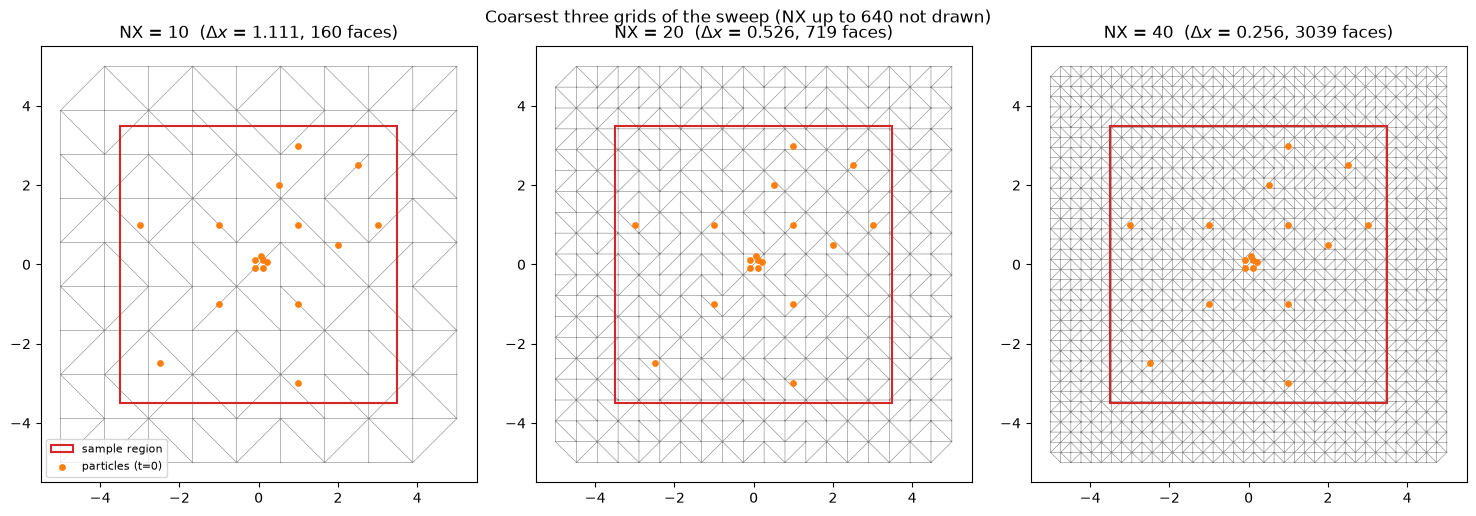

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, nx in zip(axes, [10, 20, 40]):
    g = GRIDS[nx]
    tri = mtri.Triangulation(g.node_lon.values, g.node_lat.values, triangles=g.face_node_connectivity.values)
    ax.triplot(tri, "k-", lw=0.4, alpha=0.5)
    ax.add_patch(plt.Rectangle((-SAMPLE_HALF, -SAMPLE_HALF), 2 * SAMPLE_HALF, 2 * SAMPLE_HALF,
                               fill=False, ec="C3", lw=1.5, label="sample region"))
    ax.scatter(p_lon0, p_lat0, c="C1", s=15, zorder=5, label="particles (t=0)")
    ax.set_title(f"NX = {nx}  ($\\Delta x$ = {DX[nx]:.3f}, {g.n_face} faces)")
    ax.set_aspect("equal")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Coarsest three grids of the sweep (NX up to 640 not drawn)")
plt.tight_layout()
plt.show()

## 2b. Stream functions: sign convention and overlay

Oceanographic convention, as in the paper: $u = -\partial\psi/\partial y,\ v = \partial\psi/\partial x$.

| flow | velocity | stream function |
|---|---|---|
| Part A, pure strain | $u=\varepsilon x,\ v=-\varepsilon y$ | $\psi=-\varepsilon\,x\,y$ |
| Part B, cellular | $u=U_0\sin kx\cos ky,\ v=-U_0\cos kx\sin ky$ | $\psi=-\dfrac{U_0}{k}\sin kx\,\sin ky$ |

(v1 used $\psi=+(U_0/k)\sin kx\sin ky$ with $u=\partial_y\psi,\ v=-\partial_x\psi$; the velocity field is the same.)
The cell below checks numerically, with fourth-order central differences ($h=10^{-3}$, truncation and round-off both
$<10^{-12}$ relative), that both stream functions reproduce `strain_uv` and `cellular_uv` with this convention.

In [6]:
def psi_strain(x, y):
    return -EPSILON * x * y


def psi_cellular(x, y):
    return -(U0 / K_WAVE) * np.sin(K_WAVE * x) * np.sin(K_WAVE * y)


PSI = {"A": psi_strain, "B": psi_cellular}
PSI_SCALE_B = U0 / K_WAVE


def uv_from_psi(psi_f, x, y, h=1e-3):
    # u = -dpsi/dy, v = dpsi/dx with 4th-order central differences
    d_dy = (-psi_f(x, y + 2 * h) + 8 * psi_f(x, y + h) - 8 * psi_f(x, y - h) + psi_f(x, y - 2 * h)) / (12 * h)
    d_dx = (-psi_f(x + 2 * h, y) + 8 * psi_f(x + h, y) - 8 * psi_f(x - h, y) + psi_f(x - 2 * h, y)) / (12 * h)
    return -d_dy, d_dx


XC, YC = np.meshgrid(np.linspace(-4.9, 4.9, 201), np.linspace(-4.9, 4.9, 201))
PSI_CHECK = {}
for flow, name in [("A", "psi = -eps x y      vs strain_uv  "), ("B", "psi = -(U0/k) sin sin vs cellular_uv")]:
    u_fd, v_fd = uv_from_psi(PSI[flow], XC, YC)
    u_ex, v_ex = FLOWS[flow](XC, YC)
    rel = np.max(np.hypot(u_fd - u_ex, v_fd - v_ex)) / np.max(np.hypot(u_ex, v_ex))
    PSI_CHECK[flow] = rel
    print(f"{name}: max relative difference {rel:.1e}")
    assert rel < 1e-10, f"stream function of flow {flow} does not match the velocity with u = -dpsi/dy, v = dpsi/dx"
print("Both stream functions satisfy u = -dpsi/dy, v = dpsi/dx to < 1e-10 relative.")

psi = -eps x y      vs strain_uv  : max relative difference 9.9e-13
psi = -(U0/k) sin sin vs cellular_uv: max relative difference 6.7e-13
Both stream functions satisfy u = -dpsi/dy, v = dpsi/dx to < 1e-10 relative.


**What to look for (mesh + stream function overlay).** The hyperbolas $\psi=-\varepsilon xy=$ const are the exact
trajectories of Part A; the thick lines $\psi=0$ (the $x$ and $y$ axes) are the separatrices through the stagnation
point at the origin (black star): particles approach along $y$ and leave along $x$. The near-origin particles (red)
start within one cell of the stagnation point on the coarse grids, where a piecewise-constant face value can have the
wrong sign; the far particles (blue) sit where the hyperbolas are almost straight. Shaded red triangles in the corners
are the parts of $[-5,5]^2$ not covered by the triangulation (Section 2 table): no particle path or sample point goes there.

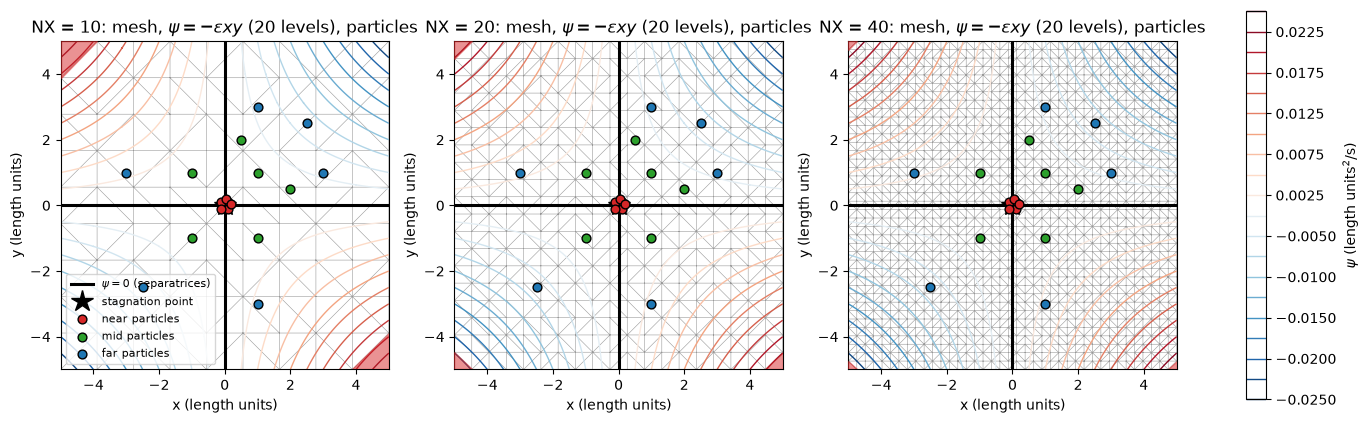

In [7]:
GROUPS = {"near": (slice(0, 6), "C3"), "mid": (slice(6, 12), "C2"), "far": (slice(12, 18), "C0")}
XO, YO = np.meshgrid(np.linspace(LON_MIN, LON_MAX, 401), np.linspace(LAT_MIN, LAT_MAX, 401))
psi_max = EPSILON * HALF * HALF
PSI_LEVELS_A = np.concatenate([-np.linspace(psi_max, 0, 11)[:-1], np.linspace(0, psi_max, 11)[1:]])  # 20, symmetric, no 0

fig, axes = plt.subplots(1, 3, figsize=(18, 6.3))
for ax, nx in zip(axes, [10, 20, 40]):
    g = GRIDS[nx]
    ax.triplot(mtri.Triangulation(g.node_lon.values, g.node_lat.values, triangles=g.face_node_connectivity.values),
               color="0.6", lw=0.4, zorder=1)
    cs = ax.contour(XO, YO, psi_strain(XO, YO), levels=PSI_LEVELS_A, cmap="RdBu_r", linewidths=1.0, zorder=2)
    ax.axhline(0, color="k", lw=2.2, zorder=3); ax.axvline(0, color="k", lw=2.2, zorder=3, label=r"$\psi = 0$ (separatrices)")
    for p in MISSING[nx]:
        ax.add_patch(plt.Polygon(p, closed=True, fc="C3", ec="C3", alpha=0.5, zorder=4))
    ax.plot(0, 0, "k*", ms=16, zorder=6, label="stagnation point")
    for gname, (sl, col) in GROUPS.items():
        ax.scatter(p_lon0[sl], p_lat0[sl], c=col, s=40, edgecolor="k", zorder=7, label=f"{gname} particles")
    ax.set_xlim(LON_MIN, LON_MAX); ax.set_ylim(LAT_MIN, LAT_MAX); ax.set_aspect("equal")
    ax.set_xlabel("x (length units)"); ax.set_ylabel("y (length units)")
    ax.set_title(f"NX = {nx}: mesh, $\\psi = -\\varepsilon xy$ (20 levels), particles")
fig.colorbar(cs, ax=axes, shrink=0.8, label=r"$\psi$ (length units$^2$/s)")
axes[0].legend(fontsize=8, loc="lower left")
plt.show()

## 3. Interpolators

`LinearFaceRecon` is copied verbatim from T1-4b (least-squares planar gradient fit over the face neighbours,
evaluated in float64 at the particle position).

**Note (v2).** `interp` calls `np.asarray(field.data.values)` on every call, i.e. it materialises the whole field
(all time steps, levels and faces) each time it is evaluated, four times per RK4 step per component. On this small,
in-memory dataset that is cheap, but it will not scale to FESOM-size (lazily loaded, multi-GB) data. Section 6g proposes
caching the array at construction and shows that this is bit-identical; the runs here keep the verbatim class.
`DEG2M` is only used when `spherical=True`; with `mesh="flat"` no unit conversion is applied anywhere.

In [8]:
DEG2M = 1852.0 * 60.0  # metres per degree (matches the Ux_Velocity unit conversion)


class LinearFaceRecon(ScalarInterpolator):
    """Linear least-squares reconstruction of face-registered data, constant in the vertical (zc)."""

    def __init__(self, uxgrid, spherical=False):
        self.spherical = spherical
        nbr = np.asarray(uxgrid.face_face_connectivity.values)          # (n_face, K)
        self.face_x = np.asarray(uxgrid.face_lon.values, dtype=np.float64)
        self.face_y = np.asarray(uxgrid.face_lat.values, dtype=np.float64)

        valid = nbr != INT_FILL_VALUE
        nbr_safe = np.where(valid, nbr, 0)
        dx, dy = self._offsets(self.face_x[:, None], self.face_y[:, None],
                               self.face_x[nbr_safe], self.face_y[nbr_safe])
        dx = np.where(valid, dx, 0.0)  # absent neighbour -> no contribution
        dy = np.where(valid, dy, 0.0)

        X2 = np.sum(dx * dx, axis=1)
        Y2 = np.sum(dy * dy, axis=1)
        XY = np.sum(dx * dy, axis=1)
        det = X2 * Y2 - XY * XY

        # < 2 independent neighbours -> singular system -> zero-gradient (piecewise-constant) fallback
        ok = det > 1e-12 * np.maximum(X2 * Y2, np.finfo(float).tiny)
        inv_det = np.where(ok, 1.0 / np.where(ok, det, 1.0), 0.0)

        self.gx = np.where(valid, (dx * Y2[:, None] - dy * XY[:, None]) * inv_det[:, None], 0.0)
        self.gy = np.where(valid, (dy * X2[:, None] - dx * XY[:, None]) * inv_det[:, None], 0.0)
        self.neighbors = nbr_safe
        self.mask = valid.astype(np.float64)
        self.n_fallback = int(np.sum(~ok))

    def _offsets(self, x_c, y_c, x, y):
        """Local planar offset of (x, y) from (x_c, y_c): metres on a sphere, grid units on a flat mesh."""
        if self.spherical:
            dlon = ((np.asarray(x) - x_c + 180.0) % 360.0) - 180.0
            return dlon * np.cos(np.deg2rad(y_c)) * DEG2M, (np.asarray(y) - y_c) * DEG2M
        return np.asarray(x) - x_c, np.asarray(y) - y_c

    def interp(self, particle_positions, grid_positions, field):
        ti, zi, fi = np.broadcast_arrays(
            grid_positions["T"]["index"], grid_positions["Z"]["index"], grid_positions["FACE"]["index"]
        )
        data = np.asarray(field.data.values)                            # (time, zc, n_face)

        u_c = data[ti, zi, fi]                                          # (M,)
        u_k = data[ti[:, None], zi[:, None], self.neighbors[fi]]        # (M, K)
        du = (u_k - u_c[:, None]) * self.mask[fi]
        a_x = np.sum(self.gx[fi] * du, axis=1)
        a_y = np.sum(self.gy[fi] * du, axis=1)

        dx, dy = self._offsets(self.face_x[fi], self.face_y[fi],
                               particle_positions["x"], particle_positions["y"])
        return u_c + a_x * dx + a_y * dy

In [9]:
SCHEMES = ["barycentric (node)", "constant (face)", "least-squares (face)"]
SCHEME_COLORS = {"barycentric (node)": "C0", "constant (face)": "C1", "least-squares (face)": "C2"}
MARKERS = {"barycentric (node)": "o", "constant (face)": "s", "least-squares (face)": "^"}


def make_fieldset(scheme, ds_node, ds_face):
    # Fresh FieldSet for one interpolation scheme.
    if scheme == "barycentric (node)":
        return parcels.FieldSet.from_ugrid_conventions(ds_node, mesh="flat")
    fieldset = parcels.FieldSet.from_ugrid_conventions(ds_face, mesh="flat")
    if scheme == "least-squares (face)":
        recon = LinearFaceRecon(fieldset.fields["U"].grid.uxgrid, spherical=False)
        fieldset.fields["U"].interp_method = recon
        fieldset.fields["V"].interp_method = recon
    return fieldset


def direct_error(fieldset, uv_func):
    # Velocity-vector error at the random sample points; relative errors are normalised by max |u_exact|.
    # Guard: Field.eval silently returns 0 for points the grid search does not find.
    fi = fieldset.fields["U"].grid.search(zs, ys, xs)["FACE"]["index"]
    assert np.all(fi >= 0), f"{np.sum(fi < 0)} sample points not found by the grid search"
    u = fieldset.fields["U"].eval(0.0, zs, ys, xs)
    v = fieldset.fields["V"].eval(0.0, zs, ys, xs)
    ue, ve = uv_func(xs, ys)
    err = np.hypot(u - ue, v - ve)
    uref = np.max(np.hypot(ue, ve))
    return {"max_abs": err.max(), "rms_abs": np.sqrt(np.mean(err**2)),
            "max_rel": err.max() / uref, "rms_rel": np.sqrt(np.mean(err**2)) / uref}

## 3b. Run infrastructure (v2)

Every trajectory in this notebook is one ordinary `pset.execute([Recorder, AdvectionRK4], ...)` call. `Recorder` is a
one-line kernel that stores the particle positions at the start of every step (the final position is added after
`execute`); this gives the full path without splitting `execute` into chunks. After every run the worker records

* the count of particles in each `StatusCode` (and any exception raised by `execute`),
* every recorded position checked against $[-5,5]^2$ and against the triangulation (`grid.search`, `FACE index >= 0`),
* the particle-based CFL number $|\mathbf{u}(\mathbf{x}_p)|\,\Delta t/\Delta x_\text{cell}(\mathbf{x}_p)$ at every step
  ($|\mathbf u|$ analytical, $\Delta x_\text{cell}$ = shortest edge of the containing triangle),
* the faces visited, the number of cell crossings per particle, and the $\psi$ drift per particle.

Independent runs are executed concurrently in forked worker processes (`run_batch`, plain `multiprocessing`; worker $w$ takes every $n$-th task, longest first); each run is still single-process
Parcels, so results do not depend on the number of workers. Wall times measured this way include contention between
processes: they are **implementation-dependent, not a cost comparison of the methods**.

In [10]:
_REC = []


def Recorder(particles, fieldset):
    _REC.append((np.array(particles.x), np.array(particles.y)))


def task_key(t):
    return (t["flow"], t["nx"], t["scheme"], float(t["dt"]), float(t["T"]), t["pset"])


def run_task(task):
    flow, nx, scheme, dt, T = task["flow"], task["nx"], task["scheme"], float(task["dt"]), float(task["T"])
    uv_func = FLOWS[flow]
    ds = make_dataset(GRIDS[nx], uv_func, "node" if scheme == "barycentric (node)" else "face")
    fs = make_fieldset(scheme, ds, ds)
    x0, y0 = PSETS[task["pset"]]
    _REC.clear()
    pset = parcels.ParticleSet(fs, pclass=Particle64, x=x0.copy(), y=y0.copy())
    err, t0 = None, time.time()
    try:
        pset.execute([Recorder, parcels.kernels.AdvectionRK4], runtime=T, dt=dt, verbose_progress=False)
    except Exception as e:                       # recorded and reported in Section 6e
        err = f"{type(e).__name__}: {e}"[:300]
    wall = time.time() - t0
    codes, counts = np.unique(np.asarray(pset.state), return_counts=True)
    states = {STATUS_NAME.get(int(c), str(c)): int(n) for c, n in zip(codes, counts)}
    X = np.array([r[0] for r in _REC] + [np.array(pset.x)])
    Y = np.array([r[1] for r in _REC] + [np.array(pset.y)])
    _REC.clear()
    n_steps = X.shape[0] - 1
    fi = fs.U.grid.search(np.full(X.size, 0.5), Y.ravel(), X.ravel())["FACE"]["index"].reshape(X.shape)
    found = fi >= 0
    dxc = GEOM[nx]["dx_short"][np.where(found, fi, 0)]
    cfl_p = np.where(found, np.hypot(*uv_func(X, Y)) * dt / dxc, np.nan)
    p = PSI[flow](X, Y)
    drift = np.max(np.abs(p - p[0]), axis=0) / (PSI_SCALE_B if flow == "B" else 1.0)
    traj = None
    if task.get("keep_every"):
        rows = list(range(0, n_steps + 1, task["keep_every"]))
        rows += [] if rows[-1] == n_steps else [n_steps]
        traj = (X[rows, : task["keep_n"]], Y[rows, : task["keep_n"]])
    return {"key": task_key(task), "x": X[-1], "y": Y[-1], "states": states, "error": err, "wall": wall,
            "n_steps": n_steps, "n_particles": len(x0),
            "n_outside_box": int(np.sum((np.abs(X) > HALF) | (np.abs(Y) > HALF))), "n_not_found": int(np.sum(~found)),
            "cfl_p_max": float(np.nanmax(cfl_p)) if np.any(found) else np.nan,
            "crossings": (fi[1:] != fi[:-1]).sum(axis=0), "visited": np.unique(fi[found]),
            "psi_drift": drift, "traj": traj}


def _worker_init():
    # Forked workers must not write to the Jupyter output streams (their I/O threads do not exist in the child).
    import sys
    sys.stdout = sys.stderr = open(os.devnull, "w")
    warnings.simplefilter("ignore")


RESULTS, PURPOSE = {}, {}


def run_batch(tasks, label):
    # Run every task not yet in RESULTS, concurrently (fork); return the results in task order.
    for t in tasks:
        PURPOSE.setdefault(task_key(t), set()).add(t.get("purpose", label))
    todo, seen = [], set()
    for t in tasks:
        k = task_key(t)
        if k not in RESULTS and k not in seen:
            seen.add(k); todo.append(t)
    todo.sort(key=lambda t: -float(t["T"]) / float(t["dt"]) * (1.5 if t["scheme"] == "barycentric (node)" else 1.0))
    if todo:
        t0, nproc = time.time(), min(N_WORKERS, len(todo))
        tmp = tempfile.mkdtemp(prefix="t14c_")

        def child(w):
            _worker_init()
            out = [run_task(t) for t in todo[w::nproc]]
            with open(os.path.join(tmp, f"{w}.pkl"), "wb") as f:
                pickle.dump(out, f)
            os._exit(0)

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", DeprecationWarning)      # "fork() in a multi-threaded process"
            procs = [mp.get_context("fork").Process(target=child, args=(w,)) for w in range(nproc)]
            for pr in procs:
                pr.start()
            for pr in procs:
                pr.join()
        for w in range(nproc):
            with open(os.path.join(tmp, f"{w}.pkl"), "rb") as f:          # missing file = worker crashed -> error
                for r in pickle.load(f):
                    RESULTS[r["key"]] = r
        shutil.rmtree(tmp)
        print(f"[{label}] {len(todo)} Parcels runs, {time.time() - t0:.0f} s wall on {nproc} processes")
    out = [RESULTS[task_key(t)] for t in tasks]
    for r in out:
        if r["error"]:
            print("WARNING, run raised:", r["key"], r["error"])
    return out


def states_str(r):
    return ", ".join(f"{k}:{v}" for k, v in r["states"].items()) + (" +EXCEPTION" if r["error"] else "")

## 4. Time-step check for the trajectory runs

Least-squares + RK4 at $N_X=40$ (spatially exact for this field), $T=360$ s, all 18 particles. The error should fall
as $\Delta t^4$ and then flatten at float64 round-off; $\Delta t=0.5$ s must lie on that plateau.

In [11]:
def analytical_position(lon0, lat0, epsilon, t_seconds):
    # Exact pure-strain position after t_seconds.
    return lon0 * np.exp(epsilon * t_seconds), lat0 * np.exp(-epsilon * t_seconds)


X_EXACT, Y_EXACT = analytical_position(p_lon0, p_lat0, EPSILON, T_TOTAL_S)              # the 18 particles
XA_EX, YA_EX = analytical_position(*PSETS["A"], EPSILON, T_TOTAL_S)                    # all Part A particles


def err_A(r, idx=IDX_ORIG):
    # NaN for a run that execute() aborted (its positions are frozen at the failure time)
    e = np.hypot(r["x"][idx] - XA_EX[idx], r["y"][idx] - YA_EX[idx])
    return np.full_like(e, np.nan) if r["error"] else e


DT_CHECK = [6.0, 3.0, 2.0, 1.0, 0.5, 0.25]
res = run_batch([dict(flow="A", nx=40, scheme="least-squares (face)", dt=d, T=T_TOTAL_S, pset="A",
                      purpose="A: dt check (NX=40)") for d in DT_CHECK], "dt check")
dt_rows = []
for dt_s, r in zip(DT_CHECK, res):
    e = err_A(r)
    dt_rows.append({"dt [s]": dt_s, "steps": r["n_steps"], "mean error": e.mean(), "max error": e.max(),
                    "states": states_str(r), "wall [s] (impl.-dependent)": round(r["wall"], 1)})
df_dt = pd.DataFrame(dt_rows)
print("float64 spacing at |x| = 0.14 / 1.4 / 4.3:",
      ", ".join(f"{np.spacing(a):.1e}" for a in (0.14, 1.4, 4.3)))
df_dt

[dt check] 6 Parcels runs, 26 s wall on 6 processes
float64 spacing at |x| = 0.14 / 1.4 / 4.3: 2.8e-17, 2.2e-16, 8.9e-16


,dt [s],steps,mean error,max error,states,wall [s] (impl.-dependent)
0,6.00,60,7.254341e-12,1.685742e-11,EndofLoop:2018,1.2
1,3.00,120,4.535800e-13,1.053783e-12,EndofLoop:2018,2.1
2,2.00,180,8.969626e-14,2.061019e-13,EndofLoop:2018,3.2
3,1.00,360,5.872471e-15,1.454689e-14,EndofLoop:2018,6.0
4,0.50,720,1.443300e-15,3.109120e-15,EndofLoop:2018,11.8
5,0.25,1440,3.146264e-15,1.300052e-14,EndofLoop:2018,23.0


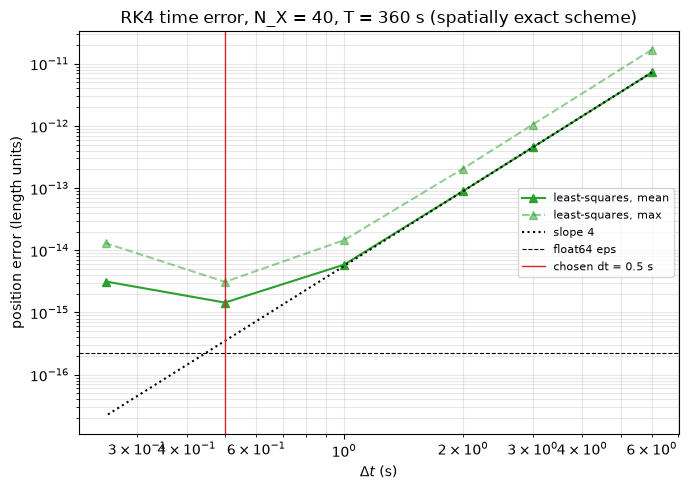

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(df_dt["dt [s]"], df_dt["mean error"], "^-", color="C2", label="least-squares, mean")
ax.loglog(df_dt["dt [s]"], df_dt["max error"], "^--", color="C2", alpha=0.5, label="least-squares, max")
d = df_dt["dt [s]"].values
ax.loglog(d, df_dt["mean error"].values[0] * (d / d[0]) ** 4, "k:", label="slope 4")
ax.axhline(EPS64, color="k", lw=0.8, ls="--", label="float64 eps")
ax.axvline(DT_S, color="C3", lw=1, label=f"chosen dt = {DT_S} s")
ax.set_xlabel(r"$\Delta t$ (s)"); ax.set_ylabel("position error (length units)")
ax.set_title("RK4 time error, N_X = 40, T = 360 s (spatially exact scheme)")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Part A — Pure strain: resolution sweep

For every $N_X$ and scheme: direct interpolation error at the 20 000 sample points, and the RK4 position error of the
18 particles after $T=360$ s with $\Delta t=0.5$ s (no particle file is written; only final positions are used).

v2: the same runs also carry the 2000 particles of the follow-up study (Section 6f); the tables below use the 18 particles unless stated otherwise. `states` = particle `StatusCode` counts after `execute`. `wall_s` is implementation-dependent (concurrent runs), not a cost comparison of the methods.

In [13]:
res_sweep = run_batch([dict(flow="A", nx=nx, scheme=s, dt=DT_S, T=T_TOTAL_S, pset="A", purpose="A: sweep")
                       for nx in NX_VALUES for s in SCHEMES], "Part A sweep")
SW = {(r["key"][1], r["key"][2]): r for r in res_sweep}
rows_A = []
for nx in NX_VALUES:
    ds_node = make_dataset(GRIDS[nx], strain_uv, "node")
    ds_face = make_dataset(GRIDS[nx], strain_uv, "face")
    for scheme in SCHEMES:
        d = direct_error(make_fieldset(scheme, ds_node, ds_face), strain_uv)
        r = SW[(nx, scheme)]
        e = err_A(r)
        rows_A.append({"NX": nx, "dx": DX[nx], "scheme": scheme,
                       "interp_max_abs": d["max_abs"], "interp_rms_abs": d["rms_abs"],
                       "interp_max_rel": d["max_rel"], "interp_rms_rel": d["rms_rel"],
                       "traj_mean": e.mean(), "traj_max": e.max(),
                       "traj_max_ulp": np.max(e / np.spacing(np.hypot(X_EXACT, Y_EXACT))),
                       "follow2000_mean": err_A(r, IDX_FOLLOW).mean(),
                       "states": states_str(r), "wall_s": r["wall"]})
        print(f"NX={nx:4d} {scheme:22s} | interp max rel {d['max_rel']:.2e} rms rel {d['rms_rel']:.2e} | "
              f"traj mean {e.mean():.2e} max {e.max():.2e} | {states_str(r)}", flush=True)
df_A = pd.DataFrame(rows_A)

[Part A sweep] 20 Parcels runs, 26 s wall on 20 processes
NX=  10 barycentric (node)     | interp max rel 6.35e-08 rms rel 1.72e-08 | traj mean 3.01e-10 max 7.32e-10 | EndofLoop:2018


NX=  10 constant (face)        | interp max rel 1.67e-01 rms rel 7.27e-02 | traj mean 6.39e-02 max 1.77e-01 | EndofLoop:2018


NX=  10 least-squares (face)   | interp max rel 1.81e-16 rms rel 4.93e-17 | traj mean 1.48e-15 max 3.11e-15 | EndofLoop:2018


NX=  20 barycentric (node)     | interp max rel 5.73e-08 rms rel 1.71e-08 | traj mean 3.04e-10 max 6.88e-10 | EndofLoop:2018


NX=  20 constant (face)        | interp max rel 7.91e-02 rms rel 3.60e-02 | traj mean 3.41e-02 max 7.49e-02 | EndofLoop:2018


...

NX= 320 constant (face)        | interp max rel 4.73e-03 rms rel 2.11e-03 | traj mean 4.18e-04 max 1.16e-03 | EndofLoop:2018


NX= 320 least-squares (face)   | interp max rel 1.76e-16 rms rel 4.53e-17 | traj mean 1.48e-15 max 3.11e-15 | EndofLoop:2018


NX= 640 barycentric (node)     | interp max rel 5.92e-08 rms rel 1.70e-08 | traj mean 3.44e-10 max 8.10e-10 | EndofLoop:2018


NX= 640 constant (face)        | interp max rel 2.36e-03 rms rel 1.06e-03 | traj mean 1.32e-04 max 8.51e-04 | EndofLoop:2018


NX= 640 least-squares (face)   | interp max rel 1.81e-16 rms rel 4.62e-17 | traj mean 1.53e-15 max 3.11e-15 | EndofLoop:2018


In [14]:
def fit_slope(dx, err):
    # Least-squares slope of log(err) vs log(dx), and prefactor C in err = C dx^p.
    p, logc = np.polyfit(np.log(dx), np.log(err), 1)
    return p, np.exp(logc)


ASYMPTOTIC_NX = 80   # fits for convergence orders use NX >= 80 (k*dx <= 0.16 in Part B)

print("wall_s: implementation-dependent wall time (concurrent runs), not a cost comparison of the methods")
pd.set_option("display.float_format", lambda v: f"{v:.3e}")
df_A.pivot(index="NX", columns="scheme",
           values=["interp_max_rel", "interp_rms_rel", "traj_mean", "traj_max", "states", "wall_s"])

wall_s: implementation-dependent wall time (concurrent runs), not a cost comparison of the methods


interp_max_rel                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              6.346e-08       1.668e-01            1.813e-16   
20              5.727e-08       7.912e-02            1.967e-16   
40              5.743e-08       3.827e-02            1.773e-16   
80              6.257e-08       1.907e-02            1.813e-16   
160             6.472e-08       9.486e-03            1.759e-16   
320             6.268e-08       4.728e-03            1.759e-16   
640             5.919e-08       2.359e-03            1.813e-16   

           interp_rms_rel                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              1.722e-08       7.268e-02            4.928e-17   
20              1.713e-08       3.604e-02            4.574e-17   
40              1.719e-08       1.744e-02            4.489e-17   
80              1.716e-08       8.606e-03            4.669e-17   
160             1.724e-08       4.291e-03            4.510e-17   
320             1.705e-08       2.112e-03            4.530e-17   
640             1.700e-08       1.058e-03            4.621e-17   

                traj_mean                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              3.014e-10       6.394e-02            1.483e-15   
20              3.042e-10       3.412e-02            1.463e-15   
40              3.016e-10       1.504e-02            1.443e-15   
80              2.976e-10       4.958e-03            1.482e-15   
160             3.027e-10       2.056e-03            1.482e-15   
320             2.953e-10       4.177e-04            1.482e-15   
640             3.443e-10       1.318e-04            1.531e-15   

                 traj_max                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              7.315e-10       1.769e-01            3.109e-15   
20              6.880e-10       7.492e-02            3.109e-15   
40              7.417e-10       6.057e-02            3.109e-15   
80              6.863e-10       1.453e-02            3.109e-15   
160             6.829e-10       5.988e-03            3.109e-15   
320             7.926e-10       1.156e-03            3.109e-15   
640             8.101e-10       8.513e-04            3.109e-15   

                   states                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10         EndofLoop:2018  EndofLoop:2018       EndofLoop:2018   
20         EndofLoop:2018  EndofLoop:2018       EndofLoop:2018   
40         EndofLoop:2018  EndofLoop:2018       EndofLoop:2018   
80         EndofLoop:2018  EndofLoop:2018       EndofLoop:2018   
160        EndofLoop:2018  EndofLoop:2018       EndofLoop:2018   
320        EndofLoop:2018  EndofLoop:2018       EndofLoop:2018   
640        EndofLoop:2018  EndofLoop:2018       EndofLoop:2018   

                   wall_s                                       
scheme barycentric (node) constant (face) least-squares (face)  
NX                                                              
10              2.079e+01       1.635e+01            1.130e+01  
20              2.031e+01       1.629e+01            1.183e+01  
40              2.041e+01       1.652e+01            1.178e+01  
80              2.064e+01       1.647e+01            1.157e+01  
160             2.066e+01       1.634e+01            1.197e+01  
320             2.133e+01       1.694e+01            1.225e+01  
640             2.231e+01       1.756e+01            1.325e+01

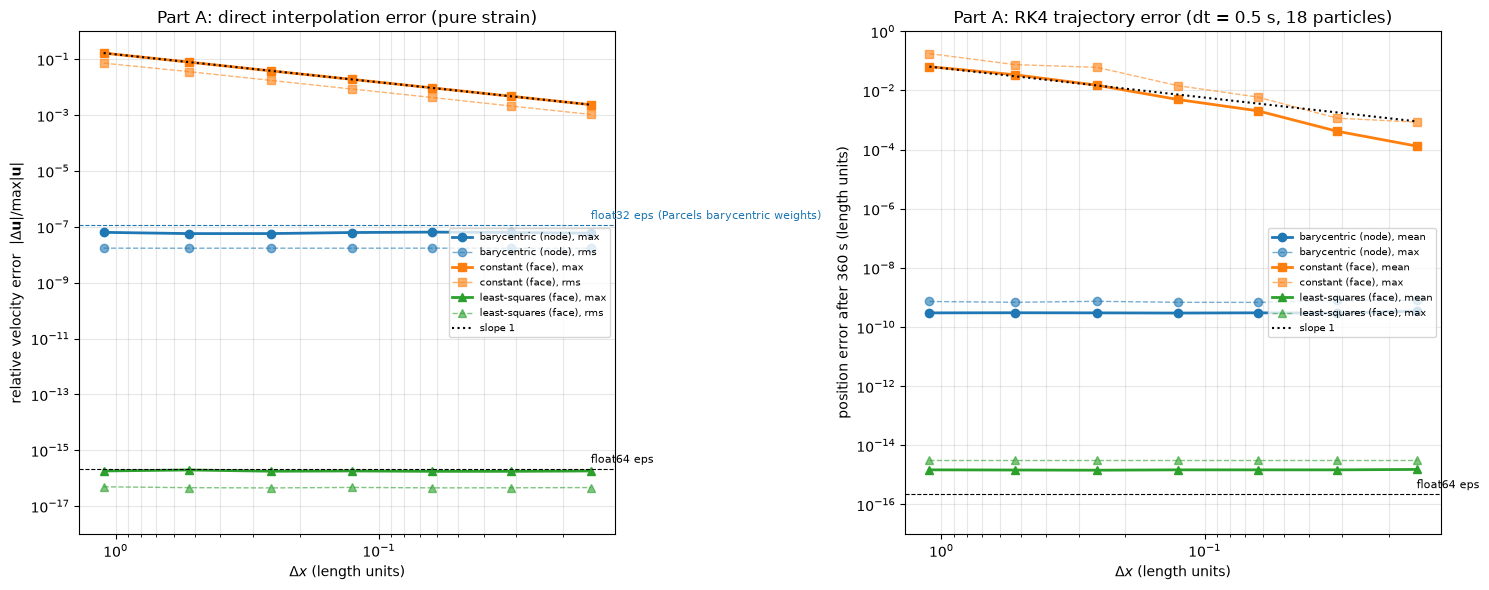

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
dxs = np.array([DX[nx] for nx in NX_VALUES])

ax = axes[0]
for scheme in SCHEMES:
    s = df_A[df_A["scheme"] == scheme]
    ax.loglog(s["dx"], s["interp_max_rel"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=2,
              label=f"{scheme}, max")
    ax.loglog(s["dx"], s["interp_rms_rel"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=1,
              ls="--", alpha=0.6, label=f"{scheme}, rms")
s = df_A[df_A["scheme"] == "constant (face)"]
ax.loglog(dxs, s["interp_max_rel"].values[0] * dxs / dxs[0], "k:", label="slope 1")
ax.axhline(EPS64, color="k", ls="--", lw=0.8)
ax.text(dxs[-1], EPS64 * 1.6, "float64 eps", fontsize=8)
ax.axhline(EPS32, color="C0", ls="--", lw=0.8)
ax.text(dxs[-1], EPS32 * 1.6, "float32 eps (Parcels barycentric weights)", fontsize=8, color="C0")
ax.set_xlabel(r"$\Delta x$ (length units)"); ax.set_ylabel(r"relative velocity error  $|\Delta\mathbf{u}|/\max|\mathbf{u}|$")
ax.set_title("Part A: direct interpolation error (pure strain)")
ax.set_ylim(1e-18, 1)
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)

ax = axes[1]
for scheme in SCHEMES:
    s = df_A[df_A["scheme"] == scheme]
    ax.loglog(s["dx"], s["traj_mean"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=2,
              label=f"{scheme}, mean")
    ax.loglog(s["dx"], s["traj_max"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=1, ls="--",
              alpha=0.6, label=f"{scheme}, max")
s = df_A[df_A["scheme"] == "constant (face)"]
ax.loglog(dxs, s["traj_mean"].values[0] * dxs / dxs[0], "k:", label="slope 1")
ax.axhline(EPS64, color="k", ls="--", lw=0.8)
ax.text(dxs[-1], EPS64 * 1.6, "float64 eps", fontsize=8)
ax.set_xlabel(r"$\Delta x$ (length units)"); ax.set_ylabel("position error after 360 s (length units)")
ax.set_title(f"Part A: RK4 trajectory error (dt = {DT_S} s, {N_PARTICLES} particles)")
ax.set_ylim(1e-17, 1)
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
for a in axes:
    a.invert_xaxis()
plt.tight_layout(); plt.show()

### Part A — Analytical vs interpolated: fields, transect and trajectories

What the three schemes actually return, compared with the analytical solution, on a refinement sequence $N_X = 10, 40, 160, 640$
($\Delta x = 1.1, 0.26, 0.063, 0.016$; $N_X=10$ is a deliberately crude grid; meshes finer than $N_X=40$ are
too dense to draw and are left out of the plots):

1. **Field maps** of $u$ (the $v$ component is the mirror image): analytical vs each interpolator, and the
   relative error $|u_\text{interp}-u_\text{exact}|/\max|u|$ on a log scale.
2. **Transect** of $u$ along the line $y = 0.37$ (chosen off the grid lines).
3. **Trajectories** of the six near-origin particles over $T = 2520$ s (as in the T1-4 convergence study,
   they stay inside the domain) against the analytical hyperbolas $x = x_0 e^{\varepsilon t}$, $y = y_0 e^{-\varepsilon t}$.

v2: the trajectory panels show the contours of $\psi=-\varepsilon xy$ underneath (thin grey: generic levels; thick: $\psi=0$, the axes).

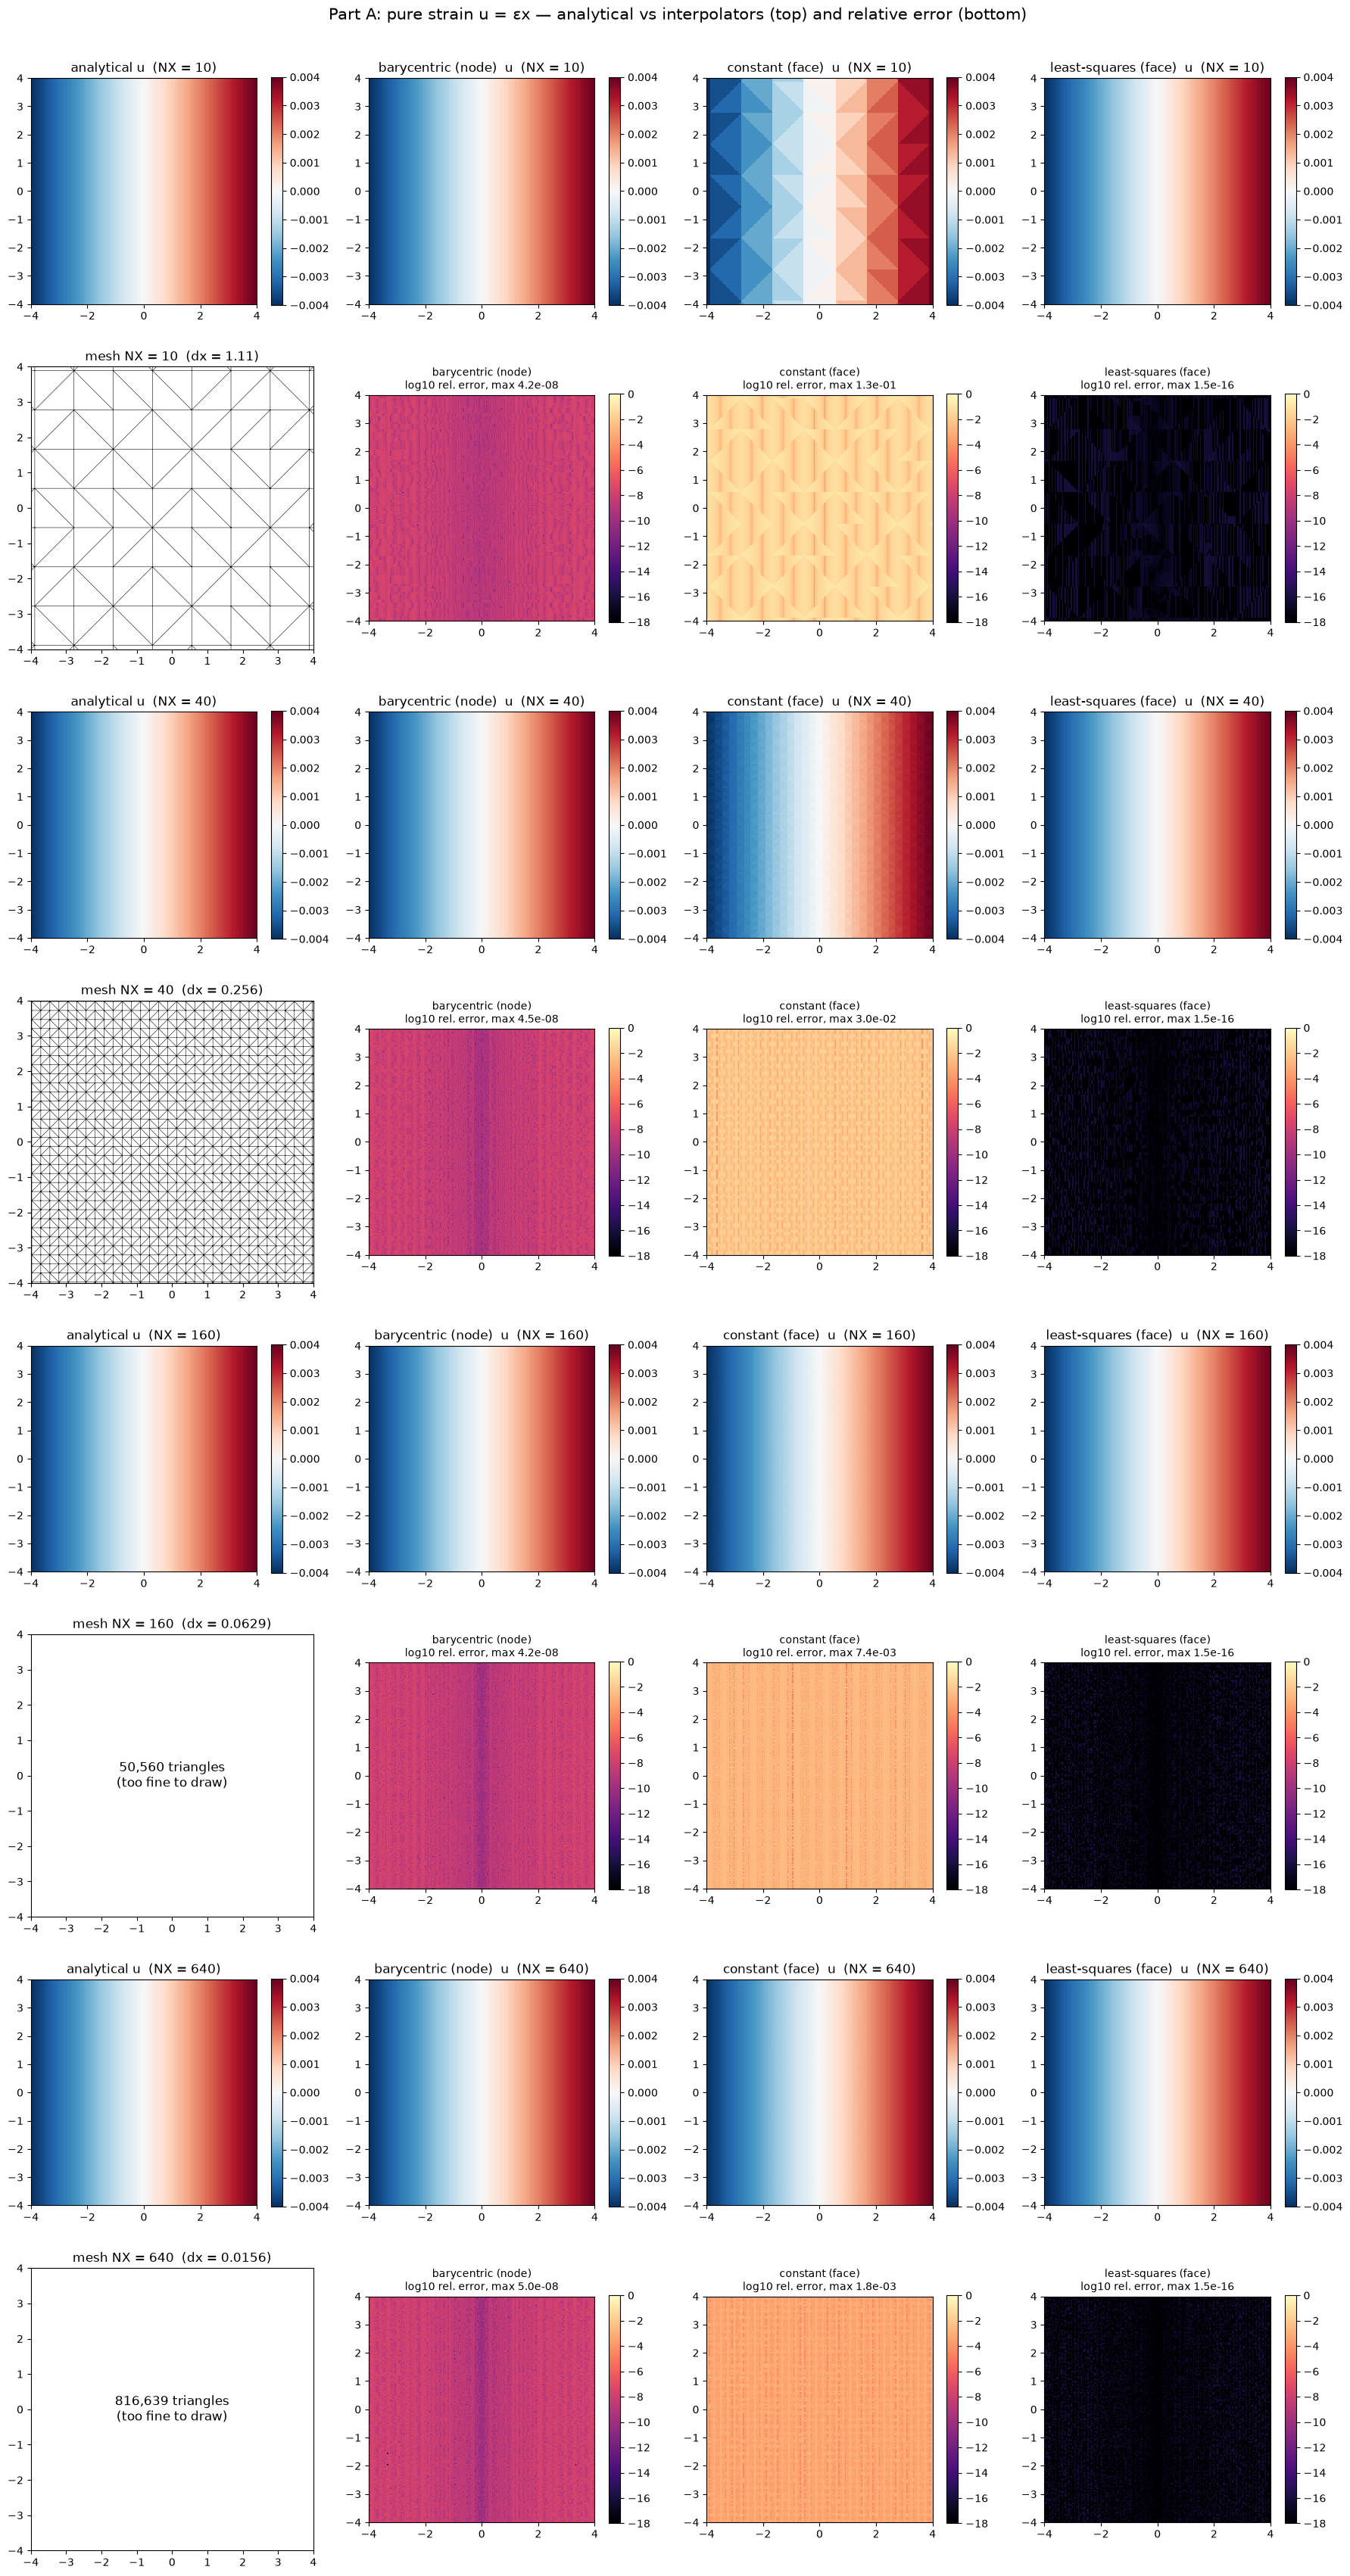

In [16]:
VIS_NX = [10, 40, 160, 640]
MAX_NX_DRAW_MESH = 40                            # finer meshes are not drawn (solid black, slow)
VIS_HALF = 4.0                                   # stay away from the dropped corner triangles
VIS_N = 240
XV, YV = np.meshgrid(np.linspace(-VIS_HALF, VIS_HALF, VIS_N), np.linspace(-VIS_HALF, VIS_HALF, VIS_N))
Y_LINE = 0.37
X_LINE = np.linspace(-VIS_HALF, VIS_HALF, 2001)


def eval_uv(fieldset, x, y):
    # Interpolated (u, v) at arbitrary points; NaN where the grid search finds no face.
    x, y = np.ravel(x), np.ravel(y)
    z = np.full_like(x, 0.5)
    fi = fieldset.fields["U"].grid.search(z, y, x)["FACE"]["index"]
    u = np.where(fi >= 0, fieldset.fields["U"].eval(0.0, z, y, x), np.nan)
    v = np.where(fi >= 0, fieldset.fields["V"].eval(0.0, z, y, x), np.nan)
    return u, v


def trajectories_chunked(fieldset, x0, y0, t_total_s, dt_s, chunk_s):  # v1 helper, kept for reference (unused)
    # RK4 positions every chunk_s seconds -> arrays (n_out, n_particles).
    pset = parcels.ParticleSet(fieldset, pclass=Particle64, x=x0.copy(), y=y0.copy())
    xs_t, ys_t = [x0.copy()], [y0.copy()]
    for _ in range(int(round(t_total_s / chunk_s))):
        pset.execute(parcels.kernels.AdvectionRK4, runtime=np.timedelta64(int(chunk_s * 1000), "ms"),
                     dt=np.timedelta64(int(dt_s * 1000), "ms"), verbose_progress=False)
        xs_t.append(np.array(pset.x)); ys_t.append(np.array(pset.y))
    return np.array(xs_t), np.array(ys_t)


def mesh_triangulation(nx):
    g = GRIDS[nx]
    return mtri.Triangulation(g.node_lon.values, g.node_lat.values, triangles=g.face_node_connectivity.values)


def field_maps(uv_func, title, cmap="RdBu_r"):
    # Rows: per VIS_NX -> [analytical u, 3 schemes u] and [mesh, 3 schemes log10 rel error].
    u_ex = uv_func(XV, YV)[0]
    u_ref = np.nanmax(np.hypot(*uv_func(XV, YV)))
    vmax = np.nanmax(np.abs(u_ex))
    fig, axes = plt.subplots(2 * len(VIS_NX), 4, figsize=(18, 8.5 * len(VIS_NX)))
    for r, nx in enumerate(VIS_NX):
        ds_node, ds_face = make_dataset(GRIDS[nx], uv_func, "node"), make_dataset(GRIDS[nx], uv_func, "face")
        tri = mesh_triangulation(nx)
        ax = axes[2 * r, 0]
        im = ax.pcolormesh(XV, YV, u_ex, cmap=cmap, vmin=-vmax, vmax=vmax, shading="auto")
        ax.set_title(f"analytical u  (NX = {nx})")
        fig.colorbar(im, ax=ax, shrink=0.8)
        if nx <= MAX_NX_DRAW_MESH:
            axes[2 * r + 1, 0].triplot(tri, "k-", lw=0.4)
        else:
            axes[2 * r + 1, 0].text(0, 0, f"{GRIDS[nx].n_face:,} triangles\n(too fine to draw)", ha="center",
                                    va="center", fontsize=12)
        axes[2 * r + 1, 0].set_title(f"mesh NX = {nx}  (dx = {DX[nx]:.3g})")
        for c, scheme in enumerate(SCHEMES, start=1):
            u, _ = eval_uv(make_fieldset(scheme, ds_node, ds_face), XV, YV)
            u = u.reshape(XV.shape)
            ax = axes[2 * r, c]
            im = ax.pcolormesh(XV, YV, u, cmap=cmap, vmin=-vmax, vmax=vmax, shading="auto")
            ax.set_title(f"{scheme}  u  (NX = {nx})")
            fig.colorbar(im, ax=ax, shrink=0.8)
            ax = axes[2 * r + 1, c]
            err = np.abs(u - u_ex) / u_ref
            im = ax.pcolormesh(XV, YV, np.log10(np.maximum(err, 1e-18)), cmap="magma", vmin=-18, vmax=0,
                               shading="auto")
            ax.set_title(f"{scheme}\nlog10 rel. error, max {np.nanmax(err):.1e}", fontsize=10)
            fig.colorbar(im, ax=ax, shrink=0.8)
    for ax in axes.ravel():
        ax.set_aspect("equal"); ax.set_xlim(-VIS_HALF, VIS_HALF); ax.set_ylim(-VIS_HALF, VIS_HALF)
    fig.suptitle(title, fontsize=15, y=1.0)
    plt.tight_layout(); plt.show()


def transect(uv_func, title):
    u_ex = uv_func(X_LINE, np.full_like(X_LINE, Y_LINE))[0]
    u_ref = np.max(np.abs(u_ex))
    fig, axes = plt.subplots(2, len(VIS_NX), figsize=(6 * len(VIS_NX), 9), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
    for c, nx in enumerate(VIS_NX):
        ds_node, ds_face = make_dataset(GRIDS[nx], uv_func, "node"), make_dataset(GRIDS[nx], uv_func, "face")
        axes[0, c].plot(X_LINE, u_ex, "k-", lw=3, alpha=0.35, label="analytical")
        for scheme in SCHEMES:
            u, _ = eval_uv(make_fieldset(scheme, ds_node, ds_face), X_LINE, np.full_like(X_LINE, Y_LINE))
            axes[0, c].plot(X_LINE, u, color=SCHEME_COLORS[scheme], lw=1.3,
                            ls="--" if scheme == "least-squares (face)" else "-", label=scheme)
            axes[1, c].semilogy(X_LINE, np.maximum(np.abs(u - u_ex) / u_ref, 1e-18), color=SCHEME_COLORS[scheme],
                                lw=1, label=scheme)
        if nx <= MAX_NX_DRAW_MESH:
            node_x = GRIDS[nx].node_lon.values
            for xn in np.unique(np.round(node_x[np.abs(node_x) <= VIS_HALF], 10)):
                axes[0, c].axvline(xn, color="0.85", lw=0.6, zorder=0)
        axes[0, c].set_title(f"u along y = {Y_LINE}, NX = {nx}" + ("\n(grey: grid columns)" if nx <= MAX_NX_DRAW_MESH else ""))
        axes[0, c].set_ylabel("u"); axes[0, c].legend(fontsize=8)
        axes[1, c].axhline(EPS64, color="k", ls="--", lw=0.8)
        axes[1, c].set_ylim(1e-18, 2); axes[1, c].set_xlabel("x"); axes[1, c].set_ylabel("|u - u_exact| / max|u|")
        axes[1, c].grid(True, which="both", alpha=0.3)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()


field_maps(strain_uv, "Part A: pure strain u = εx — analytical vs interpolators (top) and relative error (bottom)")

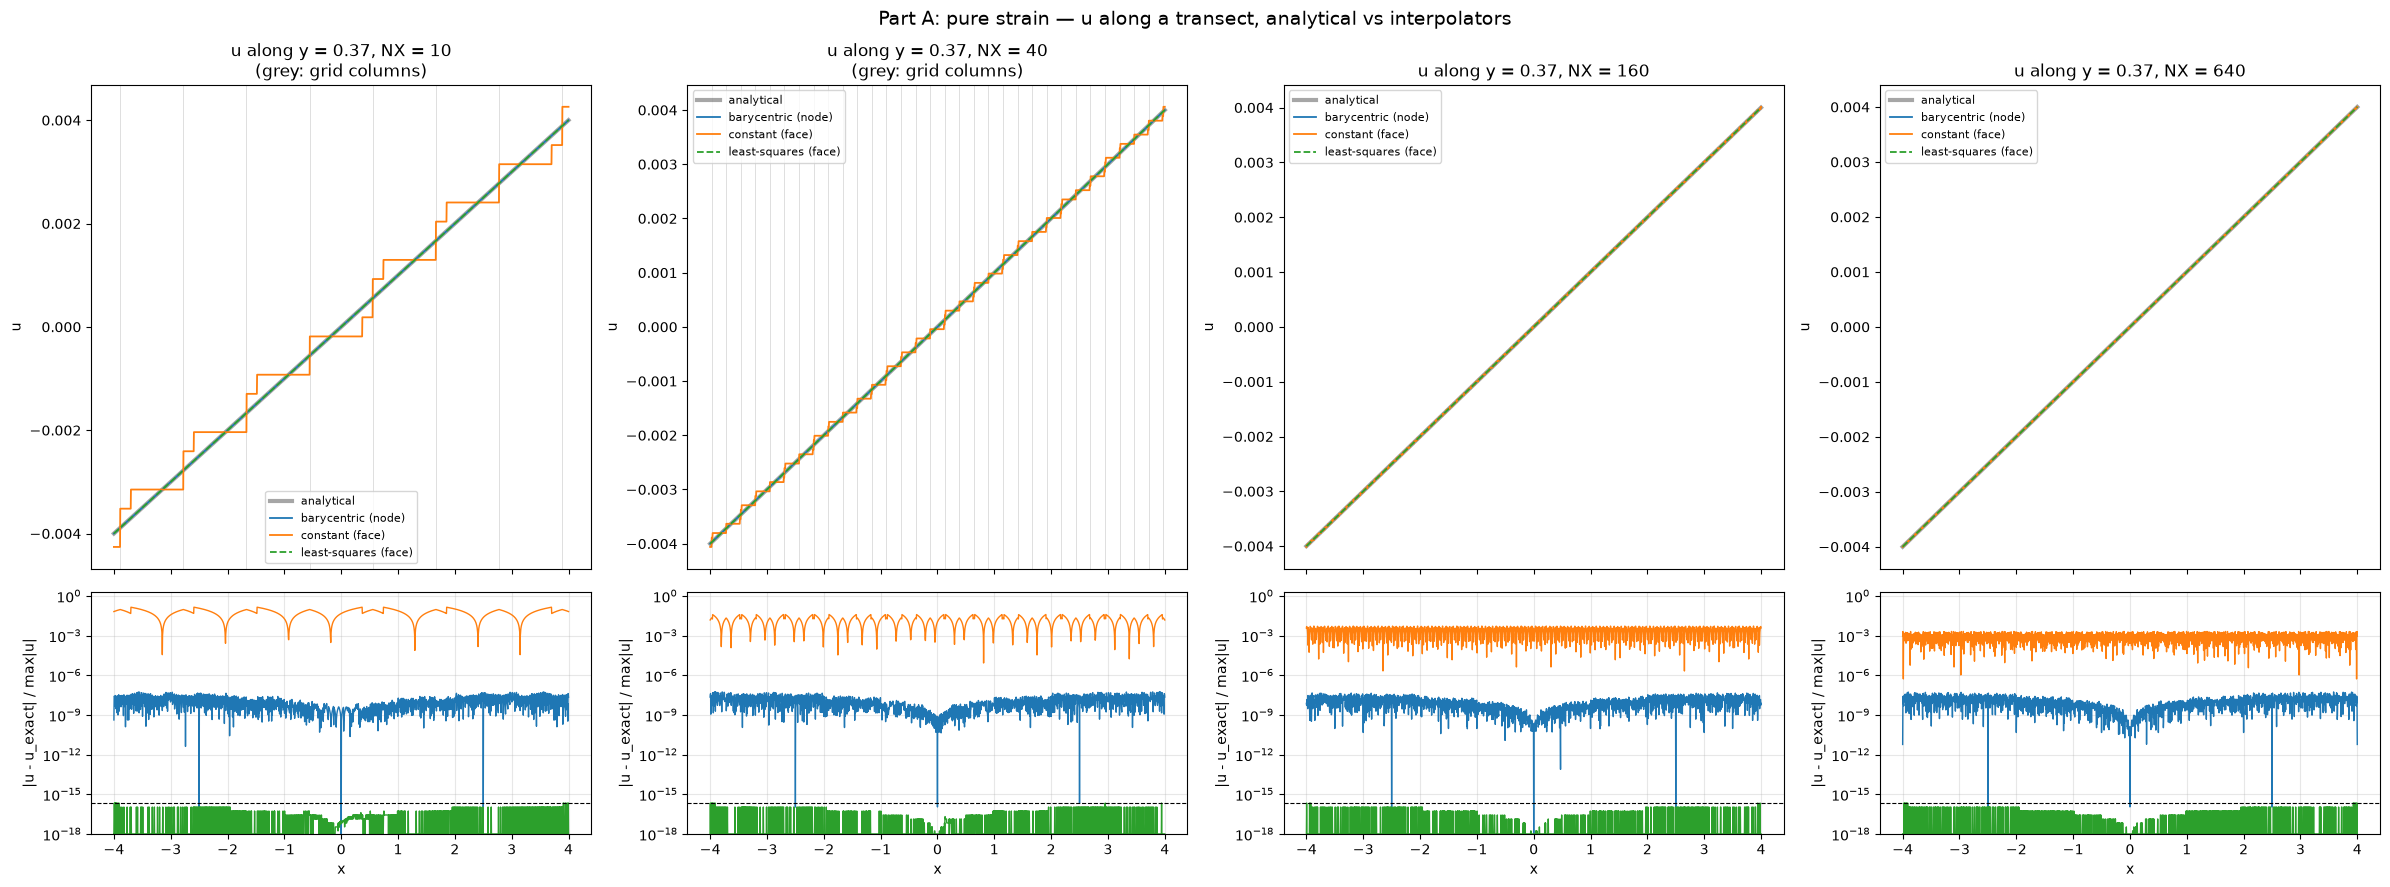

In [17]:
transect(strain_uv, "Part A: pure strain — u along a transect, analytical vs interpolators")

[Part A visualisation] 12 Parcels runs, 14 s wall on 12 processes


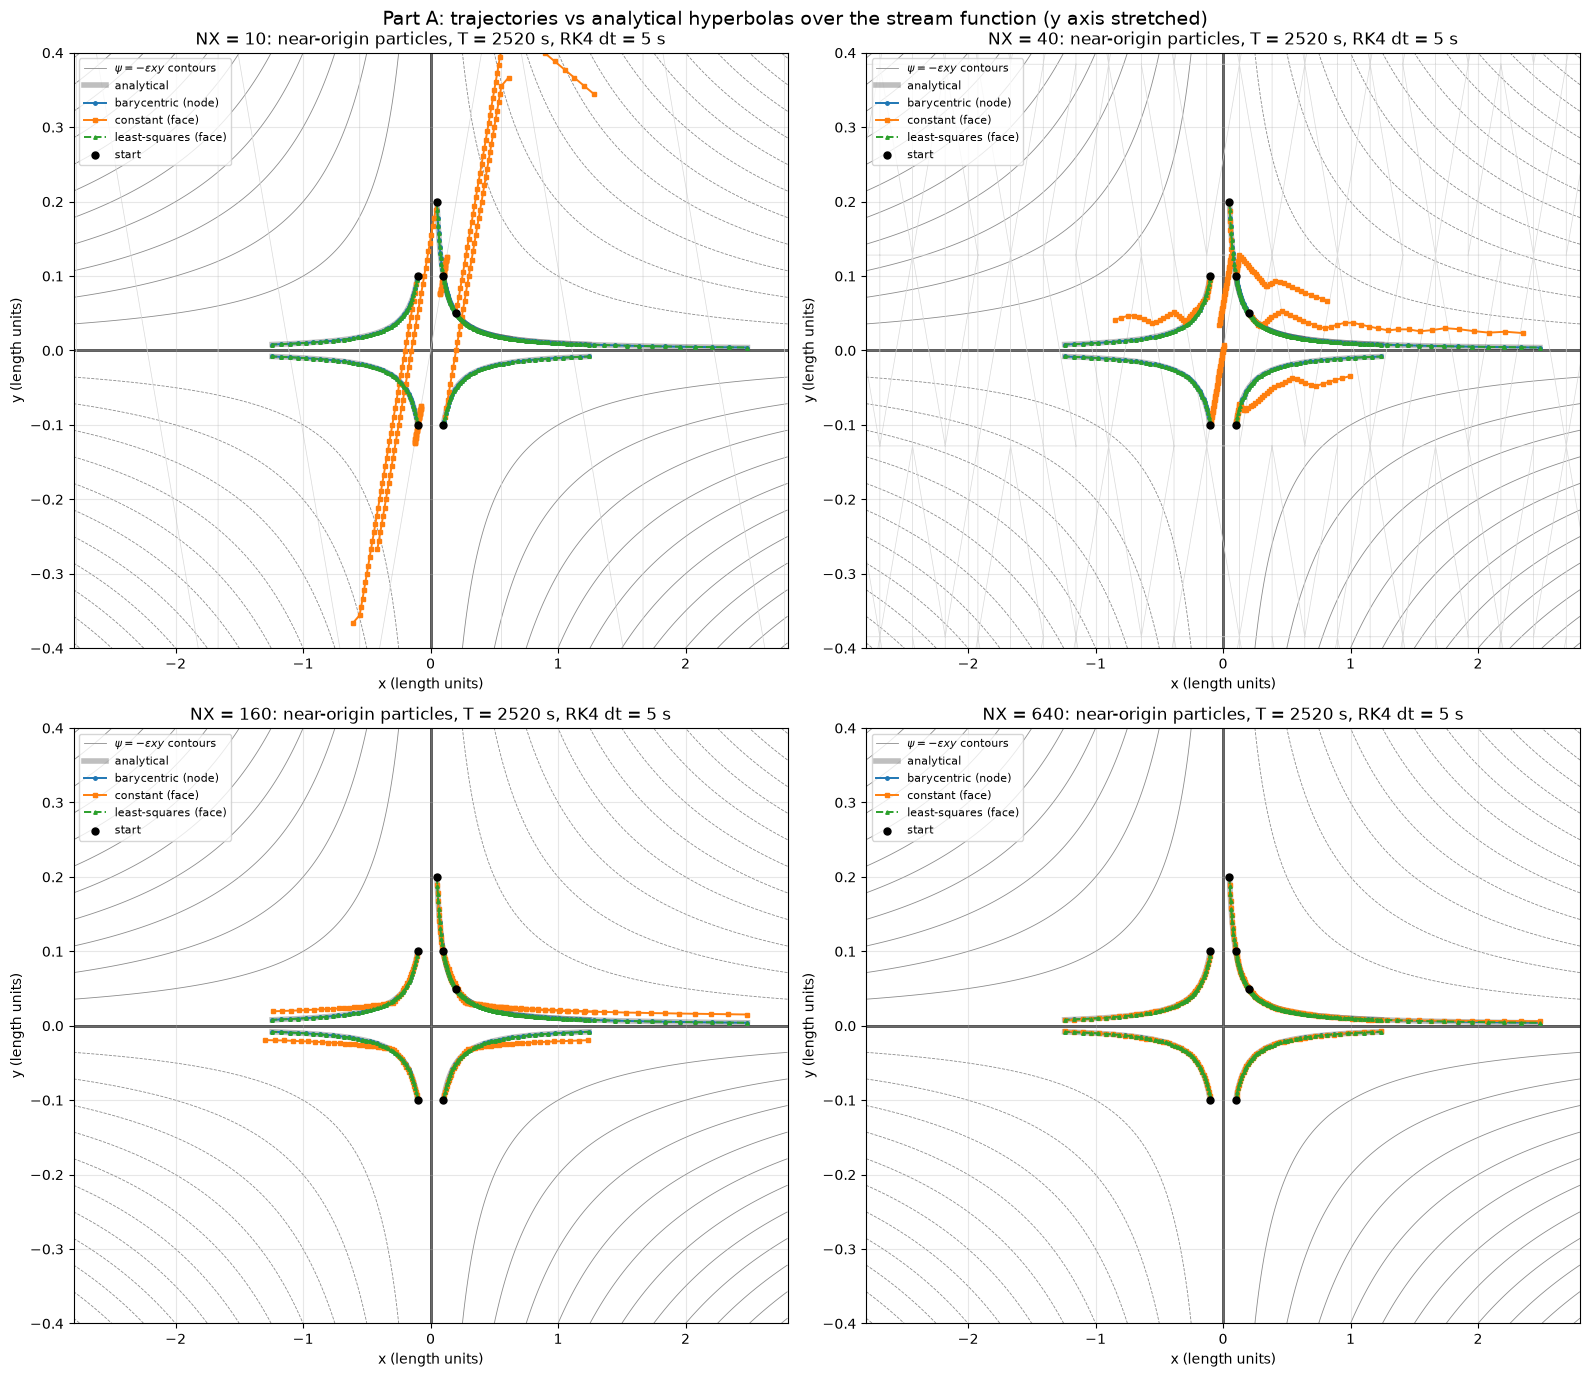

mean final error                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              2.791e-10       1.014e+00            1.760e-11   
40              1.824e-10       5.194e-01            1.760e-11   
160             1.385e-10       2.704e-02            1.760e-11   
640             1.894e-10       4.685e-03            1.760e-11   

          max final error                                       
scheme barycentric (node) constant (face) least-squares (face)  
NX                                                              
10              6.519e-10       1.249e+00            3.249e-11  
40              4.186e-10       1.251e+00            3.249e-11  
160             2.344e-10       5.396e-02            3.249e-11  
640             3.749e-10       1.104e-02            3.249e-11

In [18]:
T_VIS_A, DT_VIS_A, CHUNK_A = 2520.0, 5.0, 60.0
x0_near, y0_near = PSETS["A_near"]
t_vis = np.arange(0, T_VIS_A + CHUNK_A / 2, CHUNK_A)
x_ex = x0_near[None, :] * np.exp(EPSILON * t_vis[:, None])
y_ex = y0_near[None, :] * np.exp(-EPSILON * t_vis[:, None])
res_visA = run_batch([dict(flow="A", nx=nx, scheme=s, dt=DT_VIS_A, T=T_VIS_A, pset="A_near", keep_every=int(CHUNK_A / DT_VIS_A),
                           keep_n=6, purpose="A: visualisation") for nx in VIS_NX for s in SCHEMES], "Part A visualisation")
VA = {(r["key"][1], r["key"][2]): r for r in res_visA}

XP, YP = np.meshgrid(np.linspace(-2.8, 2.8, 400), np.linspace(-0.4, 0.4, 400))
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
traj_err_rows = []
for ax, nx in zip(axes.ravel(), VIS_NX):
    ax.contour(XP, YP, psi_strain(XP, YP), levels=np.linspace(-1.1e-3, 1.1e-3, 23), colors="0.55", linewidths=0.6, zorder=0)
    ax.axhline(0, color="0.3", lw=2, zorder=0); ax.axvline(0, color="0.3", lw=2, zorder=0)
    ax.plot([], [], color="0.55", lw=0.6, label=r"$\psi=-\varepsilon xy$ contours")
    if nx <= MAX_NX_DRAW_MESH:
        ax.triplot(mesh_triangulation(nx), color="0.85", lw=0.5, zorder=0)
    for i in range(len(x0_near)):
        ax.plot(x_ex[:, i], y_ex[:, i], "k-", lw=4, alpha=0.25, label="analytical" if i == 0 else None)
    for scheme in SCHEMES:
        xt, yt = VA[(nx, scheme)]["traj"]
        for i in range(len(x0_near)):
            ax.plot(xt[:, i], yt[:, i], color=SCHEME_COLORS[scheme], lw=1.4, marker=MARKERS[scheme], ms=2.5,
                    ls="--" if scheme == "least-squares (face)" else "-", label=scheme if i == 0 else None)
        err = np.hypot(xt[-1] - x_ex[-1], yt[-1] - y_ex[-1])
        traj_err_rows.append({"NX": nx, "scheme": scheme, "mean final error": err.mean(), "max final error": err.max(),
                              "states": states_str(VA[(nx, scheme)])})
    ax.scatter(x0_near, y0_near, c="k", s=25, zorder=5, label="start")
    ax.set_xlim(-2.8, 2.8); ax.set_ylim(-0.4, 0.4)
    ax.set_title(f"NX = {nx}: near-origin particles, T = {T_VIS_A:.0f} s, RK4 dt = {DT_VIS_A:g} s")
    ax.set_xlabel("x (length units)"); ax.set_ylabel("y (length units)"); ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3)
fig.suptitle("Part A: trajectories vs analytical hyperbolas over the stream function (y axis stretched)", fontsize=14)
plt.tight_layout(); plt.show()
pd.DataFrame(traj_err_rows).pivot(index="NX", columns="scheme", values=["mean final error", "max final error"])

**What to look for (Part A).** The least-squares and barycentric fields are indistinguishable from the analytical
field at both resolutions (errors at round-off / Parcels' float32 floor), and their trajectories sit on the
analytical hyperbolas. The constant-face field is a mosaic of triangles; near the stagnation point a face can carry
the wrong sign of $u$ for a particle inside it, so near-origin particles can be pushed the wrong way or trapped
on the line $x \approx 0$ — the error that the T1-4b convergence study showed as a flat 1.25. Refining the grid
reduces the constant-face field error (first order) — compare the trajectory errors in the table for
$N_X = 10 \to 640$.

The grey $\psi$ contours are the exact paths: a correct trajectory follows one contour; the constant-face paths that run along $x\approx0$ or jump between contours show where the mosaic field breaks the invariant.

### Part A slopes and extrapolation to $10^{-16}$

Only the constant-face scheme has a resolution-dependent error for a linear field. Fitting
$\mathrm{err}=C\,\Delta x^{p}$ over $N_X\ge 80$ and solving $C\,\Delta x_*^{p}=10^{-16}$ gives the spacing that would be
needed to reach machine precision, with $N_X^* = 10/\Delta x_* + 1$.

In [19]:
def extrapolate(dx, err, target=1e-16):
    p, c = fit_slope(dx, err)
    with np.errstate(over="ignore", divide="ignore"):   # meaningless for the flat (exact / floor) curves
        dx_star = (target / c) ** (1.0 / p)
        nx_star = (LON_MAX - LON_MIN) / dx_star + 1
    return p, dx_star, nx_star


fit_rows_A = []
for scheme in SCHEMES:
    s = df_A[df_A["scheme"] == scheme]
    a = s[s["NX"] >= ASYMPTOTIC_NX]
    for metric in ["interp_max_rel", "interp_rms_rel", "traj_mean", "traj_max"]:
        p_all, _ = fit_slope(s["dx"].values, s[metric].values)
        p, dx_star, nx_star = extrapolate(a["dx"].values, a[metric].values)
        fit_rows_A.append({"scheme": scheme, "metric": metric, "slope (all NX)": p_all,
                           f"slope (NX>={ASYMPTOTIC_NX})": p,
                           "dx* for 1e-16": dx_star if scheme == "constant (face)" else np.nan,
                           "NX* for 1e-16": nx_star if scheme == "constant (face)" else np.nan})
df_fit_A = pd.DataFrame(fit_rows_A)
df_fit_A

,scheme,metric,slope (all NX),slope (NX>=80),dx* for 1e-16,NX* for 1e-16
0,barycentric (node),interp_max_rel,-4.490e-03,2.844e-02,NaN,NaN
1,barycentric (node),interp_rms_rel,2.287e-03,5.724e-03,NaN,NaN
2,barycentric (node),traj_mean,-1.716e-02,-5.926e-02,NaN,NaN
3,barycentric (node),traj_max,-2.524e-02,-9.277e-02,NaN,NaN
4,constant (face),interp_max_rel,9.985e-01,9.997e-01,6.566e-16,1.523e+16
5,constant (face),interp_rms_rel,9.963e-01,1.004e+00,1.669e-15,5.990e+15
6,constant (face),traj_mean,1.477e+00,1.790e+00,2.643e-09,3.783e+09
7,constant (face),traj_max,1.343e+00,1.458e+00,2.510e-11,3.984e+11
8,least-squares (face),interp_max_rel,1.163e-02,2.961e-05,NaN,NaN
9,least-squares (face),interp_rms_rel,1.063e-02,3.787e-03,NaN,NaN


In [20]:
cf = df_fit_A[(df_fit_A["scheme"] == "constant (face)") & (df_fit_A["metric"] == "interp_max_rel")].iloc[0]
print(f"constant (face), direct max relative error: slope {cf[f'slope (NX>={ASYMPTOTIC_NX})']:.2f}")
print(f"  to reach 1e-16 it would need dx* = {cf['dx* for 1e-16']:.1e} length units, NX* = {cf['NX* for 1e-16']:.1e}, "
      f"i.e. ~{cf['NX* for 1e-16'] ** 2:.0e} nodes / ~{2 * cf['NX* for 1e-16'] ** 2:.0e} triangles.")
print(f"  For comparison, the float64 spacing of the coordinate x = 5 itself is {np.spacing(5.0):.1e}: "
      f"dx* is {'below' if cf['dx* for 1e-16'] < np.spacing(5.0) else 'above'} it, so such a grid cannot even be "
      f"represented in float64.")

constant (face), direct max relative error: slope 1.00
  to reach 1e-16 it would need dx* = 6.6e-16 length units, NX* = 1.5e+16, i.e. ~2e+32 nodes / ~5e+32 triangles.
  For comparison, the float64 spacing of the coordinate x = 5 itself is 8.9e-16: dx* is below it, so such a grid cannot even be represented in float64.


**Interpretation (Part A).**

* **least-squares (face)** reproduces the linear field to float64 round-off at *every* resolution: the relative velocity
  error is $O(10^{-16})$ and the trajectory error after 720 RK4 steps is a few $10^{-16}$–$10^{-15}$ length units, i.e. a few
  units in the last place (ulp) of the positions. There is nothing left to converge: this is machine precision.
* **barycentric (node)** is flat at a relative error of order the float32 epsilon. This is the Parcels float32
  barycentric-weight limitation described at the top (**Parcels float32 limitation**, not a property of linear
  interpolation): the trajectory error ($\sim10^{-10}$–$10^{-9}$ length units) does not improve with resolution either.
* **constant (face)** converges at first order. Reaching $10^{-16}$ by refinement alone would require a node spacing
  smaller than the float64 resolution of the coordinates themselves — i.e. it is unreachable; machine precision can only be
  obtained with a scheme that is exact for the field (least-squares here).

## 6. Part B — Smooth nonlinear field: true spatial convergence orders

$$u = U_0\sin kx\cos ky,\qquad v = -U_0\cos kx\sin ky,\qquad k = 2\pi/5$$

(divergence-free cellular flow, two wavelengths across the domain). No scheme is exact for it, so the direct
interpolation error now shows each scheme's genuine order: ~1 (constant face) and ~2 (barycentric node and least-squares,
both linear reconstructions). Errors are relative to $\max|\mathbf{u}| = U_0$ over the sample points.

In [21]:
rows_B = []
for nx in NX_VALUES:
    ds_node = make_dataset(GRIDS[nx], cellular_uv, "node")
    ds_face = make_dataset(GRIDS[nx], cellular_uv, "face")
    for scheme in SCHEMES:
        d = direct_error(make_fieldset(scheme, ds_node, ds_face), cellular_uv)
        rows_B.append({"NX": nx, "dx": DX[nx], "scheme": scheme, **{f"interp_{k}": v for k, v in d.items()}})
df_B = pd.DataFrame(rows_B)
df_B.pivot(index="NX", columns="scheme", values=["interp_max_rel", "interp_rms_rel"])

interp_max_rel                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              5.758e-01       9.572e-01            9.431e-01   
20              1.466e-01       4.682e-01            2.478e-01   
40              3.633e-02       2.290e-01            5.896e-02   
80              8.844e-03       1.142e-01            1.450e-02   
160             2.200e-03       5.692e-02            3.678e-03   
320             5.469e-04       2.742e-02            8.950e-04   
640             1.352e-04       1.446e-02            2.185e-04   

           interp_rms_rel                                       
scheme barycentric (node) constant (face) least-squares (face)  
NX                                                              
10              2.446e-01       3.133e-01            1.661e-01  
20              6.016e-02       1.573e-01            4.155e-02  
40              1.468e-02       7.664e-02            1.007e-02  
80              3.599e-03       3.792e-02            2.463e-03  
160             8.946e-04       1.893e-02            6.116e-04  
320             2.225e-04       9.276e-03            1.500e-04  
640             5.538e-05       4.644e-03            3.736e-05

In [22]:
fit_rows_B = []
for scheme in SCHEMES:
    s = df_B[df_B["scheme"] == scheme]
    a = s[s["NX"] >= ASYMPTOTIC_NX]
    for metric in ["interp_max_rel", "interp_rms_rel"]:
        p_all, _ = fit_slope(s["dx"].values, s[metric].values)
        p, dx_star, nx_star = extrapolate(a["dx"].values, a[metric].values)
        fit_rows_B.append({"scheme": scheme, "metric": metric, "slope (all NX)": p_all,
                           f"slope (NX>={ASYMPTOTIC_NX})": p, "dx* for 1e-16": dx_star, "NX* for 1e-16": nx_star})
df_fit_B = pd.DataFrame(fit_rows_B)
df_fit_B

,scheme,metric,slope (all NX),slope (NX>=80),dx* for 1e-16,NX* for 1e-16
0,barycentric (node),interp_max_rel,1.969e+00,2.000e+00,1.342e-08,7.454e+08
1,barycentric (node),interp_rms_rel,1.975e+00,1.997e+00,2.059e-08,4.857e+08
2,constant (face),interp_max_rel,9.904e-01,9.944e-01,9.179e-17,1.089e+17
3,constant (face),interp_rms_rel,9.928e-01,1.007e+00,4.145e-16,2.413e+16
4,least-squares (face),interp_max_rel,1.973e+00,2.009e+00,1.124e-08,8.893e+08
5,least-squares (face),interp_rms_rel,1.978e+00,2.005e+00,2.649e-08,3.774e+08


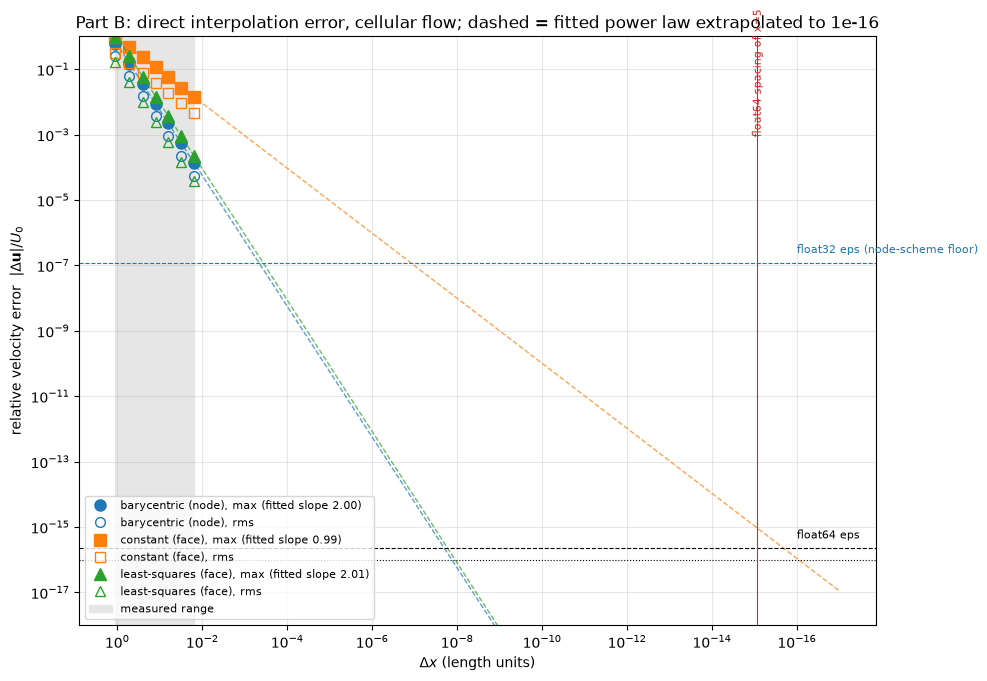

In [23]:
fig, ax = plt.subplots(figsize=(10, 7))
dx_ext = np.logspace(np.log10(dxs[0]), -17, 200)
for scheme in SCHEMES:
    s = df_B[df_B["scheme"] == scheme]
    a = s[s["NX"] >= ASYMPTOTIC_NX]
    p, c = fit_slope(a["dx"].values, a["interp_max_rel"].values)
    ax.loglog(s["dx"], s["interp_max_rel"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=2, ls="none",
              ms=8, label=f"{scheme}, max (fitted slope {p:.2f})")
    ax.loglog(s["dx"], s["interp_rms_rel"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], ls="none",
              mfc="none", ms=7, label=f"{scheme}, rms")
    ax.loglog(dx_ext, c * dx_ext ** p, color=SCHEME_COLORS[scheme], lw=1, ls="--", alpha=0.7)
ax.axhline(EPS64, color="k", ls="--", lw=0.8)
ax.text(1e-16, EPS64 * 2, "float64 eps", fontsize=8)
ax.axhline(1e-16, color="k", ls=":", lw=0.8)
ax.axhline(EPS32, color="C0", ls="--", lw=0.8)
ax.text(1e-16, EPS32 * 2, "float32 eps (node-scheme floor)", fontsize=8, color="C0")
ax.axvline(np.spacing(5.0), color="C3", lw=0.8)
ax.text(np.spacing(5.0) * 1.3, 1e-3, "float64 spacing of x=5", rotation=90, fontsize=8, color="C3")
ax.axvspan(dxs[-1], dxs[0], color="0.9", zorder=0, label="measured range")
ax.set_xlabel(r"$\Delta x$ (length units)")
ax.set_ylabel(r"relative velocity error  $|\Delta\mathbf{u}|/U_0$")
ax.set_title("Part B: direct interpolation error, cellular flow; dashed = fitted power law extrapolated to 1e-16")
ax.set_ylim(1e-18, 1)
ax.invert_xaxis()
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

### Part B — Analytical vs interpolated: fields, transect and trajectories

Same views for the cellular flow. There is no closed-form trajectory, but the flow has a stream function
$$\psi = -\frac{U_0}{k}\,\sin kx\,\sin ky,\qquad u = -\partial_y\psi,\; v = \partial_x\psi$$
(oceanographic convention, Section 2b),
so every exact trajectory follows a contour of $\psi$ (closed orbits inside each cell). The trajectory panel
overlays computed RK4 paths (T = 6000 s, about one revolution of the inner orbits) on the analytical streamlines and
reports the drift $\max_t |\psi(\mathbf{x}(t)) - \psi(\mathbf{x}_0)| / (U_0/k)$.

v2: the same runs carry the 500 particles of Section 6b; the drift below is evaluated at the v1 output times (every 100 s) and compared with the v1 table, and with the v1 sign of $\psi$ (bitwise).

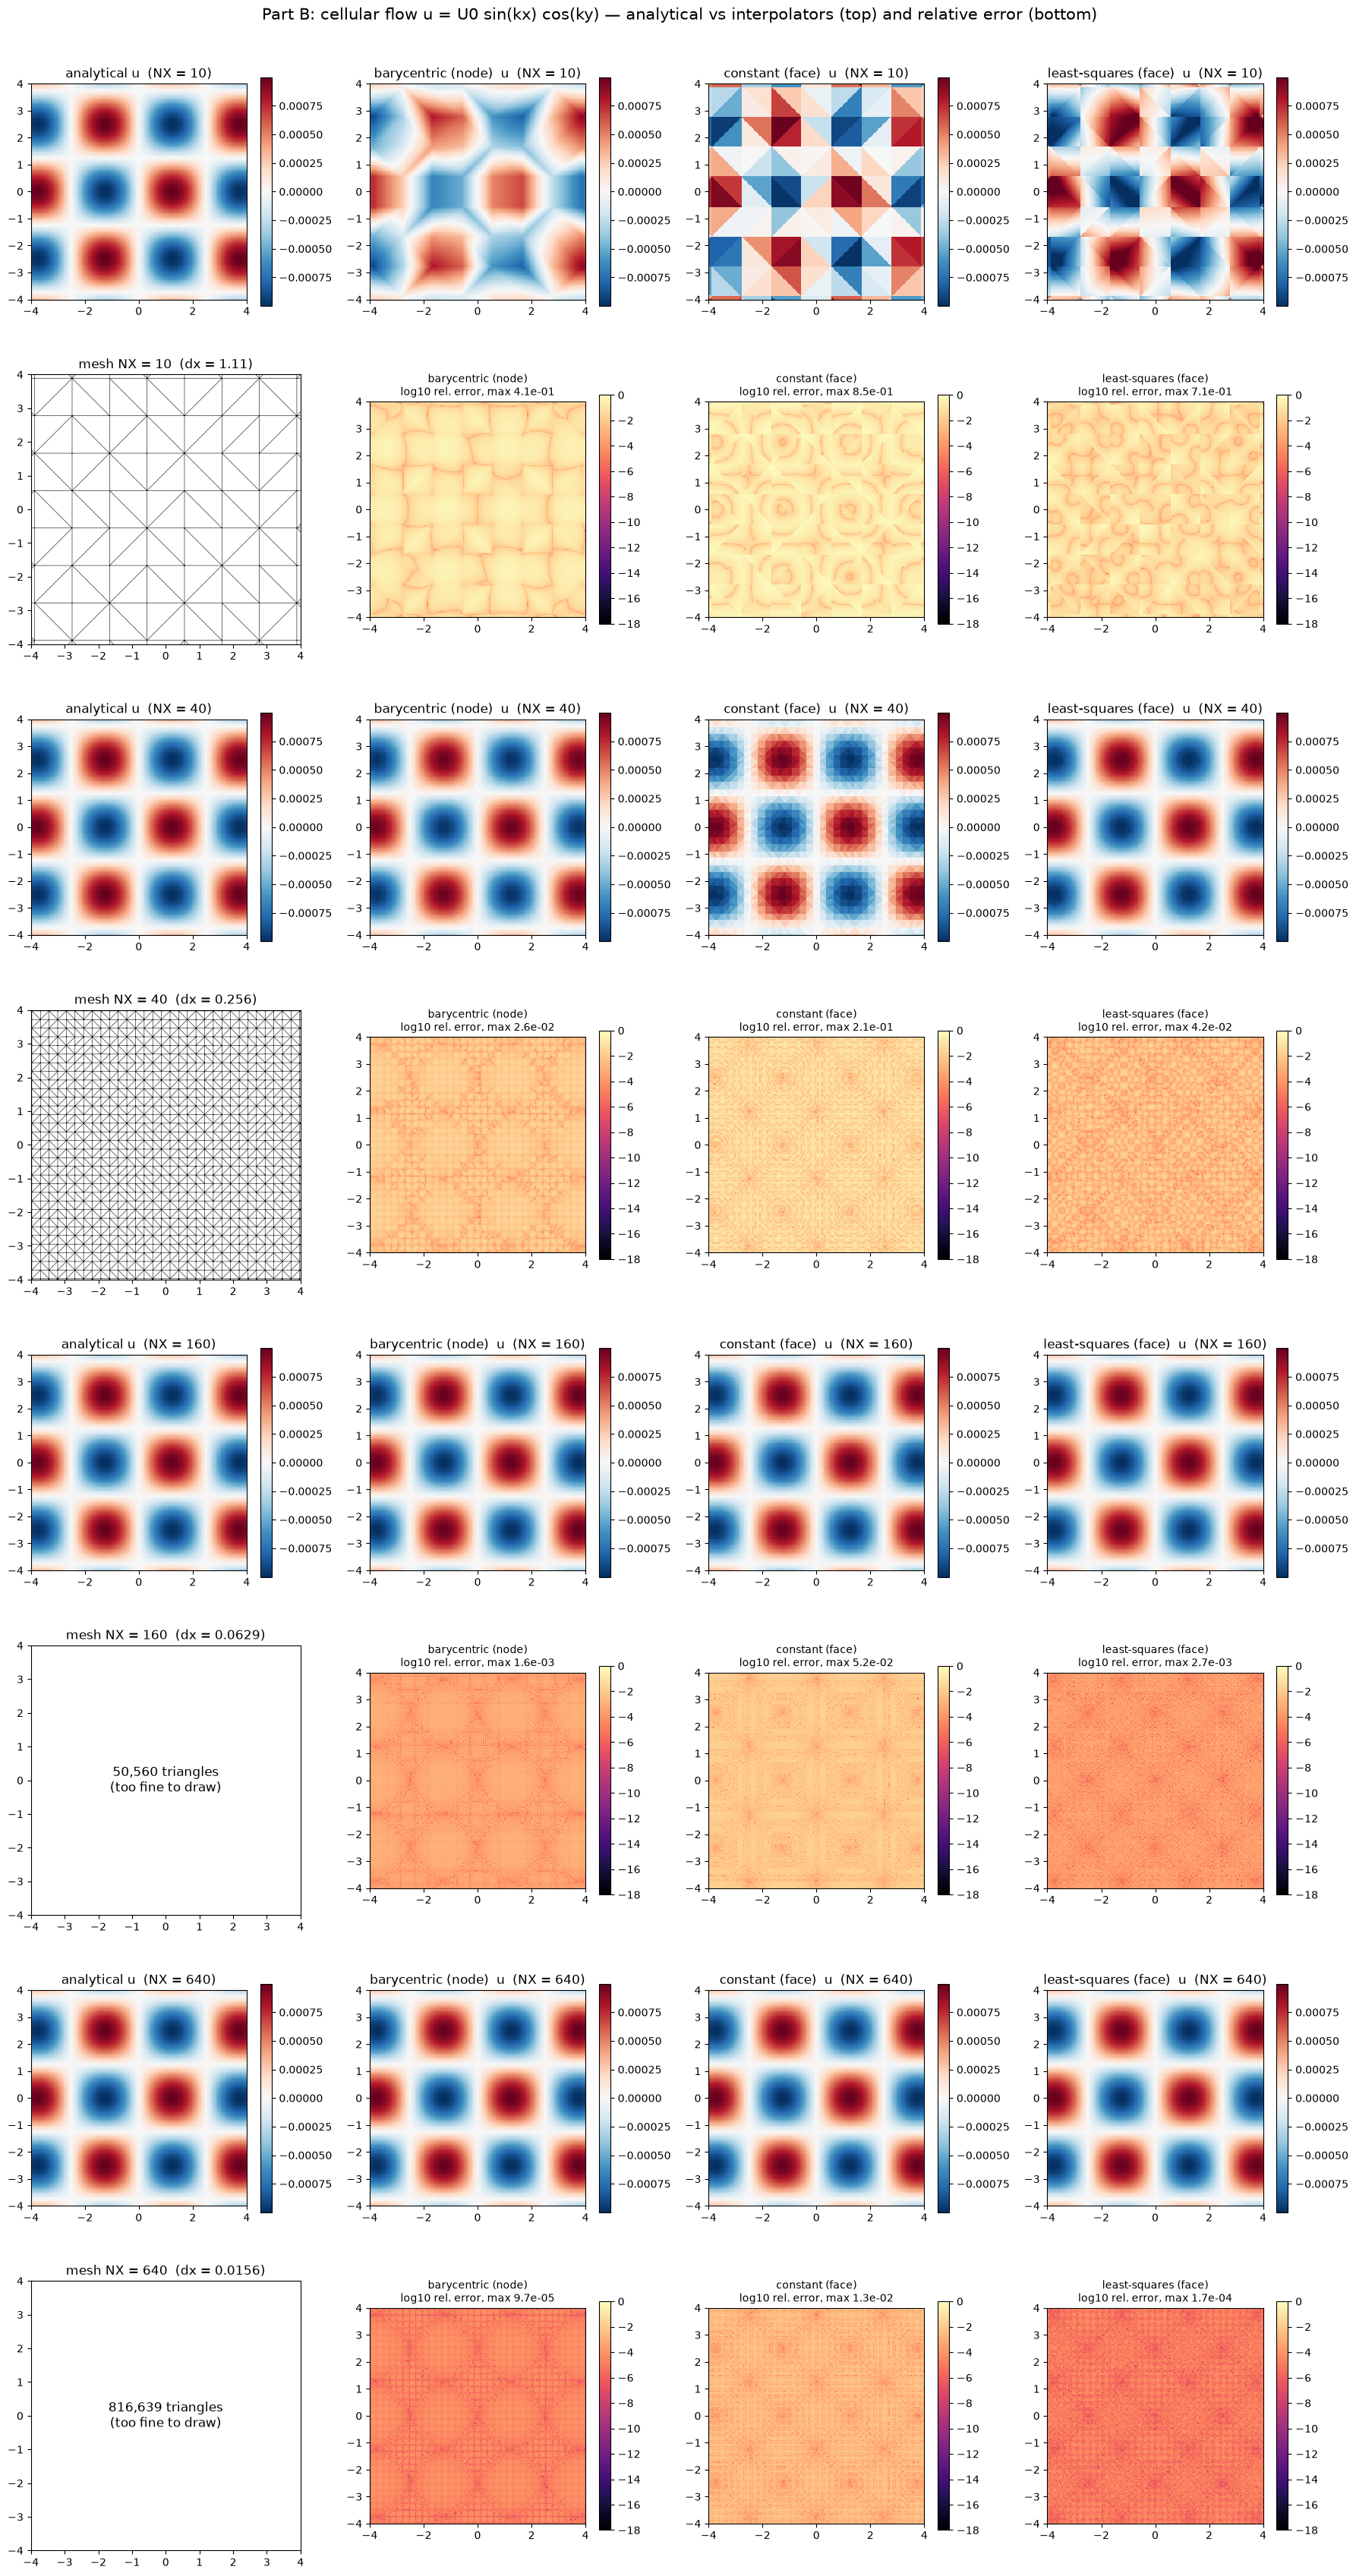

In [24]:
field_maps(cellular_uv, "Part B: cellular flow u = U0 sin(kx) cos(ky) — analytical vs interpolators (top) and relative error (bottom)")

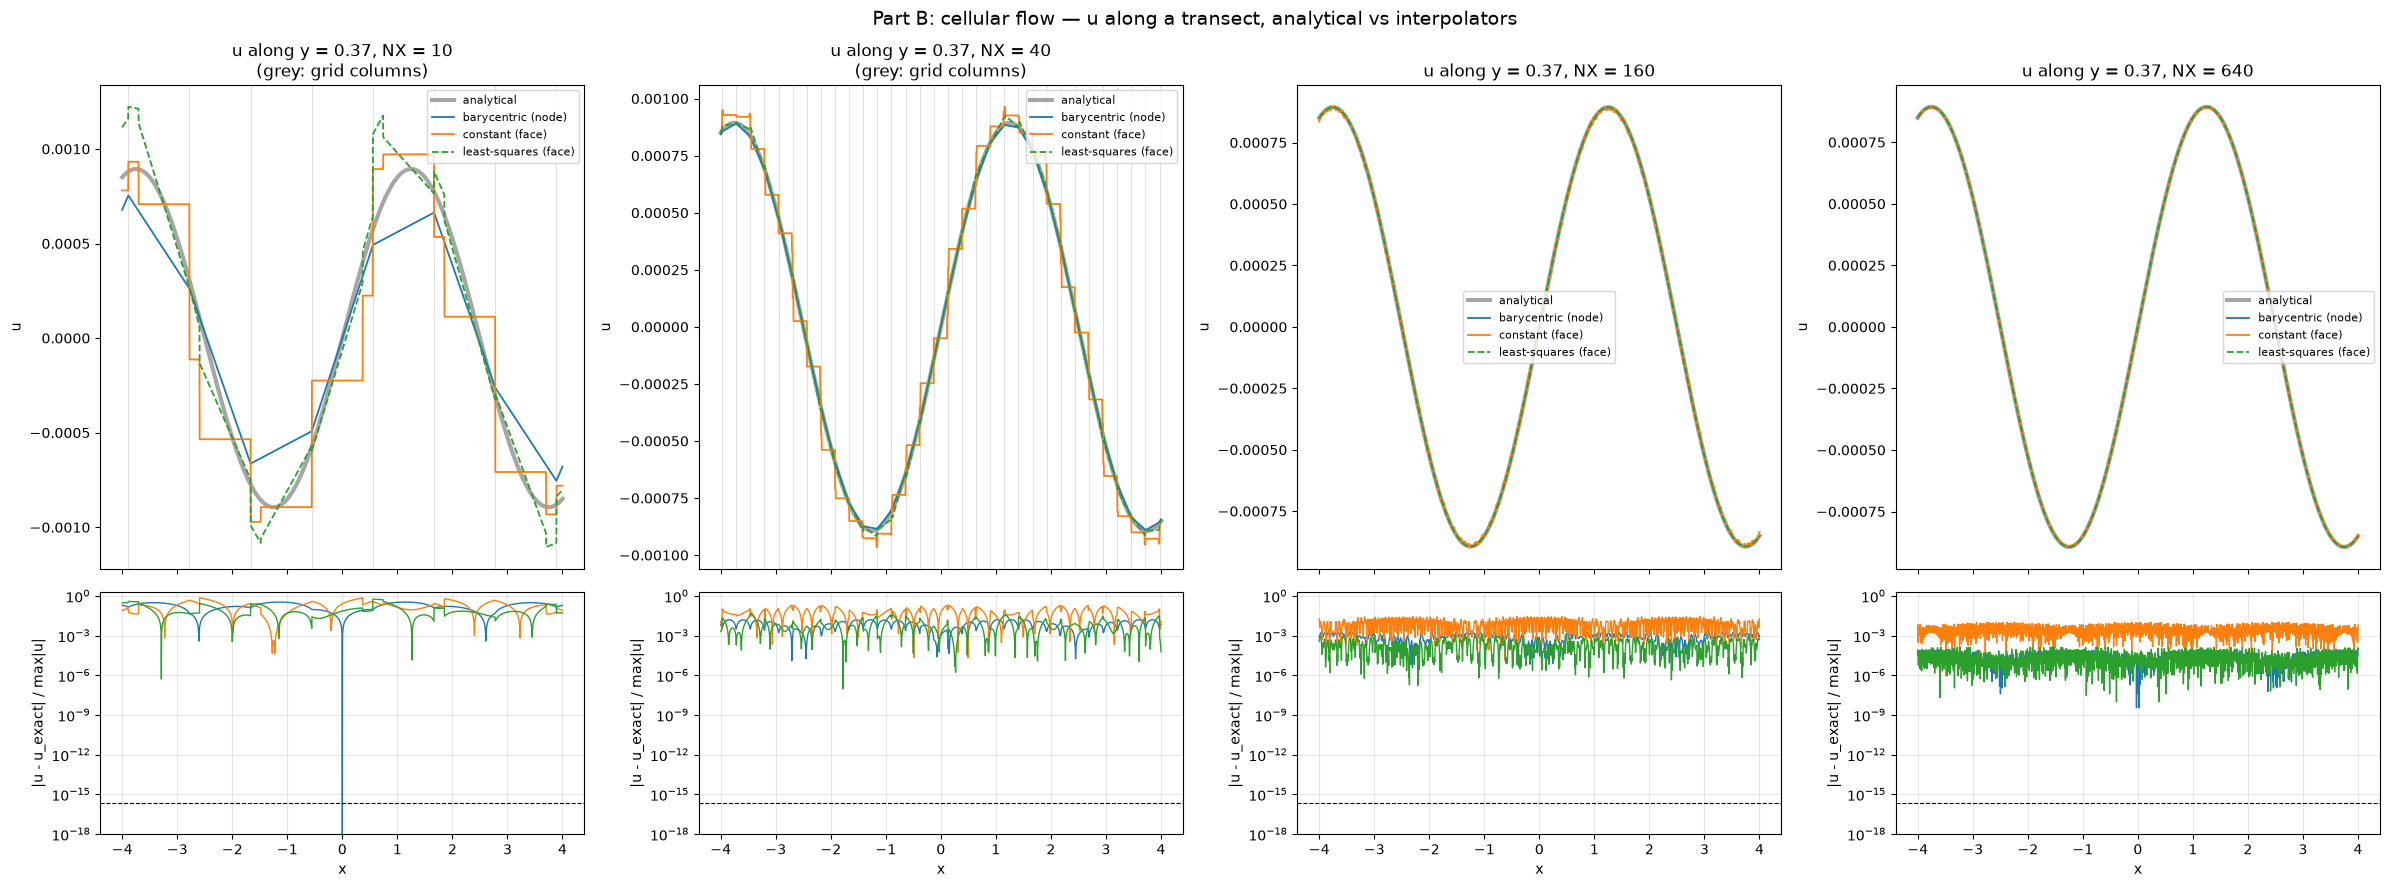

In [25]:
transect(cellular_uv, "Part B: cellular flow — u along a transect, analytical vs interpolators")

[Part B trajectories] 21 Parcels runs, 18 s wall on 21 processes
WARNING, run raised: ('B', 20, 'constant (face)', 10.0, 6000.0, 'B') GridSearchingError: Grid searching failed at (z=array([0.]), y=array([-4.99974621]), x=array([-0.16138114]))


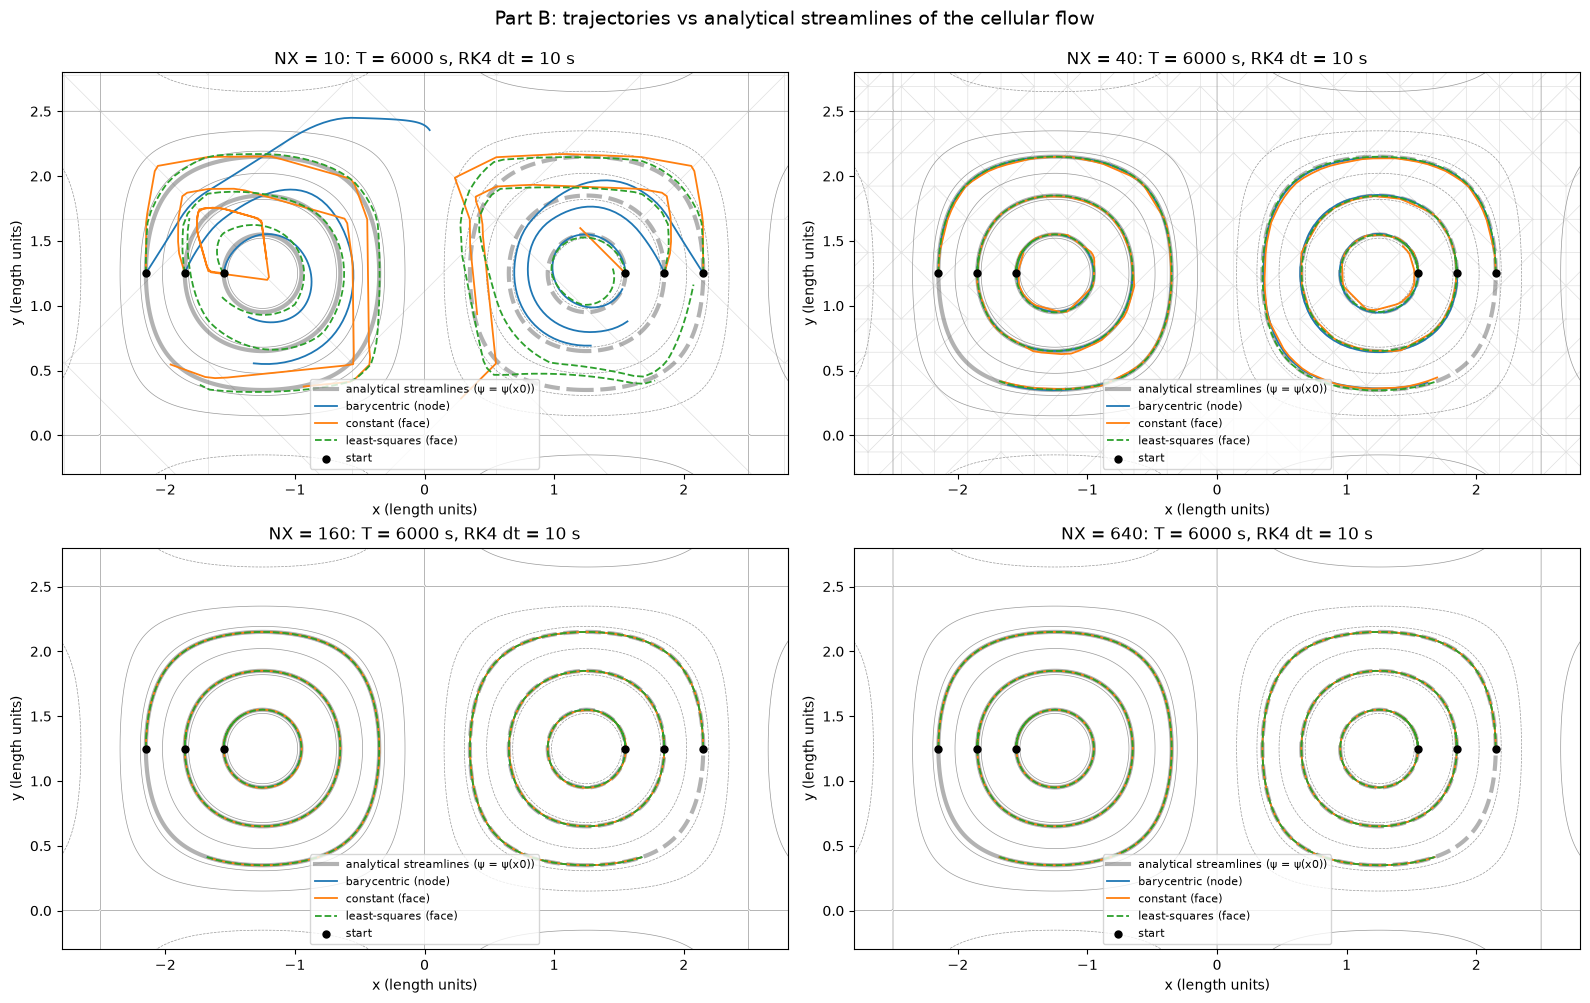

psi drift identical with the v1 sign of psi (bitwise): True
psi drift equal to the v1 table (4 significant digits): True


mean psi drift                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              1.789e-01       2.747e-01            1.264e-01   
40              5.771e-03       1.795e-02            2.577e-03   
160             1.244e-04       2.069e-03            5.182e-05   
640             4.265e-06       3.529e-04            2.638e-06   

            max psi drift                                       
scheme barycentric (node) constant (face) least-squares (face)  
NX                                                              
10              4.348e-01       6.079e-01            2.968e-01  
40              1.337e-02       2.533e-02            5.334e-03  
160             2.448e-04       2.870e-03            8.994e-05  
640             8.857e-06       5.657e-04            6.915e-06

In [26]:
psi = psi_cellular                                  # oceanographic convention (v1 used the opposite sign)
psi_v1 = lambda x, y: (U0 / K_WAVE) * np.sin(K_WAVE * x) * np.sin(K_WAVE * y)
psi_scale = PSI_SCALE_B
# two cells: centred at (1.25, 1.25) (psi < 0) and (-1.25, 1.25) (psi > 0); three orbits each
res_B = run_batch([dict(flow="B", nx=nx, scheme=s, dt=DT_VIS_B, T=T_VIS_B, pset="B", keep_every=int(CHUNK_B / DT_VIS_B),
                        keep_n=x0_B.size, purpose="B: trajectories (vis + reference study)")
                   for nx in NX_VALUES for s in SCHEMES], "Part B trajectories")
RB = {(r["key"][1], r["key"][2]): r for r in res_B}

V1_PSI_DRIFT = {  # v1 table (4 significant digits): (mean, max) per NX for barycentric / constant / least-squares
    "barycentric (node)": {10: (1.789e-01, 4.348e-01), 40: (5.771e-03, 1.337e-02), 160: (1.244e-04, 2.448e-04), 640: (4.265e-06, 8.857e-06)},
    "constant (face)": {10: (2.747e-01, 6.079e-01), 40: (1.795e-02, 2.533e-02), 160: (2.069e-03, 2.870e-03), 640: (3.529e-04, 5.657e-04)},
    "least-squares (face)": {10: (1.264e-01, 2.968e-01), 40: (2.577e-03, 5.334e-03), 160: (5.182e-05, 8.994e-05), 640: (2.638e-06, 6.915e-06)},
}

XS, YS = np.meshgrid(np.linspace(-VIS_HALF, VIS_HALF, 400), np.linspace(-VIS_HALF, VIS_HALF, 400))
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
psi_rows = []
for ax, nx in zip(axes.ravel(), VIS_NX):
    if nx <= MAX_NX_DRAW_MESH:
        ax.triplot(mesh_triangulation(nx), color="0.88", lw=0.5, zorder=0)
    ax.contour(XS, YS, psi(XS, YS), levels=np.unique(np.round(psi(x0_B, y0_B), 12)), colors="k", linewidths=3,
               alpha=0.3)
    ax.contour(XS, YS, psi(XS, YS), levels=12, colors="0.6", linewidths=0.5)
    ax.plot([], [], "k-", lw=3, alpha=0.3, label="analytical streamlines (ψ = ψ(x0))")
    for scheme in SCHEMES:
        xt, yt = RB[(nx, scheme)]["traj"]
        for i in range(x0_B.size):
            ax.plot(xt[:, i], yt[:, i], color=SCHEME_COLORS[scheme], lw=1.3,
                    ls="--" if scheme == "least-squares (face)" else "-", label=scheme if i == 0 else None)
        drift = np.max(np.abs(psi(xt, yt) - psi(x0_B, y0_B)[None, :]), axis=0) / psi_scale
        drift_v1sign = np.max(np.abs(psi_v1(xt, yt) - psi_v1(x0_B, y0_B)[None, :]), axis=0) / psi_scale
        assert np.array_equal(drift, drift_v1sign), "psi drift depends on the sign convention"
        m1, x1 = V1_PSI_DRIFT[scheme][nx]
        psi_rows.append({"NX": nx, "scheme": scheme, "mean psi drift": drift.mean(), "max psi drift": drift.max(),
                         "same as v1 (4 digits)": bool(np.isclose(drift.mean(), m1, rtol=5e-4) and np.isclose(drift.max(), x1, rtol=5e-4))})
    ax.scatter(x0_B, y0_B, c="k", s=25, zorder=5, label="start")
    ax.set_xlim(-2.8, 2.8); ax.set_ylim(-0.3, 2.8); ax.set_aspect("equal")
    ax.set_title(f"NX = {nx}: T = {T_VIS_B:.0f} s, RK4 dt = {DT_VIS_B:g} s")
    ax.set_xlabel("x (length units)"); ax.set_ylabel("y (length units)"); ax.legend(fontsize=8, loc="lower center")
fig.suptitle("Part B: trajectories vs analytical streamlines of the cellular flow", fontsize=14, y=0.995)
plt.tight_layout(); plt.show()
df_psi_vis = pd.DataFrame(psi_rows)
print("psi drift identical with the v1 sign of psi (bitwise): True")
print("psi drift equal to the v1 table (4 significant digits):", bool(df_psi_vis["same as v1 (4 digits)"].all()))
df_psi_vis.pivot(index="NX", columns="scheme", values=["mean psi drift", "max psi drift"])

**What to look for (Part B).** None of the schemes is exact here. On the coarse grid the constant-face field is
visibly blocky and its trajectories spiral off the streamlines; the two linear schemes follow the analytical field
and streamlines much more closely, and all three improve as $N_X$ goes from 10 to 640 — the first-order vs
second-order convergence quantified in the plot above (see the $\psi$-drift table).

**Interpretation (Part B).** On a field that none of the schemes represents exactly, the errors decay algebraically:
first order for the constant-face scheme and second order for the two linear reconstructions. Such an error only
approaches machine precision asymptotically; the extrapolated spacings $\Delta x_*$ needed for $10^{-16}$ are far below
any practical grid (and, for first order, below the float64 spacing of the coordinates). In practice the barycentric
node scheme would in addition stall at its float32 floor (~$10^{-7}$ relative) long before that — on the grids used here
its second-order truncation error is still well above that floor, so the floor is not visible in Part B.

## 6b. Part B — trajectory error against a reference (v2)

Reference trajectories: the analytical `cellular_uv` integrated with `scipy.integrate.solve_ivp` (DOP853,
`rtol=1e-13`, `atol=1e-15`) from the same start points. 500 particles are placed uniformly at random in the four central
cells, keeping a margin $0.1/k$ from the separatrices ($\sin kx=0$ or $\sin ky=0$), where orbit periods diverge. They
were integrated in the same Parcels runs as the visualisation particles ($T=6000$ s, $\Delta t=10$ s, all $N_X$).
Errors: final-position error (length units) and $\psi$ drift $\max_t|\psi-\psi_0|/(U_0/k)$ over **every** RK4 step.

In [27]:
nB = PSETS["B"][0].size


def cellular_rhs(t, s):
    u, v = cellular_uv(s[:nB], s[nB:])
    return np.concatenate([u, v])


t0 = time.time()
sol = solve_ivp(cellular_rhs, (0.0, T_VIS_B), np.concatenate(PSETS["B"]), method="DOP853", rtol=1e-13, atol=1e-15)
XB_REF, YB_REF = sol.y[:nB, -1], sol.y[nB:, -1]
ref_drift = np.abs(psi_cellular(XB_REF, YB_REF) - psi_cellular(*PSETS["B"])) / PSI_SCALE_B
print(f"DOP853 reference: {sol.t.size} steps, {time.time() - t0:.1f} s; psi drift of the reference: max {ref_drift.max():.1e}")


def err_B(r, idx=IDX_B_REF):
    e = np.hypot(r["x"][idx] - XB_REF[idx], r["y"][idx] - YB_REF[idx])
    return np.full_like(e, np.nan) if r["error"] else e


rows_B6 = []
for nx in NX_VALUES:
    for scheme in SCHEMES:
        r = RB[(nx, scheme)]
        e, dr = err_B(r), r["psi_drift"][IDX_B_REF] * (np.nan if r["error"] else 1.0)
        rows_B6.append({"NX": nx, "dx": DX[nx], "scheme": scheme, "traj_mean": e.mean(), "traj_max": e.max(),
                        "psi_drift_mean": dr.mean(), "psi_drift_max": dr.max(), "states": states_str(r)})
df_B6 = pd.DataFrame(rows_B6)
fit_rows_B6 = []
for scheme in SCHEMES:
    a = df_B6[(df_B6["scheme"] == scheme) & (df_B6["NX"] >= ASYMPTOTIC_NX)]
    for metric in ["traj_mean", "traj_max", "psi_drift_mean", "psi_drift_max"]:
        fit_rows_B6.append({"scheme": scheme, "metric": metric,
                            f"slope (NX>={ASYMPTOTIC_NX})": fit_slope(a["dx"].values, a[metric].values)[0]})
df_fit_B6 = pd.DataFrame(fit_rows_B6)
display(df_B6.pivot(index="NX", columns="scheme", values=["traj_mean", "traj_max", "psi_drift_mean", "psi_drift_max"]))
df_fit_B6.pivot(index="metric", columns="scheme", values=f"slope (NX>={ASYMPTOTIC_NX})")

DOP853 reference: 65 steps, 0.0 s; psi drift of the reference: max 2.2e-14


traj_mean                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              1.557e+00       1.448e+00            3.889e-01   
20              3.087e-01             NaN            9.061e-02   
40              6.591e-02       1.644e-01            2.273e-02   
80              1.764e-02       3.545e-02            5.885e-03   
160             4.255e-03       1.227e-02            1.426e-03   
320             1.074e-03       2.583e-03            3.572e-04   
640             2.665e-04       1.062e-03            8.785e-05   

                 traj_max                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              5.208e+00       5.620e+00            4.908e+00   
20              2.166e+00             NaN            5.272e-01   
40              2.852e-01       3.318e+00            1.197e-01   
80              3.786e-02       1.867e+00            3.402e-02   
160             9.115e-03       1.220e+00            3.557e-03   
320             2.583e-03       1.664e-02            9.113e-04   
640             4.756e-04       9.012e-03            1.920e-04   

           psi_drift_mean                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              3.889e-01       3.125e-01            1.310e-01   
20              3.391e-02             NaN            1.816e-02   
40              6.869e-03       2.875e-02            3.631e-03   
80              1.096e-03       8.427e-03            5.513e-04   
160             2.048e-04       2.607e-03            9.796e-05   
320             3.495e-05       8.555e-04            1.750e-05   
640             5.997e-06       3.797e-04            3.678e-06   

            psi_drift_max                                       
scheme barycentric (node) constant (face) least-squares (face)  
NX                                                              
10              1.103e+00       9.661e-01            3.784e-01  
20              1.217e-01             NaN            6.472e-02  
40              2.104e-02       1.471e-01            1.433e-02  
80              3.540e-03       5.188e-02            1.737e-03  
160             7.021e-04       2.568e-02            4.573e-04  
320             9.115e-05       2.090e-03            4.623e-05  
640             1.915e-05       1.153e-03            1.097e-05

scheme,barycentric (node),constant (face),least-squares (face)
metric,,,
psi_drift_max,2.540e+00,1.999e+00,2.509e+00
psi_drift_mean,2.496e+00,1.495e+00,2.404e+00
traj_max,2.065e+00,2.912e+00,2.425e+00
traj_mean,2.003e+00,1.734e+00,2.009e+00


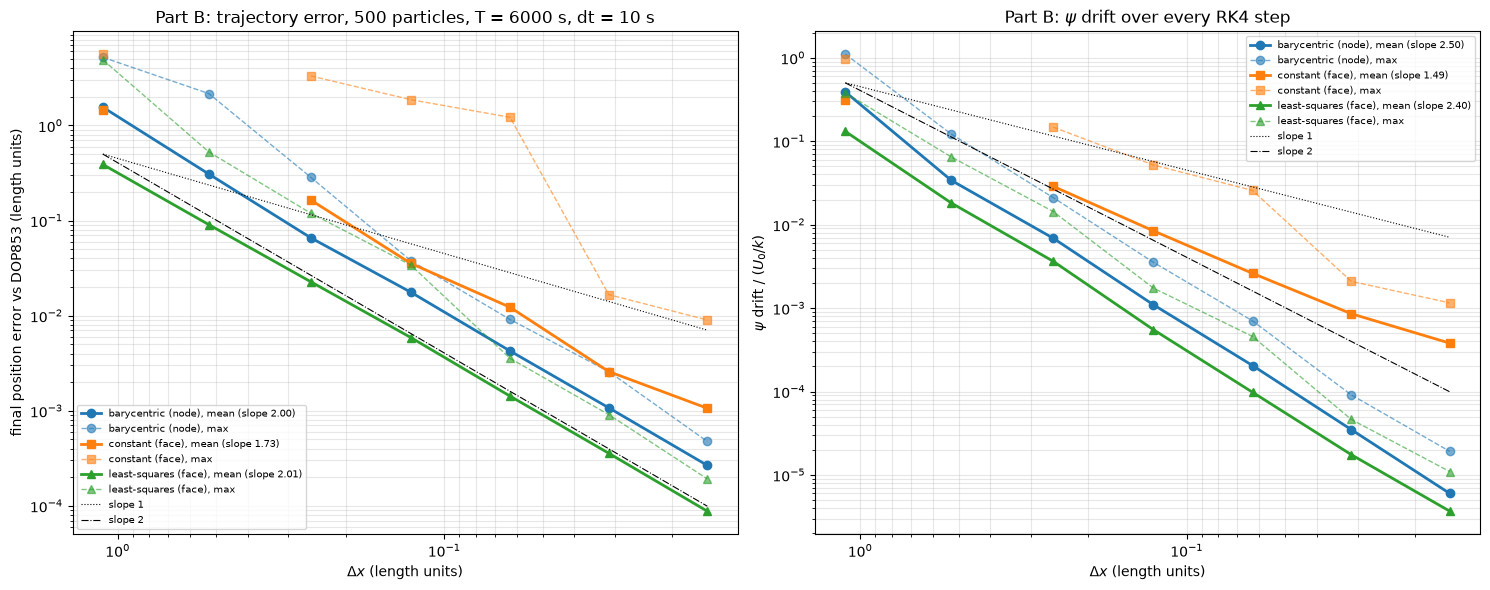

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (m, lab) in zip(axes, [("traj", "final position error vs DOP853 (length units)"), ("psi_drift", r"$\psi$ drift / $(U_0/k)$")]):
    for scheme in SCHEMES:
        s = df_B6[df_B6["scheme"] == scheme]
        p = slope_val = df_fit_B6[(df_fit_B6.scheme == scheme) & (df_fit_B6.metric == f"{m}_mean")][f"slope (NX>={ASYMPTOTIC_NX})"].iloc[0]
        ax.loglog(s["dx"], s[f"{m}_mean"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=2,
                  label=f"{scheme}, mean (slope {p:.2f})")
        ax.loglog(s["dx"], s[f"{m}_max"], marker=MARKERS[scheme], color=SCHEME_COLORS[scheme], lw=1, ls="--", alpha=0.6,
                  label=f"{scheme}, max")
    for order, ls in [(1, ":"), (2, "-.")]:
        ax.loglog(dxs, 0.5 * (dxs / dxs[0]) ** order, color="k", ls=ls, lw=0.8, label=f"slope {order}")
    ax.set_xlabel(r"$\Delta x$ (length units)"); ax.set_ylabel(lab); ax.invert_xaxis()
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
axes[0].set_title(f"Part B: trajectory error, {N_REF_B} particles, T = {T_VIS_B:.0f} s, dt = {DT_VIS_B:g} s")
axes[1].set_title(r"Part B: $\psi$ drift over every RK4 step")
plt.tight_layout(); plt.show()

**What to look for (Section 6b).** Unlike the direct error, this is the error that a user of the trajectories sees.
The two linear reconstructions should converge at second order and the constant-face scheme at first order (slopes in the
legend, fitted for $N_X\ge80$). The $\psi$ drift should follow the same orders; a trajectory error that is larger than
the drift times the cell size means the particle moves along its orbit at the wrong speed (phase error) rather than
leaving the orbit. At $N_X=10$ (one or two cells per half-wavelength) all schemes are outside the asymptotic range.

## 6c. Converged answer per resolution ($\Delta t$ convergence on every grid) and fixed CFL vs fixed $\Delta t$ (v2)

For $N_X\in\{10,40,160,640\}$, each scheme, Part A (18 particles, $T=360$ s) and Part B (500 reference particles,
$T=6000$ s): RK4 with a halving sequence $\Delta t_k=\Delta t_\text{nb}\,2^k$, starting at the largest $k$ with
CFL$_\max\le0.5$ (CFL$_\max$ over all cells, Section 6d) and ending at the notebook time step $\Delta t_\text{nb}$
(0.5 s Part A, 10 s Part B; at least one halving, so Part B at $N_X=640$, where 10 s has CFL 0.64, ends at 2.5 s).
**Deviation from the request:** the sequence is *not* continued to $10^{-3}$ s (a run that never meets the $10^{-12}$
criterion would need ~$7\times10^5$ steps, hours per run); the user decided to keep the notebook within 5-10 min.
The change of the final positions over the last halving, $\max_p|\mathbf{x}_{\Delta t}-\mathbf{x}_{2\Delta t}|$, is the
time-error estimate; the answer counts as $\Delta t$-converged when it is below $10^{-12}L$ ($L=10$).

Second experiment, all $N_X$: **fixed CFL** — $\Delta t\propto\Delta x$ such that CFL$_\max=0.5$ on every grid — against
**fixed $\Delta t$** (0.5 s Part A, 10 s Part B).

In [29]:
BASE_DT = {"A": DT_S, "B": DT_VIS_B}
T_RUN = {"A": T_TOTAL_S, "B": T_VIS_B}
S5_NX = [10, 40, 160, 640]


def cfl_per_dt(flow, nx):
    # CFL_max per second of dt: max over all cells of |u(centroid)| / shortest edge
    g = GEOM[nx]
    return np.max(g[f"speed_c_{flow}"] / g["dx_short"])


def dt_for_cfl(flow, nx, c=0.5):
    return c / cfl_per_dt(flow, nx)


def halving_dts(flow, nx):
    base = BASE_DT[flow]
    k_max = int(np.floor(np.log2(dt_for_cfl(flow, nx) / base)))
    return [base * 2.0 ** k for k in range(k_max, min(0, k_max - 1) - 1, -1)]


tasks = []
for flow in ["A", "B"]:
    for nx in S5_NX:
        for s in SCHEMES:
            tasks += [dict(flow=flow, nx=nx, scheme=s, dt=d, T=T_RUN[flow], pset=flow, purpose=f"{flow}: dt halving")
                      for d in halving_dts(flow, nx)]
    for nx in NX_VALUES:
        tasks += [dict(flow=flow, nx=nx, scheme=s, dt=dt_for_cfl(flow, nx), T=T_RUN[flow], pset=flow,
                       purpose=f"{flow}: fixed CFL 0.5") for s in SCHEMES]
_ = run_batch(tasks, "dt halving + fixed CFL")


def final_err(flow, r):
    return err_A(r) if flow == "A" else err_B(r)


IDX_OF = {"A": IDX_ORIG, "B": IDX_B_REF}
conv_rows, seq_rows = [], []
for flow in ["A", "B"]:
    for nx in S5_NX:
        for s in SCHEMES:
            dts_ = halving_dts(flow, nx)
            rs = [RESULTS[(flow, nx, s, float(d), float(T_RUN[flow]), flow)] for d in dts_]
            idx = IDX_OF[flow]
            for k, (d, r) in enumerate(zip(dts_, rs)):
                ch = np.nan if k == 0 else np.max(np.hypot(r["x"][idx] - rs[k - 1]["x"][idx], r["y"][idx] - rs[k - 1]["y"][idx]))
                seq_rows.append({"flow": flow, "NX": nx, "scheme": s, "dt": d, "CFL_max": cfl_per_dt(flow, nx) * d,
                                 "change vs 2 dt": ch, "mean error": final_err(flow, r).mean()})
            ch_last = seq_rows[-1]["change vs 2 dt"]
            e = final_err(flow, rs[-1])
            conv_rows.append({"flow": flow, "NX": nx, "dx": DX[nx], "scheme": s, "dt sequence": " > ".join(f"{d:g}" for d in dts_),
                              "dt_converged": dts_[-1], "CFL_max at dt_conv": cfl_per_dt(flow, nx) * dts_[-1],
                              "time-error estimate": ch_last, "dt-converged (<1e-12 L)": bool(ch_last < 1e-12 * DOMAIN_L),
                              "error mean": e.mean(), "error max": e.max(), "error / time-error": e.mean() / ch_last})
df_conv = pd.DataFrame(conv_rows)
df_seq = pd.DataFrame(seq_rows)
df_conv

[dt halving + fixed CFL] 121 Parcels runs, 81 s wall on 24 processes
WARNING, run raised: ('B', 20, 'constant (face)', 263.6579076615509, 6000.0, 'B') GridSearchingError: Grid searching failed at (z=array([0.]), y=array([-4.95662658]), x=array([-0.08992503]))


,flow,NX,dx,scheme,dt sequence,dt_converged,CFL_max at dt_conv,time-error estimate,dt-converged (<1e-12 L),error mean,error max,error / time-error
0,A,10,1.111e+00,barycentric (node),64 > 32 > 16 > 8 > 4 > 2 > 1 > 0.5,5.000e-01,2.831e-03,1.016e-09,False,3.014e-10,7.315e-10,2.967e-01
1,A,10,1.111e+00,constant (face),64 > 32 > 16 > 8 > 4 > 2 > 1 > 0.5,5.000e-01,2.831e-03,2.928e-04,False,6.394e-02,1.769e-01,2.184e+02
2,A,10,1.111e+00,least-squares (face),64 > 32 > 16 > 8 > 4 > 2 > 1 > 0.5,5.000e-01,2.831e-03,1.631e-14,True,1.483e-15,3.109e-15,9.095e-02
3,A,40,2.564e-01,barycentric (node),16 > 8 > 4 > 2 > 1 > 0.5,5.000e-01,1.344e-02,1.005e-09,False,3.016e-10,7.417e-10,3.002e-01
4,A,40,2.564e-01,constant (face),16 > 8 > 4 > 2 > 1 > 0.5,5.000e-01,1.344e-02,1.581e-04,False,1.504e-02,6.057e-02,9.513e+01
5,A,40,2.564e-01,least-squares (face),16 > 8 > 4 > 2 > 1 > 0.5,5.000e-01,1.344e-02,1.631e-14,True,1.443e-15,3.109e-15,8.850e-02
6,A,160,6.289e-02,barycentric (node),4 > 2 > 1 > 0.5,5.000e-01,5.586e-02,1.122e-09,False,3.027e-10,6.829e-10,2.697e-01
7,A,160,6.289e-02,constant (face),4 > 2 > 1 > 0.5,5.000e-01,5.586e-02,7.300e-05,False,2.056e-03,5.988e-03,2.817e+01
8,A,160,6.289e-02,least-squares (face),4 > 2 > 1 > 0.5,5.000e-01,5.586e-02,1.631e-14,True,1.482e-15,3.109e-15,9.087e-02
9,A,640,1.565e-02,barycentric (node),1 > 0.5,5.000e-01,2.256e-01,1.106e-09,False,3.443e-10,8.101e-10,3.115e-01


scheme              barycentric (node)  constant (face)  least-squares (face)
flow NX  dt                                                                  
A    10  3.200e+01           1.818e-07        1.593e-02             1.759e-07
         1.600e+01           1.321e-08        9.368e-03             1.224e-08
         8.000e+00           5.015e-09        1.976e-03             7.749e-10
         4.000e+00           5.163e-09        2.343e-03             4.986e-11
         2.000e+00           4.126e-09        1.647e-03             3.129e-12
         1.000e+00           1.791e-09        5.855e-04             1.916e-13
         5.000e-01           1.016e-09        2.928e-04             1.631e-14
     40  8.000e+00           5.513e-09        4.015e-03             7.749e-10
         4.000e+00           4.321e-09        2.222e-03             4.986e-11
         2.000e+00           3.953e-09        9.121e-04             3.128e-12
         1.000e+00           1.941e-09        3.587e-04             1.916e-13
         5.000e-01           1.005e-09        1.581e-04             1.631e-14
     160 2.000e+00           4.880e-09        2.817e-04             3.128e-12
         1.000e+00           1.984e-09        1.750e-04             1.916e-13
         5.000e-01           1.122e-09        7.300e-05             1.631e-14
     640 5.000e-01           1.106e-09        3.955e-05             1.716e-14
B    10  1.600e+02           1.084e-01        3.211e+00             1.330e+00
         8.000e+01           5.438e-02        3.136e+00             6.439e-01
         4.000e+01           8.646e-03        2.880e+00             3.355e-01
         2.000e+01           2.753e-03        2.879e+00             7.573e-01
         1.000e+01           4.084e-04        1.292e+00             3.485e-01
     40  4.000e+01           2.913e-03        2.373e+00             4.346e-02
         2.000e+01           1.300e-03        3.306e+00             2.638e-02
         1.000e+01           3.727e-04        3.287e+00             1.156e-02
     160 1.000e+01           1.814e-04        2.400e-02             2.561e-03
     640 2.500e+00           6.067e-06        2.103e-03             8.771e-05

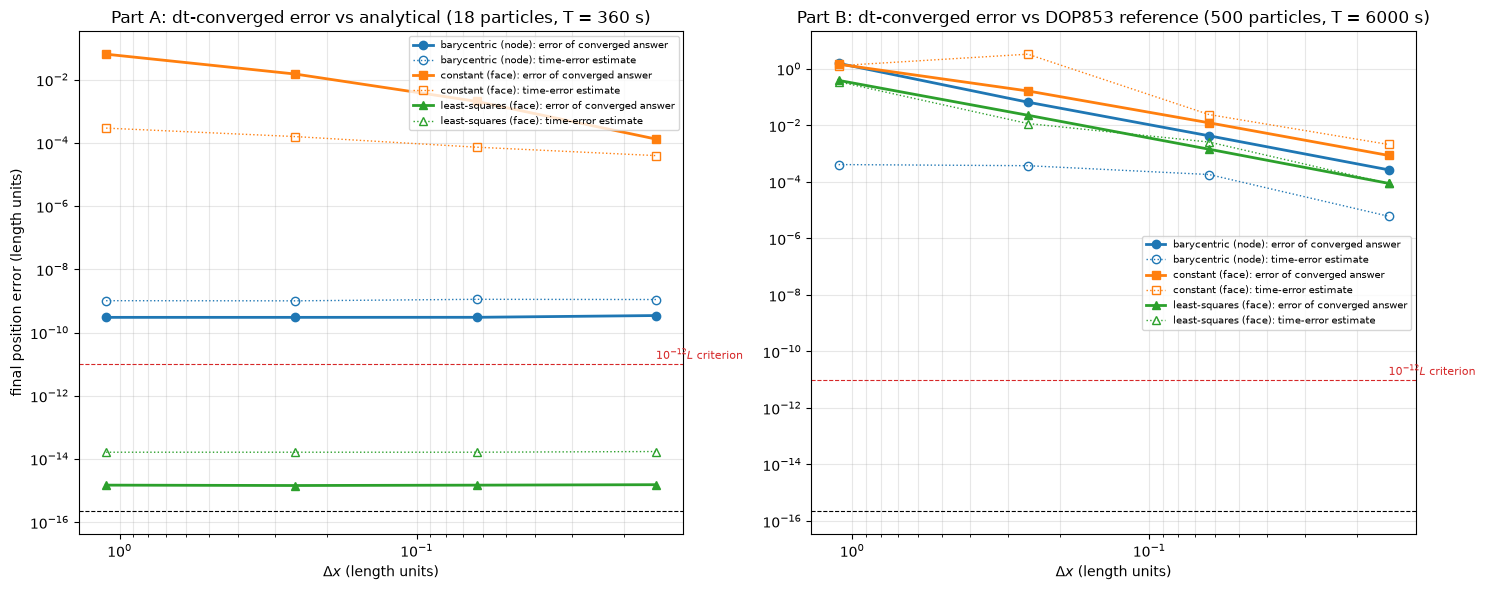

In [30]:
display(df_seq.pivot_table(index=["flow", "NX", "dt"], columns="scheme", values="change vs 2 dt").sort_index(ascending=[True, True, False]))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, flow in zip(axes, ["A", "B"]):
    for s in SCHEMES:
        c = df_conv[(df_conv.flow == flow) & (df_conv.scheme == s)]
        ax.loglog(c["dx"], c["error mean"], marker=MARKERS[s], color=SCHEME_COLORS[s], lw=2, label=f"{s}: error of converged answer")
        ax.loglog(c["dx"], c["time-error estimate"], marker=MARKERS[s], color=SCHEME_COLORS[s], lw=1, ls=":", mfc="none",
                  label=f"{s}: time-error estimate")
    ax.axhline(EPS64, color="k", ls="--", lw=0.8); ax.axhline(1e-12 * DOMAIN_L, color="C3", ls="--", lw=0.8)
    ax.text(DX[640], 1.4e-11, r"$10^{-12}L$ criterion", color="C3", fontsize=8)
    ax.set_xlabel(r"$\Delta x$ (length units)"); ax.invert_xaxis(); ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
axes[0].set_ylabel("final position error (length units)")
axes[0].set_title("Part A: dt-converged error vs analytical (18 particles, T = 360 s)")
axes[1].set_title("Part B: dt-converged error vs DOP853 reference (500 particles, T = 6000 s)")
plt.tight_layout(); plt.show()

**What to look for (converged answer).** Solid lines: error of the finest-$\Delta t$ answer on each grid, i.e. the spatial
error with the time error removed (to within the dotted time-error estimate). Wherever solid lies far above dotted, the
answer is converged in $\Delta t$ for practical purposes, and the solid curve differs between low and high resolution exactly
as the interpolation scheme dictates: flat at round-off (least-squares, Part A) or at the float32 floor (barycentric, Part A),
first order (constant face) and second order (linear schemes, Part B). A dotted value below the red line means the strict
$10^{-12}L$ criterion is met.

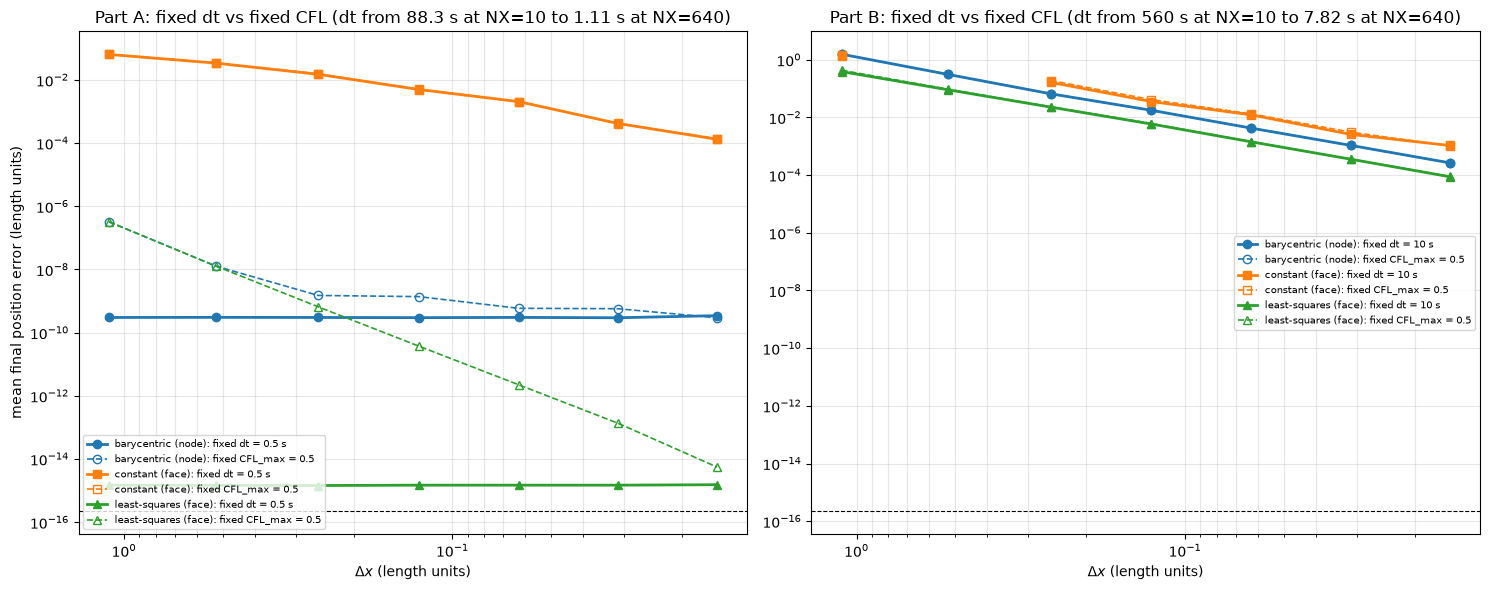

err fixed CFL                                       \
scheme   barycentric (node) constant (face) least-squares (face)   
flow NX                                                            
A    10           3.208e-07       6.518e-02            3.233e-07   
     20           1.279e-08       3.425e-02            1.290e-08   
     40           1.502e-09       1.566e-02            6.556e-10   
     80           1.378e-09       5.059e-03            3.725e-11   
     160          5.879e-10       2.049e-03            2.236e-12   
     320          5.712e-10       4.140e-04            1.354e-13   
     640          2.949e-10       1.394e-04            5.536e-15   
B    10           1.556e+00       1.363e+00            4.316e-01   
     20           3.088e-01             NaN            9.540e-02   
     40           6.592e-02       1.904e-01            2.332e-02   
     80           1.764e-02       4.134e-02            6.142e-03   
     160          4.255e-03       1.330e-02            1.437e-03   
     320          1.074e-03       3.100e-03            3.582e-04   
     640          2.663e-04       1.030e-03            8.956e-05   

               err fixed dt                                       
scheme   barycentric (node) constant (face) least-squares (face)  
flow NX                                                           
A    10           3.014e-10       6.394e-02            1.483e-15  
     20           3.042e-10       3.412e-02            1.463e-15  
     40           3.016e-10       1.504e-02            1.443e-15  
     80           2.976e-10       4.958e-03            1.482e-15  
     160          3.027e-10       2.056e-03            1.482e-15  
     320          2.953e-10       4.177e-04            1.482e-15  
     640          3.443e-10       1.318e-04            1.531e-15  
B    10           1.557e+00       1.448e+00            3.889e-01  
     20           3.087e-01             NaN            9.061e-02  
     40           6.591e-02       1.644e-01            2.273e-02  
     80           1.764e-02       3.545e-02            5.885e-03  
     160          4.255e-03       1.227e-02            1.426e-03  
     320          1.074e-03       2.583e-03            3.572e-04  
     640          2.665e-04       1.062e-03            8.785e-05

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, flow in zip(axes, ["A", "B"]):
    for s in SCHEMES:
        e_dt = [final_err(flow, RESULTS[(flow, nx, s, float(BASE_DT[flow]), float(T_RUN[flow]), flow)]).mean() for nx in NX_VALUES]
        e_cfl = [final_err(flow, RESULTS[(flow, nx, s, float(dt_for_cfl(flow, nx)), float(T_RUN[flow]), flow)]).mean() for nx in NX_VALUES]
        ax.loglog(dxs, e_dt, marker=MARKERS[s], color=SCHEME_COLORS[s], lw=2, label=f"{s}: fixed dt = {BASE_DT[flow]:g} s")
        ax.loglog(dxs, e_cfl, marker=MARKERS[s], color=SCHEME_COLORS[s], lw=1.2, ls="--", mfc="none", label=f"{s}: fixed CFL_max = 0.5")
    ax.axhline(EPS64, color="k", ls="--", lw=0.8)
    ax.set_xlabel(r"$\Delta x$ (length units)"); ax.invert_xaxis(); ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
axes[0].set_ylabel("mean final position error (length units)")
FIXED_CMP = pd.DataFrame([{"flow": f, "NX": nx, "scheme": s, "dt fixed-CFL [s]": dt_for_cfl(f, nx),
    "err fixed dt": final_err(f, RESULTS[(f, nx, s, float(BASE_DT[f]), float(T_RUN[f]), f)]).mean(),
    "err fixed CFL": final_err(f, RESULTS[(f, nx, s, float(dt_for_cfl(f, nx)), float(T_RUN[f]), f)]).mean()}
    for f in ["A", "B"] for nx in NX_VALUES for s in SCHEMES])
axes[0].set_title("Part A: fixed dt vs fixed CFL (dt from %.3g s at NX=10 to %.3g s at NX=640)" % (dt_for_cfl("A", 10), dt_for_cfl("A", 640)))
axes[1].set_title("Part B: fixed dt vs fixed CFL (dt from %.3g s at NX=10 to %.3g s at NX=640)" % (dt_for_cfl("B", 10), dt_for_cfl("B", 640)))
plt.tight_layout(); plt.show()
FIXED_CMP.pivot_table(index=["flow", "NX"], columns="scheme", values=["err fixed dt", "err fixed CFL"])

**What to look for (fixed CFL vs fixed $\Delta t$).** With a fixed $\Delta t$ the RK4 time error is the same on every grid,
so the curves show the spatial error alone until they meet the time-error floor. With a fixed CFL, $\Delta t\propto\Delta x$:
on coarse grids $\Delta t$ is large (tens to hundreds of seconds), the RK4 error ($\propto\Delta t^4$ for smooth fields) is
added to the spatial error, and refining the grid reduces both together. For a scheme whose spatial error is at round-off
(least-squares, Part A) the fixed-CFL curve therefore *is* the RK4 time error and falls as $\Delta x^4$; for first- and
second-order schemes the spatial error dominates and both curves nearly coincide. The difference between the two
experiments is the time error.

## 6d. CFL diagnostics (v2)

Definitions:

* **Per-cell length scale.** (a) primary: the shortest edge of the triangle, $\Delta x_\text{cell}$ (equal to the lattice
  spacing $\Delta x$ here); (b) $\sqrt{2A}$, the side of a right isosceles triangle of the same area $A$ (also $\Delta x$ here,
  since every triangle is half a lattice square).
* **Per-cell speed.** $|\mathbf{u}|$ of the analytical field at the face centroid (primary), and the maximum of
  $|\mathbf{u}|$ over the three nodes.
* $\mathrm{CFL}_\text{cell}=|\mathbf{u}|\,\Delta t/\Delta x_\text{cell}$: the fraction of a cell a particle crosses in one step.
* **Particle-based CFL:** the same quantity at the particle positions, at every RK4 step of every run.
* $|\nabla\mathbf{u}|\,\Delta t$ — $\varepsilon\Delta t$ (Part A), $U_0k\Delta t$ (Part B).

The CFL number is a *spatial* sampling statement: CFL $>1$ means a particle can skip a cell within one step, so the RK4
stages sample the interpolated field on a coarser path than the mesh resolves (and, for discontinuous face fields, steps
over the discontinuities). It does not govern stability of the ODE integration. $|\nabla\mathbf{u}|\Delta t$ is the
quantity in the RK4 stability and accuracy analysis ($\lambda\Delta t$ for $\dot{\mathbf x}=\mathbf u(\mathbf x)$): RK4 is stable
for $|\lambda\Delta t|\lesssim2.8$ and its local error scales as $(|\nabla\mathbf u|\Delta t)^5$. Here
$|\nabla\mathbf u|\Delta t\ll1$ in every run, so the ODE integration is always well inside its stability region, even
where the CFL number exceeds 1.

The first table covers every (flow, $N_X$, $\Delta t$) combination actually run (statistics over all cells, and over the
cells visited by the particles of that combination, all schemes together); the second one gives CFL$_\max$ for every
$N_X$ at every $\Delta t$ used, whether or not that combination was run; the third one gives the particle-based maximum per run.

In [32]:
def cfl_cells(flow, nx, dt, speed="c", length="dx_short"):
    g = GEOM[nx]
    return g[f"speed_{speed}_{flow}"] * dt / g[length]


GRAD = {"A": EPSILON, "B": U0 * K_WAVE}
combos = {}
for k, r in RESULTS.items():
    flow, nx, scheme, dt, T, pname = k
    c = combos.setdefault((flow, nx, dt), {"purpose": set(), "visited": [], "cfl_p": []})
    c["purpose"] |= PURPOSE[k]; c["visited"].append(r["visited"]); c["cfl_p"].append(r["cfl_p_max"])
cfl_rows = []
for (flow, nx, dt), c in sorted(combos.items()):
    a = cfl_cells(flow, nx, dt)
    v = a[np.unique(np.concatenate(c["visited"]))]
    cfl_rows.append({"flow": flow, "NX": nx, "dt [s]": dt, "purpose": "; ".join(sorted(c["purpose"])),
                     "all: min": a.min(), "all: median": np.median(a), "all: p99": np.percentile(a, 99), "all: max": a.max(),
                     "all: max (node speed)": cfl_cells(flow, nx, dt, "n").max(),
                     "all: max (sqrt(2A))": cfl_cells(flow, nx, dt, "c", "dx_area").max(),
                     "visited: min": v.min(), "visited: median": np.median(v), "visited: p99": np.percentile(v, 99),
                     "visited: max": v.max(), "particle CFL max": max(c["cfl_p"]), "|grad u| dt": GRAD[flow] * dt,
                     "CFL > 1": bool(a.max() > 1)})
df_cfl = pd.DataFrame(cfl_rows)
pd.set_option("display.max_rows", 200)
df_cfl

,flow,NX,dt [s],purpose,all: min,all: median,all: p99,all: max,all: max (node speed),all: max (sqrt(2A)),visited: min,visited: median,visited: p99,visited: max,particle CFL max,|grad u| dt,CFL > 1
0,A,10,5.000e-01,A: dt halving; A: sweep,1.179e-04,1.783e-03,2.831e-03,2.831e-03,3.182e-03,2.831e-03,1.179e-04,1.532e-03,2.270e-03,2.276e-03,2.143e-03,5.000e-04,False
1,A,10,1.000e+00,A: dt halving,2.357e-04,3.567e-03,5.662e-03,5.662e-03,6.364e-03,5.662e-03,2.357e-04,3.064e-03,4.540e-03,4.552e-03,4.286e-03,1.000e-03,False
2,A,10,2.000e+00,A: dt halving,4.714e-04,7.134e-03,1.132e-02,1.132e-02,1.273e-02,1.132e-02,4.714e-04,6.128e-03,9.081e-03,9.104e-03,8.571e-03,2.000e-03,False
3,A,10,4.000e+00,A: dt halving,9.428e-04,1.427e-02,2.265e-02,2.265e-02,2.546e-02,2.265e-02,9.428e-04,1.226e-02,1.816e-02,1.821e-02,1.714e-02,4.000e-03,False
4,A,10,5.000e+00,A: visualisation,1.179e-03,1.783e-02,2.831e-02,2.831e-02,3.182e-02,2.831e-02,1.179e-03,5.071e-03,1.075e-02,1.087e-02,1.119e-02,5.000e-03,False
5,A,10,8.000e+00,A: dt halving,1.886e-03,2.853e-02,4.529e-02,4.529e-02,5.091e-02,4.529e-02,1.886e-03,2.451e-02,3.632e-02,3.642e-02,3.429e-02,8.000e-03,False
6,A,10,1.600e+01,A: dt halving,3.771e-03,5.707e-02,9.059e-02,9.059e-02,1.018e-01,9.059e-02,3.771e-03,4.903e-02,7.264e-02,7.283e-02,6.861e-02,1.600e-02,False
7,A,10,3.200e+01,A: dt halving,7.542e-03,1.141e-01,1.812e-01,1.812e-01,2.036e-01,1.812e-01,7.542e-03,9.805e-02,1.453e-01,1.457e-01,1.372e-01,3.200e-02,False
8,A,10,6.400e+01,A: dt halving,1.508e-02,2.283e-01,3.624e-01,3.624e-01,4.073e-01,3.624e-01,1.508e-02,1.926e-01,2.907e-01,2.913e-01,2.738e-01,6.400e-02,False
9,A,10,8.831e+01,A: fixed CFL 0.5,2.082e-02,3.150e-01,5.000e-01,5.000e-01,5.620e-01,5.000e-01,2.082e-02,2.657e-01,4.011e-01,4.020e-01,3.767e-01,8.831e-02,False


In [33]:
print("Configurations with CFL > 1 somewhere in the domain (all cells) or along a particle path:")
display(df_cfl[(df_cfl["all: max"] > 1) | (df_cfl["particle CFL max"] > 1)][
    ["flow", "NX", "dt [s]", "purpose", "all: max", "visited: max", "particle CFL max", "|grad u| dt"]])
dts_used = sorted({(f, d) for (f, nx, d) in combos})
print("CFL_max (all cells, centroid speed / shortest edge) for every NX and every dt used:")
display(pd.DataFrame({f"NX={nx}": {f"{f}, dt={d:.4g}": cfl_per_dt(f, nx) * d for (f, d) in dts_used} for nx in NX_VALUES}))
print("Particle-based CFL, max over all particles and steps, per run:")
run_cfl = pd.DataFrame([{"flow": k[0], "NX": k[1], "dt [s]": k[3], "scheme": k[2], "particle CFL max": r["cfl_p_max"]}
                        for k, r in RESULTS.items()])
run_cfl.pivot_table(index=["flow", "dt [s]", "NX"], columns="scheme", values="particle CFL max")

Configurations with CFL > 1 somewhere in the domain (all cells) or along a particle path:


,flow,NX,dt [s],purpose,all: max,visited: max,particle CFL max,|grad u| dt
36,A,640,5.000e+00,A: visualisation,2.256e+00,7.942e-01,7.942e-01,5.000e-03


CFL_max (all cells, centroid speed / shortest edge) for every NX and every dt used:


,NX=10,NX=20,NX=40,NX=80,NX=160,NX=320,NX=640
"A, dt=0.25",1.415e-03,3.183e-03,6.718e-03,1.379e-02,2.793e-02,5.622e-02,1.128e-01
"A, dt=0.5",2.831e-03,6.365e-03,1.344e-02,2.758e-02,5.586e-02,1.124e-01,2.256e-01
"A, dt=1",5.662e-03,1.273e-02,2.687e-02,5.515e-02,1.117e-01,2.249e-01,4.511e-01
"A, dt=1.108",6.275e-03,1.411e-02,2.978e-02,6.113e-02,1.238e-01,2.492e-01,5.000e-01
"A, dt=2",1.132e-02,2.546e-02,5.374e-02,1.103e-01,2.234e-01,4.497e-01,9.023e-01
"A, dt=2.224",1.259e-02,2.831e-02,5.975e-02,1.226e-01,2.484e-01,5.000e-01,1.003e+00
"A, dt=3",1.699e-02,3.819e-02,8.061e-02,1.655e-01,3.352e-01,6.746e-01,1.353e+00
"A, dt=4",2.265e-02,5.092e-02,1.075e-01,2.206e-01,4.469e-01,8.994e-01,1.805e+00
"A, dt=4.475",2.534e-02,5.697e-02,1.203e-01,2.468e-01,5.000e-01,1.006e+00,2.019e+00
"A, dt=5",2.831e-02,6.365e-02,1.344e-01,2.758e-01,5.586e-01,1.124e+00,2.256e+00


Particle-based CFL, max over all particles and steps, per run:


scheme              barycentric (node)  constant (face)  least-squares (face)
flow dt [s]    NX                                                            
A    2.500e-01 40                  NaN              NaN             4.620e-03
     5.000e-01 10            2.132e-03        2.143e-03             2.132e-03
               20            4.502e-03        4.497e-03             4.502e-03
               40            9.241e-03        9.255e-03             9.241e-03
               80            1.872e-02        1.872e-02             1.872e-02
               160           3.767e-02        3.767e-02             3.767e-02
               320           7.558e-02        7.558e-02             7.558e-02
               640           1.514e-01        1.514e-01             1.514e-01
     1.000e+00 10            4.265e-03        4.286e-03             4.265e-03
               40            1.848e-02        1.851e-02             1.848e-02
               160           7.535e-02        7.534e-02             7.535e-02
               640           3.028e-01        3.028e-01             3.028e-01
     1.108e+00 640           3.356e-01        3.356e-01             3.356e-01
     2.000e+00 10            8.530e-03        8.571e-03             8.530e-03
               40            3.696e-02        3.702e-02             3.696e-02
               160           1.507e-01        1.507e-01             1.507e-01
     2.224e+00 320           3.361e-01        3.361e-01             3.361e-01
     3.000e+00 40                  NaN              NaN             5.544e-02
     4.000e+00 10            1.706e-02        1.714e-02             1.706e-02
               40            7.392e-02        7.404e-02             7.392e-02
               160           3.014e-01        3.014e-01             3.014e-01
     4.475e+00 160           3.372e-01        3.372e-01             3.372e-01
     5.000e+00 10            1.119e-02        5.983e-03             1.119e-02
               40            4.847e-02        4.584e-02             4.847e-02
               160           1.976e-01        1.973e-01             1.976e-01
               640           7.942e-01        7.934e-01             7.942e-01
     6.000e+00 40                  NaN              NaN             1.109e-01
     8.000e+00 10            3.412e-02        3.429e-02             3.412e-02
               40            1.478e-01        1.481e-01             1.478e-01
     9.065e+00 80            3.394e-01        3.394e-01             3.394e-01
     1.600e+01 10            6.824e-02        6.861e-02             6.824e-02
               40            2.957e-01        2.962e-01             2.957e-01
     1.861e+01 40            3.439e-01        3.444e-01             3.439e-01
     3.200e+01 10            1.365e-01        1.372e-01             1.365e-01
     3.928e+01 20            3.536e-01        3.529e-01             3.536e-01
     6.400e+01 10            2.730e-01        2.738e-01             2.730e-01
     8.831e+01 10            3.766e-01        3.767e-01             3.766e-01
B    2.500e+00 640           1.597e-01        1.597e-01             1.597e-01
     5.000e+00 640           3.194e-01        3.194e-01             3.194e-01
     7.825e+00 640           4.999e-01        4.999e-01             4.999e-01
     1.000e+01 10            9.000e-03        9.000e-03             9.000e-03
               20            1.900e-02        1.898e-02             1.900e-02
               40            3.899e-02        3.890e-02             3.899e-02
               80            7.898e-02        7.894e-02             7.898e-02
               160           1.590e-01        1.590e-01             1.590e-01
               320           3.189e-01        3.189e-01             3.189e-01
               640           6.388e-01        6.388e-01             6.388e-01
     1.567e+01 320           4.999e-01        4.999e-01             4.999e-01
     2.000e+01 10            1.800e-02        1.800e-02             1.800e-02
               40     

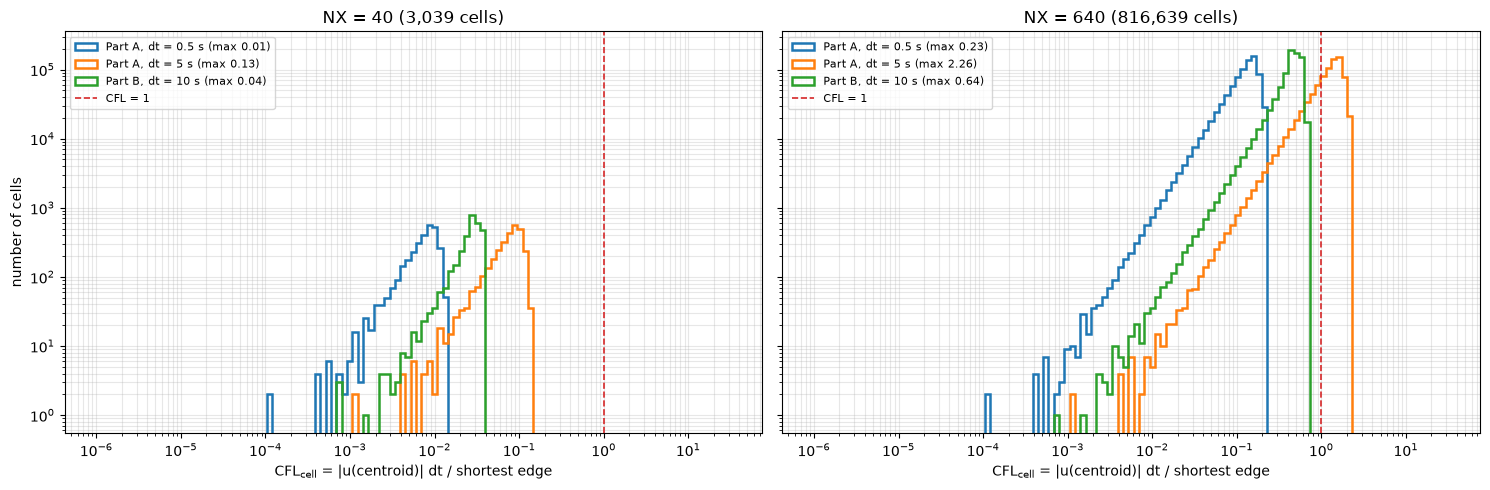

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
bins = np.logspace(-6, 1.5, 120)
for ax, nx in zip(axes, [40, 640]):
    for (flow, dt, col) in [("A", DT_S, "C0"), ("A", DT_VIS_A, "C1"), ("B", DT_VIS_B, "C2")]:
        ax.hist(cfl_cells(flow, nx, dt), bins=bins, histtype="step", lw=1.8, color=col,
                label=f"Part {flow}, dt = {dt:g} s (max {cfl_cells(flow, nx, dt).max():.2f})")
    ax.axvline(1, color="C3", lw=1.2, ls="--", label="CFL = 1")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"CFL$_\mathrm{cell}$ = |u(centroid)| dt / shortest edge")
    ax.set_title(f"NX = {nx} ({GRIDS[nx].n_face:,} cells)"); ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel("number of cells")
plt.tight_layout(); plt.show()

**What to look for (CFL).** Part A speed grows linearly with distance from the stagnation point, so the CFL distribution
spans orders of magnitude, with the maximum in the domain corners; Part B speed is bounded by $U_0$. The production
choices (Part A 0.5 s, Part B 10 s) stay below CFL 1 on every grid. The Part A visualisation step (5 s) exceeds CFL 1 on
the finest grids near the corners, but the visualisation particles never go there (compare *all* vs *visited* and the
particle-based maximum). $|\nabla\mathbf u|\Delta t\le0.71$ in every run (largest: Part B fixed CFL at $N_X=10$, $\Delta t=560$ s), well inside the RK4 stability limit of about 2.8, so none of these cases is an RK4 stability problem; the large-$\Delta t$ runs are inaccurate, not unstable.

## 6e. Status codes, out-of-bounds and search checks (v2)

For every `pset.execute` in this notebook: the particle `StatusCode` counts (must be `Success` or `EndofLoop` only,
with no exception), the number of recorded positions outside $[-5,5]^2$ and the number not found in any triangle by
`grid.search` (must both be 0). The missing corner triangles per $N_X$ are listed in Section 2.

In [35]:
run_rows = []
for k, r in RESULTS.items():
    run_rows.append({"flow": k[0], "NX": k[1], "scheme": k[2], "dt [s]": k[3], "T [s]": k[4], "pset": k[5],
                     "purpose": "; ".join(sorted(PURPOSE[k])), "particles": r["n_particles"], "steps": r["n_steps"],
                     "states": states_str(r), "exception": r["error"], "positions outside box": r["n_outside_box"],
                     "positions not in a triangle": r["n_not_found"],
                     "clean": r["error"] is None and set(r["states"]) <= {"Success", "EndofLoop"}})
df_runs = pd.DataFrame(run_rows)
ok_state = df_runs["clean"]
ok_pos = (df_runs["positions outside box"] == 0) & (df_runs["positions not in a triangle"] == 0)
STATUS_OK, POSITIONS_OK = bool(ok_state.all()), bool(ok_pos.all())
print(f"{len(df_runs)} Parcels runs, {int((df_runs['particles'] * df_runs['steps']).sum()):,} particle-steps checked")
print(f"all particles Success/EndofLoop, no exception: {STATUS_OK}")
print(f"no recorded position outside [-5,5]^2 or outside the triangulation: {POSITIONS_OK}")
FAILED_RUNS = df_runs[~(ok_state & ok_pos)]
if len(FAILED_RUNS):
    print("Runs with an error (their trajectory metrics are set to NaN in Sections 6b-6c):")
    display(FAILED_RUNS[["flow", "NX", "scheme", "dt [s]", "purpose", "states", "exception"]])
# Known, documented failure (see the note below): constant-face Part B on the NX = 20 grid. Anything else is unexpected.
KNOWN_FAILURE = bool(len(FAILED_RUNS)) and bool(((FAILED_RUNS["flow"] == "B") & (FAILED_RUNS["scheme"] == "constant (face)")
                                                  & (FAILED_RUNS["NX"] <= 20)).all())
assert POSITIONS_OK, "recorded particle positions left the domain or the triangulation"
assert STATUS_OK or KNOWN_FAILURE, "unexpected particle error states (see table above)"
df_runs.groupby(["purpose", "states"], dropna=False).agg(runs=("steps", "size"), particle_steps=("steps", lambda s: int((s * df_runs.loc[s.index, "particles"]).sum())))

180 Parcels runs, 68,517,372 particle-steps checked
all particles Success/EndofLoop, no exception: False
no recorded position outside [-5,5]^2 or outside the triangulation: True
Runs with an error (their trajectory metrics are set to NaN in Sections 6b-6c):


,flow,NX,scheme,dt [s],purpose,states,exception
47,B,20,constant (face),1.000e+01,B: trajectories (vis + reference study),"Evaluate:505, ErrorGridSearching:1 +EXCEPTION",GridSearchingError: Grid searching failed at (...
63,B,20,constant (face),2.637e+02,B: fixed CFL 0.5,"Evaluate:505, ErrorGridSearching:1 +EXCEPTION",GridSearchingError: Grid searching failed at (...


,,runs,particle_steps
purpose,states,,
A: dt check (NX=40),EndofLoop:2018,3,3269160
A: dt check (NX=40); A: dt halving,EndofLoop:2018,2,1089720
A: dt check (NX=40); A: dt halving; A: sweep,EndofLoop:2018,1,1452960
A: dt halving,EndofLoop:2018,46,13464096
A: dt halving; A: sweep,EndofLoop:2018,11,15982560
A: fixed CFL 0.5,EndofLoop:2018,21,3892722
A: sweep,EndofLoop:2018,9,13076640
A: visualisation,EndofLoop:6,12,36288
B: dt halving,EndofLoop:506,33,7600626


**Result (Section 6e).** Every recorded position of every run lies inside $[-5,5]^2$ and inside the triangulation, and all
runs end with every particle in `EndofLoop` — **except two Part B runs of the constant-face scheme on the $N_X=20$ grid**
($\Delta t=10$ s and the fixed-CFL $\Delta t=264$ s). There, one of the 500 reference particles, started in a central cell,
is carried across the separatrices by the piecewise-constant field (two to three faces per half-cell) and reaches the
boundary $y=-5$; the RK4 stage position then falls outside the mesh, Parcels raises `GridSearchingError` and aborts the whole
`execute`. This is a genuine failure of the scheme on that grid (the exact orbit stays in its cell), not a search bug: the
last recorded positions are still inside the triangulation. It is counted as a FAIL in check 7 and documented below; the
metrics of these two aborted runs are set to NaN (they do not enter any slope fit, which uses $N_X\ge80$). On $N_X=10$
the same scheme keeps all particles in the domain over 6000 s, by chance of the face layout.

## 6f. Constant-face trajectory slope — follow-up study for check 4c (v2)

Check 4c (pre-registered: $|p-1|<0.3$ for the slope of the mean constant-face trajectory error, $N_X\ge80$, 18 particles)
fails with $p\approx1.8$. The v1 explanation — error cancellation along paths that cross many cells — is plausible, but in
$T=360$ s the near-origin particles move only ~0.04 length units, less than one cell on coarse grids. Follow-up: 2000
particles uniform in $[-3,3]^2$, integrated in the same runs ($T=360$ s, $\Delta t=0.5$ s). $T=360$ s keeps every particle in
the domain ($|x(T)|\le3e^{0.36}=4.3$, outside the missing corners) and the median particle crosses well over 10 cells on the
finest grid (asserted below). Cells crossed per particle are counted from the face index at every step of the least-squares
run (the path of an exact scheme). The slope's 95 % confidence interval comes from a bootstrap over particles (2000 resamples).

In [36]:
B_BOOT = 2000
rng_boot = np.random.default_rng(42)
asym = [nx for nx in NX_VALUES if nx >= ASYMPTOTIC_NX]
logdx = np.log([DX[nx] for nx in asym])


def slope_rows(E):
    # E: (n_boot, n_nx) mean errors -> fitted slopes of log(E) vs log(dx)
    y = np.log(E)
    return ((logdx - logdx.mean()) * (y - y.mean(axis=1, keepdims=True))).sum(axis=1) / ((logdx - logdx.mean()) ** 2).sum()


follow_rows, slope_rows_out = [], []
for nx in NX_VALUES:
    r_c, r_l = SW[(nx, "constant (face)")], SW[(nx, "least-squares (face)")]
    cf, co = r_l["crossings"][IDX_FOLLOW], r_l["crossings"][IDX_ORIG]
    follow_rows.append({"NX": nx, "dx": DX[nx], "const mean err (2000)": err_A(r_c, IDX_FOLLOW).mean(),
                        "const mean err (18)": err_A(r_c).mean(),
                        "cells crossed (2000): median": np.median(cf), "p10": np.percentile(cf, 10), "p90": np.percentile(cf, 90),
                        "cells crossed (18): median": np.median(co), "(18): near-origin max": co[:6].max(),
                        "(18) with < 1 crossing": int(np.sum(co < 1))})
df_follow = pd.DataFrame(follow_rows)
for label, idx in [("2000 particles in [-3,3]^2", IDX_FOLLOW), ("18 T1-4 particles (check 4c)", IDX_ORIG)]:
    E = np.array([err_A(SW[(nx, "constant (face)")], idx) for nx in asym]).T          # (n_particles, n_nx)
    p_hat = slope_rows(E.mean(axis=0)[None, :])[0]
    boot = slope_rows(np.stack([E[rng_boot.integers(0, E.shape[0], E.shape[0])].mean(axis=0) for _ in range(B_BOOT)]))
    lo, hi = np.percentile(boot, [2.5, 97.5])
    slope_rows_out.append({"particles": label, f"slope (NX>={ASYMPTOTIC_NX})": p_hat, "95% CI low": lo, "95% CI high": hi,
                           "CI contains 1": bool(lo <= 1 <= hi), "CI contains 2": bool(lo <= 2 <= hi)})
df_slope4c = pd.DataFrame(slope_rows_out)
med640 = df_follow.set_index("NX").loc[640, "cells crossed (2000): median"]
print(f"median cells crossed at NX=640: {med640:.0f} (requirement: >= 10)")
assert med640 >= 10, "T too short for the follow-up study"
display(df_follow)
df_slope4c

median cells crossed at NX=640: 116 (requirement: >= 10)


,NX,dx,const mean err (2000),const mean err (18),cells crossed (2000): median,p10,p90,cells crossed (18): median,(18): near-origin max,(18) with < 1 crossing
0,10,1.111e+00,7.240e-02,6.394e-02,2.000e+00,0.000e+00,3.000e+00,5.000e-01,1,9
1,20,5.263e-01,2.425e-02,3.412e-02,4.000e+00,2.000e+00,6.000e+00,2.500e+00,1,4
2,40,2.564e-01,8.051e-03,1.504e-02,7.000e+00,3.000e+00,1.100e+01,5.500e+00,2,2
3,80,1.266e-01,2.790e-03,4.958e-03,1.500e+01,6.000e+00,2.200e+01,9.000e+00,2,5
4,160,6.289e-02,9.243e-04,2.056e-03,3.000e+01,1.300e+01,4.400e+01,1.800e+01,5,0
5,320,3.135e-02,2.951e-04,4.177e-04,5.900e+01,2.700e+01,8.700e+01,3.600e+01,9,0
6,640,1.565e-02,9.774e-05,1.318e-04,1.160e+02,5.200e+01,1.680e+02,7.500e+01,11,0


,particles,slope (NX>=80),95% CI low,95% CI high,CI contains 1,CI contains 2
0,"2000 particles in [-3,3]^2",1.607e+00,1.579e+00,1.636e+00,False,False
1,18 T1-4 particles (check 4c),1.790e+00,1.542e+00,2.104e+00,False,True


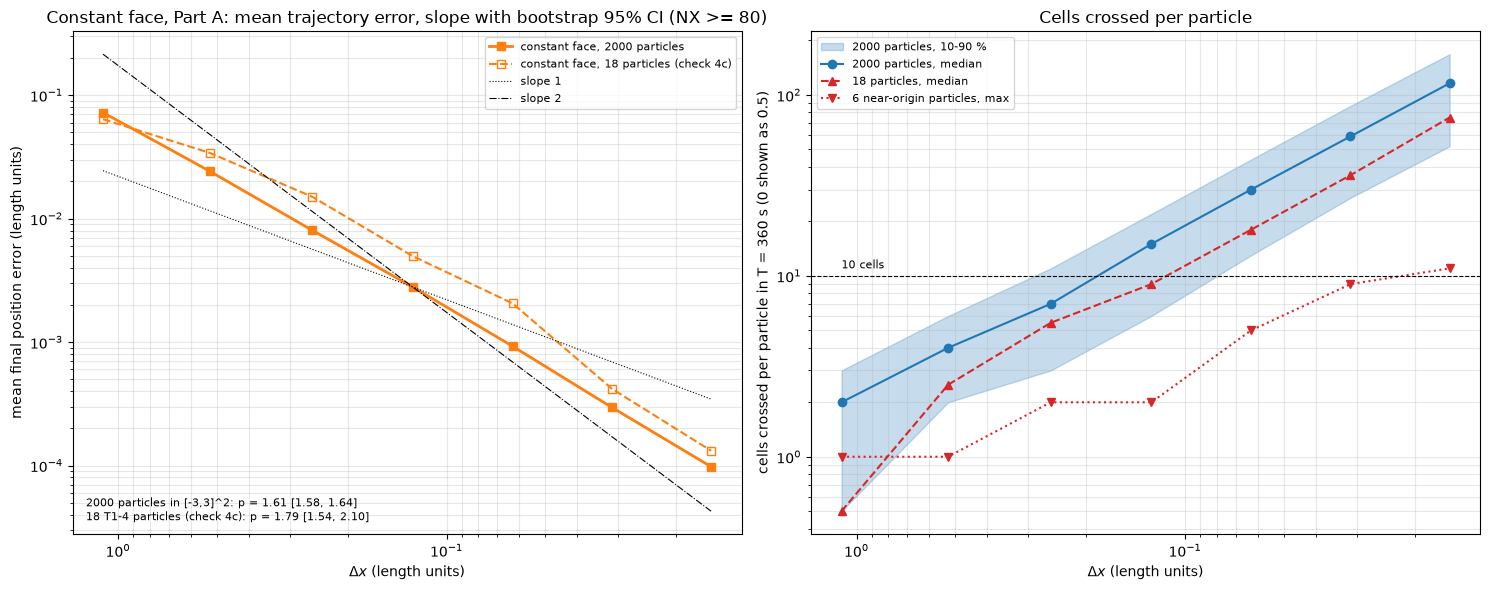

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
ax.loglog(df_follow["dx"], df_follow["const mean err (2000)"], "s-", color="C1", lw=2, label="constant face, 2000 particles")
ax.loglog(df_follow["dx"], df_follow["const mean err (18)"], "s--", color="C1", mfc="none", label="constant face, 18 particles (check 4c)")
for order, ls in [(1, ":"), (2, "-.")]:
    y0 = df_follow["const mean err (2000)"].iloc[3]
    ax.loglog(dxs, y0 * (dxs / DX[ASYMPTOTIC_NX]) ** order, "k", ls=ls, lw=0.8, label=f"slope {order}")
txt = "\n".join(f"{r['particles']}: p = {r[f'slope (NX>={ASYMPTOTIC_NX})']:.2f} [{r['95% CI low']:.2f}, {r['95% CI high']:.2f}]"
                for _, r in df_slope4c.iterrows())
ax.text(0.02, 0.02, txt, transform=ax.transAxes, fontsize=8, va="bottom")
ax.set_xlabel(r"$\Delta x$ (length units)"); ax.set_ylabel("mean final position error (length units)"); ax.invert_xaxis()
ax.set_title("Constant face, Part A: mean trajectory error, slope with bootstrap 95% CI (NX >= 80)")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
ax = axes[1]
ax.fill_between(df_follow["dx"], df_follow["p10"].clip(lower=0.5), df_follow["p90"], color="C0", alpha=0.25, label="2000 particles, 10-90 %")
ax.loglog(df_follow["dx"], df_follow["cells crossed (2000): median"].clip(lower=0.5), "o-", color="C0", label="2000 particles, median")
ax.loglog(df_follow["dx"], df_follow["cells crossed (18): median"].clip(lower=0.5), "^--", color="C3", label="18 particles, median")
ax.loglog(df_follow["dx"], df_follow["(18): near-origin max"].clip(lower=0.5), "v:", color="C3", label="6 near-origin particles, max")
ax.axhline(10, color="k", lw=0.8, ls="--"); ax.text(DX[10], 11, "10 cells", fontsize=8)
ax.set_xlabel(r"$\Delta x$ (length units)"); ax.set_ylabel("cells crossed per particle in T = 360 s (0 shown as 0.5)")
ax.set_title("Cells crossed per particle"); ax.invert_xaxis(); ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to look for (follow-up 4c).** Left: if the many-cell cancellation argument holds, the 2000-particle mean error
(particles crossing tens to hundreds of cells) converges faster than first order with a tight confidence interval; if the
order is really 1, its CI contains 1. Right: the 18 T1-4 particles, and especially the 6 near-origin ones, cross few or
no cells on the coarse grids, so their mean error is dominated by a handful of particles whose paths sit in one or two
cells — a regime where neither first-order nor cancellation asymptotics apply.

## 6g. Fair timing (v2)

All wall times elsewhere in this notebook are **implementation-dependent, not a cost comparison of the methods**:
`LinearFaceRecon` reads `field.data.values` into NumPy, while the built-in interpolators go through `xarray.isel`, and the
trajectory runs here are concurrent. The cell below times only the interpolation, `fieldset.U.eval`, on $10^5$ random points
in $[-3.5,3.5]^2$ (median of 7 repeats, one process), and separates the search (`grid.search`) from the interpolation
(eval minus search). It also times a **proposed** `LinearFaceReconCached`, identical to `LinearFaceRecon` except that the
field arrays are cached on first use instead of re-read with `np.asarray(field.data.values)` on every call, and checks
that it is bit-identical (it is not used for any result in this notebook).

In [38]:
class LinearFaceReconCached(LinearFaceRecon):
    # Proposal: same math as LinearFaceRecon; the (time, zc, n_face) array is cached per field instead of re-read per call.
    def __init__(self, uxgrid, spherical=False):
        super().__init__(uxgrid, spherical)
        self._data = {}

    def interp(self, particle_positions, grid_positions, field):
        ti, zi, fi = np.broadcast_arrays(
            grid_positions["T"]["index"], grid_positions["Z"]["index"], grid_positions["FACE"]["index"]
        )
        data = self._data.get(field.name)
        if data is None:
            data = self._data[field.name] = np.asarray(field.data.values)

        u_c = data[ti, zi, fi]
        u_k = data[ti[:, None], zi[:, None], self.neighbors[fi]]
        du = (u_k - u_c[:, None]) * self.mask[fi]
        a_x = np.sum(self.gx[fi] * du, axis=1)
        a_y = np.sum(self.gy[fi] * du, axis=1)

        dx, dy = self._offsets(self.face_x[fi], self.face_y[fi],
                               particle_positions["x"], particle_positions["y"])
        return u_c + a_x * dx + a_y * dy


N_TIME, REPEATS = 100_000, 7
rng_t = np.random.default_rng(11)
xt_, yt_ = rng_t.uniform(-3.5, 3.5, N_TIME), rng_t.uniform(-3.5, 3.5, N_TIME)
zt_ = np.full(N_TIME, 0.5)


def median_time(f):
    ts = []
    for _ in range(REPEATS):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))


time_rows, cached_identical = [], True
for nx in NX_VALUES:
    ds_node, ds_face = make_dataset(GRIDS[nx], cellular_uv, "node"), make_dataset(GRIDS[nx], cellular_uv, "face")
    fss = {s: make_fieldset(s, ds_node, ds_face) for s in SCHEMES}
    fs_c = parcels.FieldSet.from_ugrid_conventions(ds_face, mesh="flat")
    rc = LinearFaceReconCached(fs_c.fields["U"].grid.uxgrid, spherical=False)
    fs_c.fields["U"].interp_method = rc; fs_c.fields["V"].interp_method = rc
    fss["least-squares (face), cached (proposal)"] = fs_c
    for s, fs in fss.items():
        fs.U.eval(0.0, zt_, yt_, xt_)                                          # warm-up (spatial hash, caches)
        t_s = median_time(lambda: fs.U.grid.search(zt_, yt_, xt_))
        t_e = median_time(lambda: fs.U.eval(0.0, zt_, yt_, xt_))
        time_rows.append({"NX": nx, "scheme": s, "search [ms]": 1e3 * t_s, "eval [ms]": 1e3 * t_e,
                          "interpolation = eval - search [ms]": 1e3 * (t_e - t_s)})
    for comp in ["U", "V"]:
        a = fss["least-squares (face)"].fields[comp].eval(0.0, zt_, yt_, xt_)
        b = fs_c.fields[comp].eval(0.0, zt_, yt_, xt_)
        cached_identical &= bool(np.array_equal(a, b))
df_time = pd.DataFrame(time_rows)
print("Implementation-dependent timings (one process, 1e5 points, median of 7), not a cost comparison of the methods.")
print("Measured on a shared login node: differences of a few ms (and a negative 'eval - search') are timing noise.")
print(f"LinearFaceReconCached bit-identical to LinearFaceRecon on 1e5 points, U and V, every NX: {cached_identical}")
assert cached_identical
df_time.pivot(index="NX", columns="scheme", values=["search [ms]", "interpolation = eval - search [ms]"])

Implementation-dependent timings (one process, 1e5 points, median of 7), not a cost comparison of the methods.
Measured on a shared login node: differences of a few ms (and a negative 'eval - search') are timing noise.
LinearFaceReconCached bit-identical to LinearFaceRecon on 1e5 points, U and V, every NX: True


search [ms]                                       \
scheme barycentric (node) constant (face) least-squares (face)   
NX                                                               
10              5.303e+01       5.325e+01            5.313e+01   
20              5.430e+01       5.437e+01            5.441e+01   
40              5.621e+01       5.571e+01            5.627e+01   
80              5.955e+01       5.994e+01            5.965e+01   
160             6.698e+01       6.720e+01            6.733e+01   
320             8.471e+01       8.492e+01            8.599e+01   
640             1.263e+02       1.262e+02            1.267e+02   

                                                \
scheme least-squares (face), cached (proposal)   
NX                                               
10                                   5.360e+01   
20                                   5.472e+01   
40                                   5.591e+01   
80                                   5.959e+01   
160                                  6.742e+01   
320                                  8.537e+01   
640                                  1.258e+02   

       interpolation = eval - search [ms]                  \
scheme                 barycentric (node) constant (face)   
NX                                                          
10                              1.004e+01       3.889e+00   
20                              9.678e+00       3.784e+00   
40                              9.933e+00       3.786e+00   
80                              9.808e+00       2.769e+00   
160                             1.014e+01       3.856e+00   
320                             1.180e+01       4.537e+00   
640                             1.354e+01       6.939e+00   

                                                                     
scheme least-squares (face) least-squares (face), cached (proposal)  
NX                                                                   
10                5.310e+01                               1.359e+01  
20                1.425e+01                               1.353e+01  
40                1.464e+01                               1.385e+01  
80                1.526e+01                               1.436e+01  
160               1.756e+01                               1.664e+01  
320               2.284e+01                               2.204e+01  
640               3.389e+01                               3.309e+01

## 7. Results Summary

In [39]:
summary = df_A[["NX", "dx", "scheme", "interp_max_rel", "interp_rms_rel", "traj_mean", "traj_max", "states", "wall_s"]].merge(
    df_B[["NX", "scheme", "interp_max_rel", "interp_rms_rel"]].rename(
        columns={"interp_max_rel": "B_interp_max_rel", "interp_rms_rel": "B_interp_rms_rel"}),
    on=["NX", "scheme"])
summary = summary.rename(columns={"interp_max_rel": "A_interp_max_rel", "interp_rms_rel": "A_interp_rms_rel",
                                  "traj_mean": "A_traj_mean", "traj_max": "A_traj_max",
                                  "wall_s": "A_traj_wall_s [impl.-dependent]"})
summary = summary.merge(df_B6[["NX", "scheme", "traj_mean", "psi_drift_max"]].rename(
    columns={"traj_mean": "B_traj_mean_vs_ref", "psi_drift_max": "B_psi_drift_max"}), on=["NX", "scheme"])
summary.sort_values(["scheme", "NX"]).reset_index(drop=True)

,NX,dx,scheme,A_interp_max_rel,A_interp_rms_rel,A_traj_mean,A_traj_max,states,A_traj_wall_s [impl.-dependent],B_interp_max_rel,B_interp_rms_rel,B_traj_mean_vs_ref,B_psi_drift_max
0,10,1.111e+00,barycentric (node),6.346e-08,1.722e-08,3.014e-10,7.315e-10,EndofLoop:2018,2.079e+01,5.758e-01,2.446e-01,1.557e+00,1.103e+00
1,20,5.263e-01,barycentric (node),5.727e-08,1.713e-08,3.042e-10,6.880e-10,EndofLoop:2018,2.031e+01,1.466e-01,6.016e-02,3.087e-01,1.217e-01
2,40,2.564e-01,barycentric (node),5.743e-08,1.719e-08,3.016e-10,7.417e-10,EndofLoop:2018,2.041e+01,3.633e-02,1.468e-02,6.591e-02,2.104e-02
3,80,1.266e-01,barycentric (node),6.257e-08,1.716e-08,2.976e-10,6.863e-10,EndofLoop:2018,2.064e+01,8.844e-03,3.599e-03,1.764e-02,3.540e-03
4,160,6.289e-02,barycentric (node),6.472e-08,1.724e-08,3.027e-10,6.829e-10,EndofLoop:2018,2.066e+01,2.200e-03,8.946e-04,4.255e-03,7.021e-04
5,320,3.135e-02,barycentric (node),6.268e-08,1.705e-08,2.953e-10,7.926e-10,EndofLoop:2018,2.133e+01,5.469e-04,2.225e-04,1.074e-03,9.115e-05
6,640,1.565e-02,barycentric (node),5.919e-08,1.700e-08,3.443e-10,8.101e-10,EndofLoop:2018,2.231e+01,1.352e-04,5.538e-05,2.665e-04,1.915e-05
7,10,1.111e+00,constant (face),1.668e-01,7.268e-02,6.394e-02,1.769e-01,EndofLoop:2018,1.635e+01,9.572e-01,3.133e-01,1.448e+00,9.661e-01
8,20,5.263e-01,constant (face),7.912e-02,3.604e-02,3.412e-02,7.492e-02,EndofLoop:2018,1.629e+01,4.682e-01,1.573e-01,NaN,NaN
9,40,2.564e-01,constant (face),3.827e-02,1.744e-02,1.504e-02,6.057e-02,EndofLoop:2018,1.652e+01,2.290e-01,7.664e-02,1.644e-01,1.471e-01


## 8. Verification Assertions

Thresholds (fixed before running the sweep):

1. **least-squares, linear field, direct error** — relative error `< 1e-14` at every $N_X$. float64 eps is $2.2\times10^{-16}$;
   the reconstruction does $O(10)$ flops per point, so `1e-14` (~45 eps) allows for round-off but not for any
   truncation error.
2. **least-squares, linear field, trajectory** — max position error `< 1e-13` length units at every $N_X$. Worst-case linear
   accumulation of one ulp per step over 720 steps at $|x|\le4.3$ ($\mathrm{ulp}=8.9\times10^{-16}$) is $6\times10^{-13}$;
   `1e-13` is ~110 ulp of the largest position, and the time error at $\Delta t=0.5$ s is $\lesssim10^{-16}$ (Section 4).
3. **barycentric node, linear field** — relative direct error `< 1e-6` at every $N_X$, i.e. exact up to the float32
   weights (eps32 = $1.2\times10^{-7}$, times a factor < 10 for the 3-term sum).
   *Informational (not counted):* the error is flat with resolution (finest/coarsest within a factor 10), documenting
   the Parcels float32 floor; this check is expected to change once Parcels computes the weights in float64.
4. **constant face, linear field** — fitted slope ($N_X\ge80$) of the direct max and RMS relative errors, and of the mean
   trajectory error, within 0.3 of 1.
5. **nonlinear field orders** ($N_X\ge80$, max and RMS relative errors) — constant face within 0.3 of 1;
   barycentric node and least-squares within 0.3 of 2.
6. **ordering** — at every $N_X$ on the linear field: least-squares < barycentric node < constant face (direct max error).

**v2 additions (new checks, numbered after the pre-registered ones; thresholds 1-6 are unchanged):**

7. every `pset.execute` ended with all particles in `Success`/`EndofLoop` and no exception (Section 6e);
8. no recorded position outside $[-5,5]^2$ or outside the triangulation (Section 6e);
9. both stream functions reproduce the velocity with $u=-\partial_y\psi,\ v=\partial_x\psi$ to $<10^{-10}$ (Section 2b).

Check **4c** (constant-face trajectory slope) is a documented, pre-registered failure under investigation (Section 6f):
it stays in the table as FAIL, but the cell does not raise for it. Check **7** fails for one documented reason only
(constant face, Part B, $N_X=20$: a particle leaves the domain, Section 6e) and is treated the same way; the cell raises if
any other check fails, or if check 7 fails for any other run.

In [40]:
check_rows = []


def check(cid, ok, msg, counted=True):
    tag = ("PASS" if ok else "FAIL") if counted else ("INFO-yes" if ok else "INFO-no")
    check_rows.append({"id": cid, "check": msg, "result": tag})
    print(f"  [{tag}] {cid}: {msg}")


def slope_of(df_fit, scheme, metric):
    return df_fit[(df_fit["scheme"] == scheme) & (df_fit["metric"] == metric)][f"slope (NX>={ASYMPTOTIC_NX})"].iloc[0]


A = {s: df_A[df_A["scheme"] == s].set_index("NX") for s in SCHEMES}

print("=== 1. least-squares, linear field: direct error at machine precision ===")
for nx in NX_VALUES:
    e = A["least-squares (face)"].loc[nx, "interp_max_rel"]
    check("1", e < 1e-14, f"NX={nx}: LSQ direct max rel error {e:.2e} < 1e-14")

print("\n=== 2. least-squares, linear field: trajectory error at round-off ===")
for nx in NX_VALUES:
    e = A["least-squares (face)"].loc[nx, "traj_max"]
    check("2", e < 1e-13, f"NX={nx}: LSQ trajectory max error {e:.2e} length units < 1e-13")

print("\n=== 3. barycentric node, linear field: exact up to float32 weights ===")
for nx in NX_VALUES:
    e = A["barycentric (node)"].loc[nx, "interp_max_rel"]
    check("3", e < 1e-6, f"NX={nx}: node direct max rel error {e:.2e} < 1e-6")
en = A["barycentric (node)"]["interp_max_rel"]
check("3-info", en.iloc[0] / en.iloc[-1] < 10,
      f"node error flat with NX (Parcels float32 floor): coarsest/finest = {en.iloc[0] / en.iloc[-1]:.2f} < 10",
      counted=False)

print("\n=== 4. constant face, linear field: first order ===")
for cid, metric in [("4a", "interp_max_rel"), ("4b", "interp_rms_rel"), ("4c", "traj_mean")]:
    p = slope_of(df_fit_A, "constant (face)", metric)
    check(cid, abs(p - 1) < 0.3, f"constant (face) {metric}: slope {p:.2f}, |p - 1| < 0.3")

print("\n=== 5. nonlinear field: convergence orders ===")
for scheme, expected in [("constant (face)", 1), ("barycentric (node)", 2), ("least-squares (face)", 2)]:
    for metric in ["interp_max_rel", "interp_rms_rel"]:
        p = slope_of(df_fit_B, scheme, metric)
        check("5", abs(p - expected) < 0.3, f"{scheme} {metric}: slope {p:.2f}, |p - {expected}| < 0.3")

print("\n=== 6. ordering on the linear field ===")
for nx in NX_VALUES:
    l, n, c = (A[s].loc[nx, "interp_max_rel"] for s in ["least-squares (face)", "barycentric (node)", "constant (face)"])
    check("6", l < n < c, f"NX={nx}: LSQ {l:.1e} < node {n:.1e} < constant {c:.1e}")

print("\n=== 7-9. v2 checks ===")
check("7", STATUS_OK, f"{len(df_runs)} runs: all particles Success/EndofLoop, no exception")
check("8", POSITIONS_OK, "no recorded position outside [-5,5]^2 or outside the triangulation")
check("9", max(PSI_CHECK.values()) < 1e-10, f"psi convention u = -dpsi/dy, v = dpsi/dx: max rel diff {max(PSI_CHECK.values()):.1e}")
r4 = df_slope4c.iloc[0]
check("4c-info", r4["CI contains 1"], f"follow-up (2000 particles): slope {r4[f'slope (NX>={ASYMPTOTIC_NX})']:.2f}, "
      f"95% CI [{r4['95% CI low']:.2f}, {r4['95% CI high']:.2f}] contains 1", counted=False)

df_checks = pd.DataFrame(check_rows)
failed = df_checks[df_checks["result"] == "FAIL"]
print()
print(f"{(df_checks['result'] == 'PASS').sum()} PASS, {len(failed)} FAIL ({', '.join(failed['id']) or 'none'})")
DOCUMENTED = {"4c"} | ({"7"} if KNOWN_FAILURE else set())
if (~failed["id"].isin(DOCUMENTED)).any():
    raise AssertionError("T1-4c FAILED: a check other than the documented ones exceeded tolerance (see FAIL lines above).")
elif len(failed):
    print(f"T1-4c: all counted checks pass except the documented failures {sorted(DOCUMENTED)}: 4c (pre-registered, "
          "under investigation, Section 6f) and 7 (constant face leaves the domain in Part B at NX = 20, Section 6e).")
else:
    print("T1-4c PASSED: all counted checks within tolerance.")

=== 1. least-squares, linear field: direct error at machine precision ===
  [PASS] 1: NX=10: LSQ direct max rel error 1.81e-16 < 1e-14
  [PASS] 1: NX=20: LSQ direct max rel error 1.97e-16 < 1e-14
  [PASS] 1: NX=40: LSQ direct max rel error 1.77e-16 < 1e-14
  [PASS] 1: NX=80: LSQ direct max rel error 1.81e-16 < 1e-14
  [PASS] 1: NX=160: LSQ direct max rel error 1.76e-16 < 1e-14
  [PASS] 1: NX=320: LSQ direct max rel error 1.76e-16 < 1e-14
  [PASS] 1: NX=640: LSQ direct max rel error 1.81e-16 < 1e-14

=== 2. least-squares, linear field: trajectory error at round-off ===
  [PASS] 2: NX=10: LSQ trajectory max error 3.11e-15 length units < 1e-13
  [PASS] 2: NX=20: LSQ trajectory max error 3.11e-15 length units < 1e-13
  [PASS] 2: NX=40: LSQ trajectory max error 3.11e-15 length units < 1e-13
  [PASS] 2: NX=80: LSQ trajectory max error 3.11e-15 length units < 1e-13
  [PASS] 2: NX=160: LSQ trajectory max error 3.11e-15 length units < 1e-13
  [PASS] 2: NX=320: LSQ trajectory max error 3.11e-15 

### Note on check 4c (constant-face trajectory slope) — documented, pre-registered failure under investigation

The threshold ($|p-1|<0.3$ for the mean trajectory error of the 18 particles, $N_X\ge80$) was fixed before the run and is
unchanged; the check FAILS with $p=1.79$ (bootstrap 95 % CI over the 18 particles $[1.54, 2.10]$). The direct velocity error
of the same scheme is cleanly first order (checks 4a, 4b and 5).

v1 explained this by error cancellation: for a linear field the centroid value equals the cell average, so the
piecewise-constant velocity error changes sign within each cell and largely cancels along a path that crosses many cells.
The follow-up study (Section 6f) tests that argument:

* The 18 particles are a poor sample for it: in $T=360$ s the near-origin particles cross at most 1-2 cells for
  $N_X\le80$, and 4-9 of the 18 cross none at all on the three coarsest grids, so the slope is set by a few particles.
* With 2000 particles in $[-3,3]^2$ (median 15 cells crossed at $N_X=80$, 116 at $N_X=640$) the mean error converges with
  slope $1.61$, 95 % CI $[1.58, 1.64]$: clearly **faster than first order** (the CI excludes 1), but also **not second order**
  (the CI excludes 2).

This supports partial cancellation (a $O(\Delta x^2)$ part from the many fully traversed cells plus a smaller
$O(\Delta x)$ part from partially traversed cells and from the start/end cells), not a defect of the scheme. The
pre-registered expectation of order 1 for the trajectory error was therefore too pessimistic, and the 18-particle estimate
is too noisy to decide between 1.5 and 2. Open points: the effective order should drift towards 1 as $T$ (and the share of
partial cells) shrinks and towards 2 as $T$ grows; this $T$ dependence has not been tested yet.

## 9. Runtime and cleanup

No particle files are written by this notebook (trajectory errors use the final `pset.x`/`pset.y` only),
so there is nothing to delete.

v2: the same holds (positions are kept in memory by the `Recorder` kernel).

In [41]:
print(f"Parcels runs: {len(RESULTS)}, summed per-run wall time {sum(r['wall'] for r in RESULTS.values()):.0f} s "
      f"(implementation-dependent, executed concurrently on up to {N_WORKERS} processes)")
print(f"Total notebook wall time: {time.time() - NOTEBOOK_T0:.0f} s")
leftover = [f for f in os.listdir(".") if f.startswith("T1_4c") and f.endswith(".parquet")]
print("leftover T1_4c parquet files:", leftover)

Parcels runs: 180, summed per-run wall time 1416 s (implementation-dependent, executed concurrently on up to 24 processes)
Total notebook wall time: 260 s
leftover T1_4c parquet files: []
